<a href="https://colab.research.google.com/github/nour769/3DGS-Localization/blob/main/MorphoRT_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MorphoRT — Segmentation morphologique, analyse de forme et modélisation

**ENSI · Wiem Ben El Haj Salah Bouhdid & Nour Mrabet**

Ce notebook reprend l'ordre scientifique du projet : **IRM BraTS → segmentation par morphologie mathématique → validation et mesures de forme → données longitudinales LUMIERE → modèles de croissance → simulation LQ**.

L'objectif principal de la première partie est de rendre chaque opération morphologique visible sur les IRM : seuillage, érosion, dilatation, ouverture, fermeture, remplissage, composantes connexes et gradient morphologique. Chaque résultat intermédiaire est affiché sur la même coupe FLAIR pour que son effet soit interprétable devant le jury.

> **Important :** il s'agit d'une méthode morphologique classique et interprétable, pas d'un système clinique. Les résultats dépendent des données, du seuil et de l'élément structurant. Le notebook ne fabrique ni annotations, ni volumes longitudinaux, ni paramètres radiobiologiques.

## 1. Préparer l'environnement

Cette première cellule installe les bibliothèques nécessaires dans Google Colab. `nibabel` lit les volumes NIfTI, `scikit-image` fournit les opérations morphologiques, `scipy` traite les composantes connexes et ajuste les modèles, et `matplotlib` produit les visualisations.

In [ ]:
!pip -q install nibabel scikit-image scipy pandas matplotlib openpyxl pyarrow

## 2. Importer les bibliothèques et fixer la reproductibilité

Nous centralisons les imports et fixons une graine aléatoire. Les opérations morphologiques sont déterministes, mais la graine rend reproductibles les éventuelles étapes numériques utilisant de l'aléatoire.

In [ ]:
import os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from scipy import ndimage
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit, minimize
from skimage import measure, morphology

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "gray"

print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)
print("Notebook prêt.")

NumPy : 2.4.6
Pandas : 2.2.3
Notebook prêt.


## 3. Connecter Google Drive et conserver les chemins du notebook initial

Les chemins sont conservés tels quels :
- dossier projet : `/content/drive/MyDrive/MorphoRT`
- BraTS : `MorphoRT/brats`
- LUMIERE : `MorphoRT/brats/lumiere`

La cellule vérifie les dossiers avant de poursuivre. Si Google Drive demande une autorisation, validez-la dans Colab.

In [ ]:
from pathlib import Path
import zipfile

BASE_DIR = Path("/content/drive/MyDrive/MorphoRT")
BRATS_DIR = BASE_DIR / "brats"

# Dossiers de destination
PETITZIPBRATS_DIR = BRATS_DIR / "petitzipbrats"
LUMIERE_DIR = BRATS_DIR / "lumiere"

# Archives ZIP
BRATS_ZIP = BRATS_DIR / "petitzipbrats.zip"
LUMIERE_ZIP = BRATS_DIR / "lumiere.zip"

# Vérification des archives
assert BRATS_ZIP.is_file(), f"Archive introuvable : {BRATS_ZIP}"
assert LUMIERE_ZIP.is_file(), f"Archive introuvable : {LUMIERE_ZIP}"

# Extraction BraTS
PETITZIPBRATS_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(BRATS_ZIP, "r") as zip_ref:
    zip_ref.extractall(PETITZIPBRATS_DIR)

# Extraction LUMIERE
LUMIERE_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(LUMIERE_ZIP, "r") as zip_ref:
    zip_ref.extractall(LUMIERE_DIR)

print("Extraction terminée.")
print("BraTS :", PETITZIPBRATS_DIR)
print("LUMIERE :", LUMIERE_DIR)

Extraction terminée.
BraTS : /content/drive/MyDrive/MorphoRT/brats/petitzipbrats
LUMIERE : /content/drive/MyDrive/MorphoRT/brats/lumiere


In [ ]:
def show_tree(folder, max_items=15):
    print(f"\nContenu de : {folder}")

    items = list(folder.iterdir())

    if not items:
        print("Dossier vide.")
        return

    for item in items[:max_items]:
        print(" -", item.name, "| Dossier :", item.is_dir())

    if len(items) > max_items:
        print(f"... et {len(items) - max_items} autres éléments")


show_tree(PETITZIPBRATS_DIR)
show_tree(LUMIERE_DIR)


Contenu de : /content/drive/MyDrive/MorphoRT/brats/petitzipbrats
 - petitzipbrats | Dossier : True

Contenu de : /content/drive/MyDrive/MorphoRT/brats/lumiere
 - lumiere | Dossier : True


In [ ]:
BASE_DIR = Path("/content/drive/MyDrive/MorphoRT")
BRATS_DIR = BASE_DIR / "brats"

PETITZIPBRATS_DIR = BRATS_DIR / "petitzipbrats" / "petitzipbrats"
LUMIERE_DIR = BRATS_DIR / "lumiere" / "lumiere"

assert PETITZIPBRATS_DIR.is_dir(), f"BraTS introuvable : {PETITZIPBRATS_DIR}"
assert LUMIERE_DIR.is_dir(), f"LUMIERE introuvable : {LUMIERE_DIR}"

print("BraTS :", PETITZIPBRATS_DIR)
print("LUMIERE :", LUMIERE_DIR)

BraTS : /content/drive/MyDrive/MorphoRT/brats/petitzipbrats/petitzipbrats
LUMIERE : /content/drive/MyDrive/MorphoRT/brats/lumiere/lumiere


## 4. Inventorier les données

Avant l'analyse, nous listons les fichiers réellement présents. Cette étape permet de vérifier les extensions et la structure des dossiers sans supposer que tous les patients possèdent toutes les modalités.

In [ ]:
def inventory(folder):
    files = [p for p in folder.rglob("*") if p.is_file()]

    print(f"\nDataset : {folder.name}")
    print("Nombre total de fichiers :", len(files))

    extensions = {}
    for p in files:
        ext = "".join(p.suffixes).lower() or "sans extension"
        extensions[ext] = extensions.get(ext, 0) + 1

    for ext, count in sorted(extensions.items()):
        print(f"{ext} : {count}")

    print("\nExemples de fichiers :")
    for p in files[:10]:
        print(" -", p.relative_to(folder))

    return files


brats_inventory = inventory(PETITZIPBRATS_DIR)
lumiere_inventory = inventory(LUMIERE_DIR)


Dataset : petitzipbrats
Nombre total de fichiers : 95
.nii.gz : 95

Exemples de fichiers :
 - BraTS-GLI-00000-000/BraTS-GLI-00000-000-seg.nii.gz
 - BraTS-GLI-00000-000/BraTS-GLI-00000-000-t1c.nii.gz
 - BraTS-GLI-00000-000/BraTS-GLI-00000-000-t1n.nii.gz
 - BraTS-GLI-00000-000/BraTS-GLI-00000-000-t2f.nii.gz
 - BraTS-GLI-00000-000/BraTS-GLI-00000-000-t2w.nii.gz
 - BraTS-GLI-00002-000/BraTS-GLI-00002-000-seg.nii.gz
 - BraTS-GLI-00002-000/BraTS-GLI-00002-000-t1c.nii.gz
 - BraTS-GLI-00002-000/BraTS-GLI-00002-000-t1n.nii.gz
 - BraTS-GLI-00002-000/BraTS-GLI-00002-000-t2f.nii.gz
 - BraTS-GLI-00002-000/BraTS-GLI-00002-000-t2w.nii.gz

Dataset : lumiere
Nombre total de fichiers : 6
.csv : 6

Exemples de fichiers :
 - LUMIERE-datacompleteness.csv
 - LUMIERE-Demographics_Pathology.csv
 - LUMIERE-ExpertRating-v202211.csv
 - LUMIERE-MRinfo.csv
 - LUMIERE-pyradiomics-deepbratumia-features.csv
 - LUMIERE-pyradiomics-hdglioauto-features.csv


## 5. Découvrir les patients BraTS et charger les volumes NIfTI

Le code reconnaît les suffixes BraTS récents (`t1n`, `t1c`, `t2w`, `t2f`, `seg`) ainsi que les suffixes classiques (`t1`, `t1ce`, `t2`, `flair`). Le sous-dossier `lumiere` est exclu de la découverte BraTS.

Nous vérifions les dimensions et les matrices affines : deux volumes de même taille mais de géométries différentes ne doivent pas être superposés sans recalage.

In [ ]:
MODALITY_MAP = {
    "t1n": "t1", "t1c": "t1ce", "t2w": "t2",
    "t2f": "flair", "t1ce": "t1ce", "flair": "flair",
    "t1": "t1", "t2": "t2", "seg": "seg"
}

def is_nifti(path):
    return str(path).lower().endswith((".nii", ".nii.gz"))

def strip_nii(name):
    low = name.lower()
    return name[:-7] if low.endswith(".nii.gz") else name[:-4] if low.endswith(".nii") else name

def classify_nifti(path):
    stem = strip_nii(Path(path).name).lower()
    for suffix in sorted(MODALITY_MAP, key=len, reverse=True):
        pattern = r"[-_]" + re.escape(suffix) + r"$"
        if re.search(pattern, stem):
            return MODALITY_MAP[suffix], re.sub(pattern, "", stem)
    return None, None

def discover_cases(root):
    cases = {}
    for p in Path(root).rglob("*"):
        if not p.is_file() or not is_nifti(p):
            continue
        if LUMIERE_DIR in p.parents:
            continue
        modality, patient_id = classify_nifti(p)
        if modality:
            cases.setdefault(patient_id, {})[modality] = p
    return cases

brats_cases = discover_cases(BRATS_DIR)
REQUIRED = {"flair", "seg"}
available_cases = sorted(
    pid for pid, files in brats_cases.items()
    if REQUIRED.issubset(files)
)
complete_cases = {
    pid: files for pid, files in brats_cases.items()
    if {"t1", "t1ce", "t2", "flair", "seg"}.issubset(files)
}

print("Patients détectés :", len(brats_cases))
print("Patients avec FLAIR + masque expert :", len(available_cases))
print("Patients avec les 4 modalités + masque :", len(complete_cases))

def load_nifti(path):
    img = nib.load(str(path))
    data = np.asarray(img.dataobj, dtype=np.float32)
    if data.ndim != 3:
        raise ValueError(f"Volume 3D attendu : {path} ; shape={data.shape}")
    spacing = tuple(float(x) for x in img.header.get_zooms()[:3])
    return img, data, spacing

def load_case(patient_id):
    files = brats_cases[patient_id]
    loaded_case = {m: load_nifti(p) for m, p in files.items()}
    shapes = {m: item[1].shape for m, item in loaded_case.items()}
    if len(set(shapes.values())) != 1:
        raise ValueError(f"Dimensions incompatibles pour {patient_id}: {shapes}")
    affines = [item[0].affine for item in loaded_case.values()]
    if any(not np.allclose(affines[0], a, atol=1e-4) for a in affines[1:]):
        raise ValueError(f"Affines différentes pour {patient_id}: recalage nécessaire.")
    return loaded_case

if not available_cases:
    raise RuntimeError("Aucun cas BraTS avec FLAIR et masque expert n'a été détecté.")

CASE_ID = available_cases[0]  # Modifiable après inspection de la liste
loaded = load_case(CASE_ID)

print("Patient sélectionné :", CASE_ID)
for modality, (_, vol, spacing) in loaded.items():
    print(f"{modality:5s} | shape={vol.shape} | spacing (mm)={spacing}")

Patients détectés : 19
Patients avec FLAIR + masque expert : 19
Patients avec les 4 modalités + masque : 19
Patient sélectionné : brats-gli-00000-000
seg   | shape=(240, 240, 155) | spacing (mm)=(1.0, 1.0, 1.0)
t1ce  | shape=(240, 240, 155) | spacing (mm)=(1.0, 1.0, 1.0)
t1    | shape=(240, 240, 155) | spacing (mm)=(1.0, 1.0, 1.0)
flair | shape=(240, 240, 155) | spacing (mm)=(1.0, 1.0, 1.0)
t2    | shape=(240, 240, 155) | spacing (mm)=(1.0, 1.0, 1.0)


## 6. Visualiser les modalités IRM et l'annotation experte

Nous affichons la même coupe axiale pour FLAIR, T1ce, T2, T1 et le masque expert lorsqu'ils sont disponibles. FLAIR met souvent en évidence l'œdème, tandis que T1ce apporte une information sur la prise de contraste. Le masque expert est la référence de comparaison, pas une entrée de la segmentation automatique.

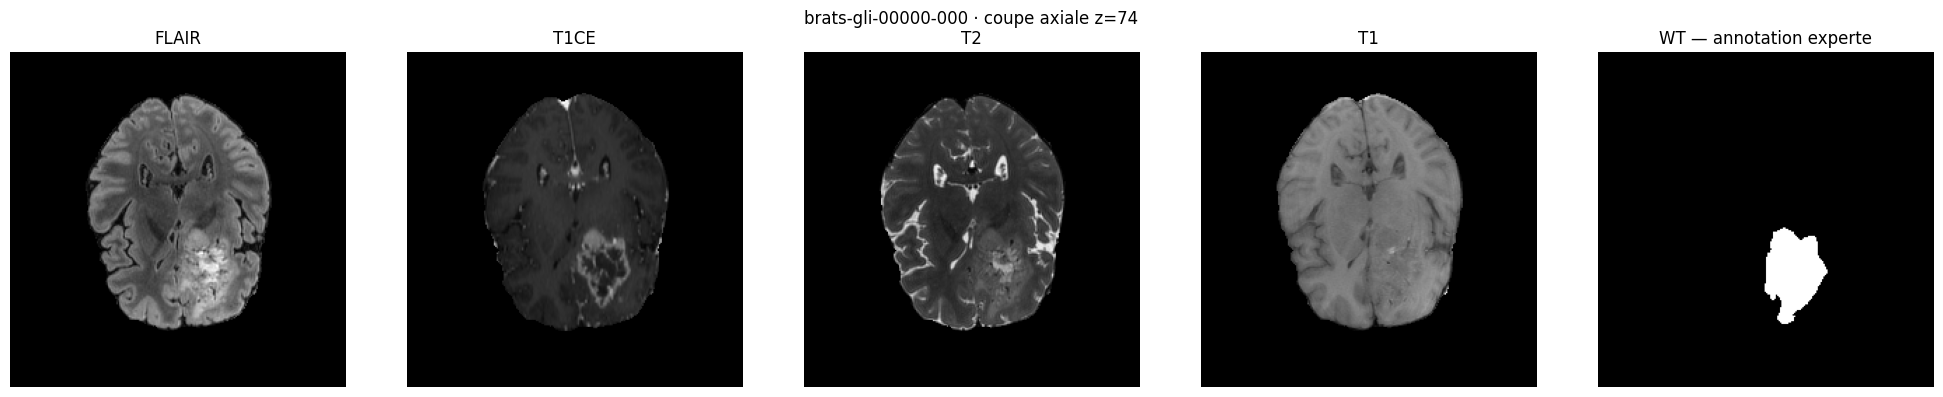

In [ ]:
def brats_regions(seg):
    labels = set(np.unique(seg).astype(int).tolist())
    if labels.issubset({0, 1, 2, 3}):
        label_et = 3
    elif labels.issubset({0, 1, 2, 4}):
        label_et = 4
    else:
        raise ValueError(f"Labels BraTS inattendus : {labels}")
    return {
        "WT": np.isin(seg, [1, 2, label_et]),
        "TC": np.isin(seg, [1, label_et]),
        "ET": np.isin(seg, [label_et])
    }

expert_regions = brats_regions(loaded["seg"][1])
# Coupe avec la plus grande aire WT pour visualiser la zone annotée
z = int(np.argmax(expert_regions["WT"].sum(axis=(0, 1))))
modalities = [m for m in ["flair", "t1ce", "t2", "t1"] if m in loaded]

fig, axes = plt.subplots(1, len(modalities) + 1, figsize=(4*(len(modalities)+1), 4))
for ax, modality in zip(axes, modalities):
    ax.imshow(np.rot90(loaded[modality][1][:, :, z]), cmap="gray")
    ax.set_title(modality.upper())
    ax.axis("off")
axes[-1].imshow(np.rot90(expert_regions["WT"][:, :, z]), cmap="gray")
axes[-1].set_title("WT — annotation experte")
axes[-1].axis("off")
plt.suptitle(f"{CASE_ID} · coupe axiale z={z}")
plt.tight_layout()
plt.show()

## 7. Définir la normalisation et l'élément structurant physique

La normalisation robuste utilise les percentiles 1 et 99 des voxels positifs : elle limite l'influence des valeurs extrêmes sans transformer les zéros du fond en tissu cérébral.

**Choix morphologique important :** l'élément structurant est défini en millimètres, puis converti en empreinte voxel ellipsoïdale selon le spacing NIfTI. Ainsi, un rayon de 1 mm représente approximativement la même distance physique dans les trois directions, même si les voxels ne sont pas isotropes.

In [ ]:
def robust_normalize(volume):
    x = np.asarray(volume, dtype=np.float32)
    valid = np.isfinite(x) & (x > 0)
    if not valid.any():
        raise ValueError("Aucun voxel positif et fini.")
    lo, hi = np.percentile(x[valid], [1, 99])
    if hi <= lo:
        raise ValueError("Contraste insuffisant pour normaliser.")
    out = np.zeros_like(x, dtype=np.float32)
    out[valid] = np.clip((x[valid] - lo) / (hi - lo), 0, 1)
    return out, valid

def physical_ball(radius_mm, spacing_mm):
    spacing = np.asarray(spacing_mm, dtype=float)
    if radius_mm <= 0 or np.any(spacing <= 0):
        raise ValueError("Rayon et spacing doivent être strictement positifs.")
    radii = np.maximum(1, np.ceil(radius_mm / spacing).astype(int))
    grids = np.ogrid[tuple(slice(-r, r+1) for r in radii)]
    distance2 = sum((g * sp) ** 2 for g, sp in zip(grids, spacing))
    return distance2 <= radius_mm**2

flair_raw = loaded["flair"][1]
flair_norm, flair_valid = robust_normalize(flair_raw)
spacing = loaded["flair"][2]

RADIUS_MM = 1.0
SE = physical_ball(RADIUS_MM, spacing)

print("Spacing (mm) :", spacing)
print("Rayon structurant (mm) :", RADIUS_MM)
print("Taille de l'empreinte 3D :", SE.shape)
print("Nombre de voxels dans B :", int(SE.sum()))

Spacing (mm) : (1.0, 1.0, 1.0)
Rayon structurant (mm) : 1.0
Taille de l'empreinte 3D : (3, 3, 3)
Nombre de voxels dans B : 7


## 8. Construire le masque candidat par seuillage multimodal

Le seuillage produit d'abord deux ensembles candidats :
- FLAIR : voxels de forte intensité, susceptibles de couvrir une partie de l'hyperintensité/œdème ;
- T1ce : voxels de forte intensité, pouvant inclure des régions rehaussées.

Le masque combiné est l'union des deux candidats. C'est une **règle de départ interprétable**, pas une vérité biologique : les seuils sont affichés et seront soumis à une analyse de sensibilité. Le masque expert n'intervient pas dans la construction.

Seuil FLAIR (q=0.90) : 0.7814
Seuil T1ce  (q=0.95) : 0.5213
Voxels FLAIR : 148444
Voxels T1ce  : 74044
Union initiale : 204043


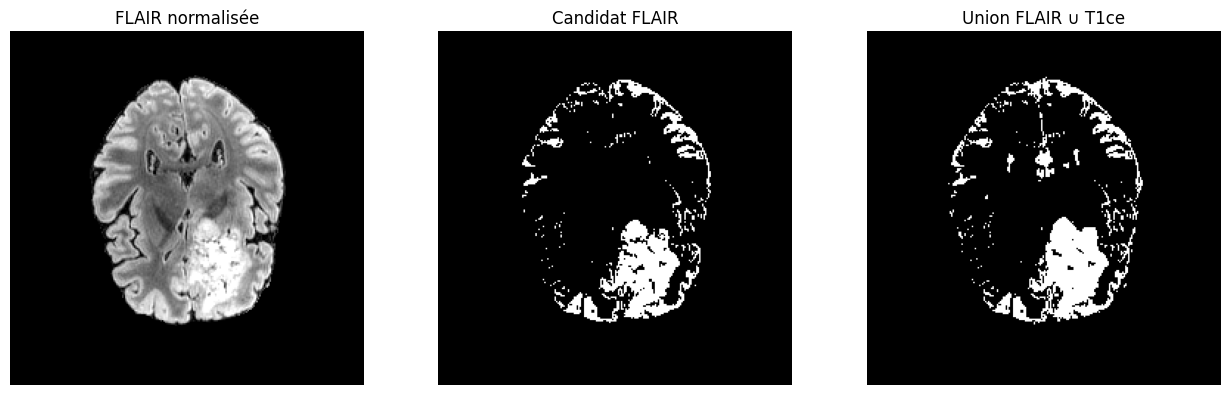

In [ ]:
FLAIR_QUANTILE = 0.90
T1CE_QUANTILE = 0.95

def threshold_candidate(volume, quantile):
    norm, valid = robust_normalize(volume)
    threshold = float(np.quantile(norm[valid], quantile))
    return (valid & (norm >= threshold)), norm, threshold

flair_candidate, flair_norm, flair_threshold = threshold_candidate(
    loaded["flair"][1], FLAIR_QUANTILE
)

if "t1ce" in loaded:
    t1ce_candidate, t1ce_norm, t1ce_threshold = threshold_candidate(
        loaded["t1ce"][1], T1CE_QUANTILE
    )
else:
    t1ce_candidate = np.zeros_like(flair_candidate, dtype=bool)
    t1ce_norm = None
    t1ce_threshold = np.nan

initial_candidate = flair_candidate | t1ce_candidate

print(f"Seuil FLAIR (q={FLAIR_QUANTILE:.2f}) : {flair_threshold:.4f}")
print(f"Seuil T1ce  (q={T1CE_QUANTILE:.2f}) : {t1ce_threshold:.4f}")
print("Voxels FLAIR :", int(flair_candidate.sum()))
print("Voxels T1ce  :", int(t1ce_candidate.sum()))
print("Union initiale :", int(initial_candidate.sum()))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(np.rot90(flair_norm[:, :, z]), cmap="gray"); ax[0].set_title("FLAIR normalisée")
ax[1].imshow(np.rot90(flair_candidate[:, :, z]), cmap="gray"); ax[1].set_title("Candidat FLAIR")
ax[2].imshow(np.rot90(initial_candidate[:, :, z]), cmap="gray"); ax[2].set_title("Union FLAIR ∪ T1ce")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Cellule  — Préparation de l'étude morphologique
Objectif : sélectionner un cas BraTS contenant les quatre modalités et son masque de segmentation. Nous utiliserons le même patient et la même coupe IRM pour les quatre modalités afin que la comparaison soit cohérente.

In [ ]:

# Redécouvrir les cas dans le dossier BraTS extrait
cases = discover_cases(PETITZIPBRATS_DIR)

# Sélectionner un cas complet : T1, T1ce, T2, FLAIR et segmentation
complete_cases = [
    case_id for case_id, files in cases.items()
    if all(k in files for k in ["t1", "t1ce", "t2", "flair", "seg"])
]

assert len(complete_cases) > 0, (
    "Aucun cas complet détecté. Vérifie les noms des fichiers et la cellule discover_cases."
)

case_id = complete_cases[0]
case_files = cases[case_id]

print("Patient sélectionné :", case_id)
print("Modalités disponibles :", list(case_files.keys()))


Patient sélectionné : brats-gli-00000-000
Modalités disponibles : ['seg', 't1ce', 't1', 'flair', 't2']


Cellule — Fonction d'affichage des opérations morphologiques
Objectif : appliquer séparément les opérations morphologiques à une coupe IRM en niveaux de gris. Nous utilisons un élément structurant circulaire (disk). Son rayon contrôle la taille des structures prises en compte.
- Érosion : réduit les régions claires.
- Dilatation : étend les régions claires.
- Ouverture : érosion suivie d'une dilatation, utile pour atténuer les petites structures claires.
- Fermeture : dilatation suivie d'une érosion, utile pour combler de petites zones sombres.
- Gradient morphologique : différence entre dilatation et érosion, mettant en évidence les transitions et les contours.

In [ ]:

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

from skimage import morphology
from skimage.morphology import disk

# Rayon de l'élément structurant
RADIUS = 3
footprint = disk(RADIUS)

def normalize_mri(image):
    """Normalisation robuste d'une coupe IRM entre 0 et 1."""
    image = np.asarray(image, dtype=np.float32)

    p1, p99 = np.percentile(image, [1, 99])

    if p99 <= p1:
        return np.zeros_like(image)

    image = np.clip(image, p1, p99)
    return (image - p1) / (p99 - p1)


def get_morphological_results(image, radius=3):
    """Calcule les cinq opérations morphologiques sur une image en niveaux de gris."""

    image = normalize_mri(image)
    element = disk(radius)

    eroded = morphology.erosion(image, footprint=element)
    dilated = morphology.dilation(image, footprint=element)
    opened = morphology.opening(image, footprint=element)
    closed = morphology.closing(image, footprint=element)

    gradient = dilated - eroded

    return {
        "Originale": image,
        "Érosion": eroded,
        "Dilatation": dilated,
        "Ouverture": opened,
        "Fermeture": closed,
        "Gradient": gradient
    }


def load_mri_slice(case_files, modality, slice_index):
    """Charge une modalité IRM et extrait une coupe axiale."""
    volume = nib.load(str(case_files[modality])).get_fdata()
    return volume[:, :, slice_index]


# Déterminer une coupe intéressante à partir du masque tumoral
seg_volume = nib.load(str(case_files["seg"])).get_fdata()

tumor_area_per_slice = np.sum(seg_volume > 0, axis=(0, 1))
slice_index = int(np.argmax(tumor_area_per_slice))

print("Coupe sélectionnée :", slice_index)
print("Surface tumorale sur cette coupe :", tumor_area_per_slice[slice_index])


Coupe sélectionnée : 74
Surface tumorale sur cette coupe : 1978


Cellule  — Étude morphologique de T1
Objectif : visualiser comment les opérations morphologiques modifient les intensités de la séquence T1. Cette comparaison permet notamment d'observer les petites structures claires atténuées par l'ouverture et les régions sombres réduites par la fermeture.

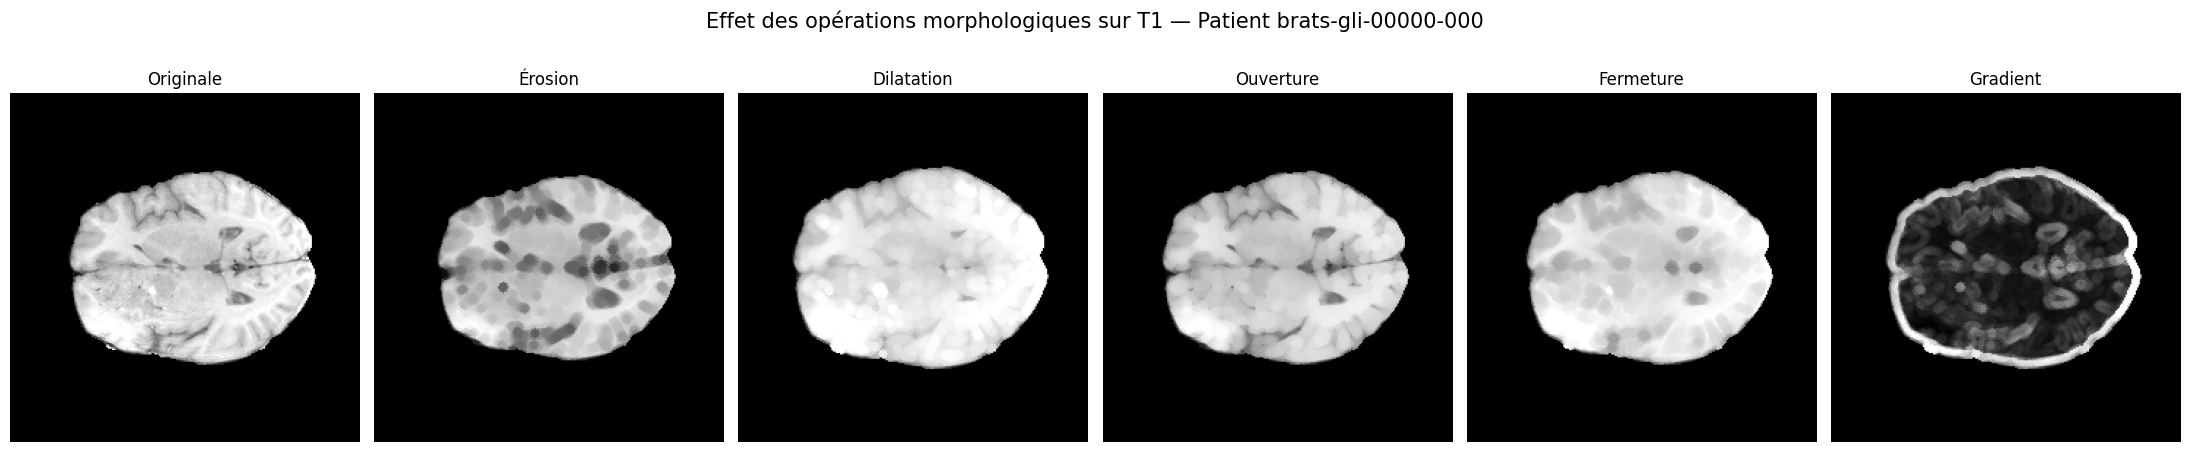

In [ ]:

t1_image = load_mri_slice(case_files, "t1", slice_index)
t1_results = get_morphological_results(t1_image, RADIUS)

fig, axes = plt.subplots(1, 6, figsize=(22, 5))

for ax, (name, image) in zip(axes, t1_results.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

fig.suptitle(
    f"Effet des opérations morphologiques sur T1 — Patient {case_id}",
    fontsize=15
)
plt.tight_layout()
plt.show()


Cellule  — Étude morphologique de T1ce
Objectif : analyser l'effet des mêmes opérations sur T1ce, séquence particulièrement intéressante pour observer les régions qui présentent une prise de contraste. Nous conservons le même rayon et la même coupe que pour T1 afin de rendre la comparaison reproductible.

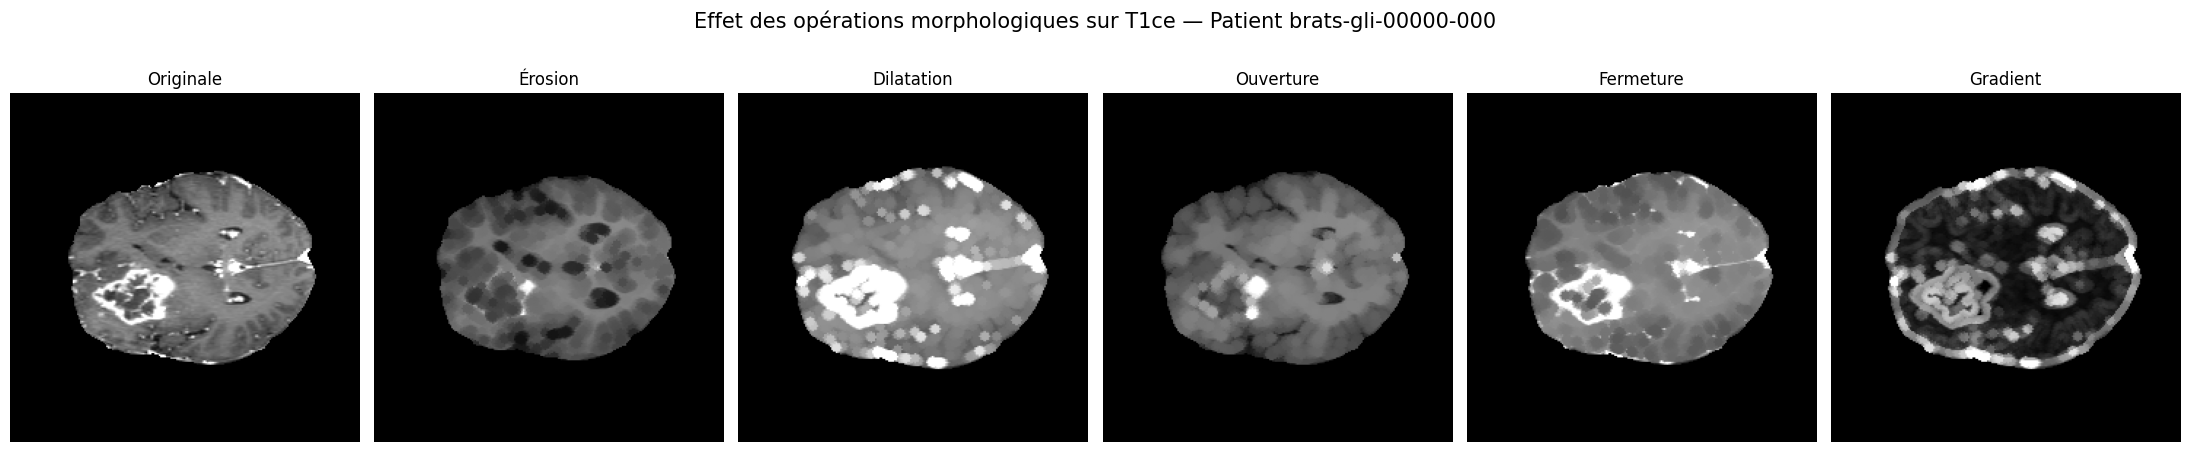

In [ ]:

t1ce_image = load_mri_slice(case_files, "t1ce", slice_index)
t1ce_results = get_morphological_results(t1ce_image, RADIUS)

fig, axes = plt.subplots(1, 6, figsize=(22, 5))

for ax, (name, image) in zip(axes, t1ce_results.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

fig.suptitle(
    f"Effet des opérations morphologiques sur T1ce — Patient {case_id}",
    fontsize=15
)
plt.tight_layout()
plt.show()


Cellule  — Étude morphologique de T2
Objectif : étudier l'influence des opérations morphologiques sur la séquence T2. La comparaison permet de voir comment les transformations modifient les régions hyperintenses et les petites structures présentes dans cette modalité.

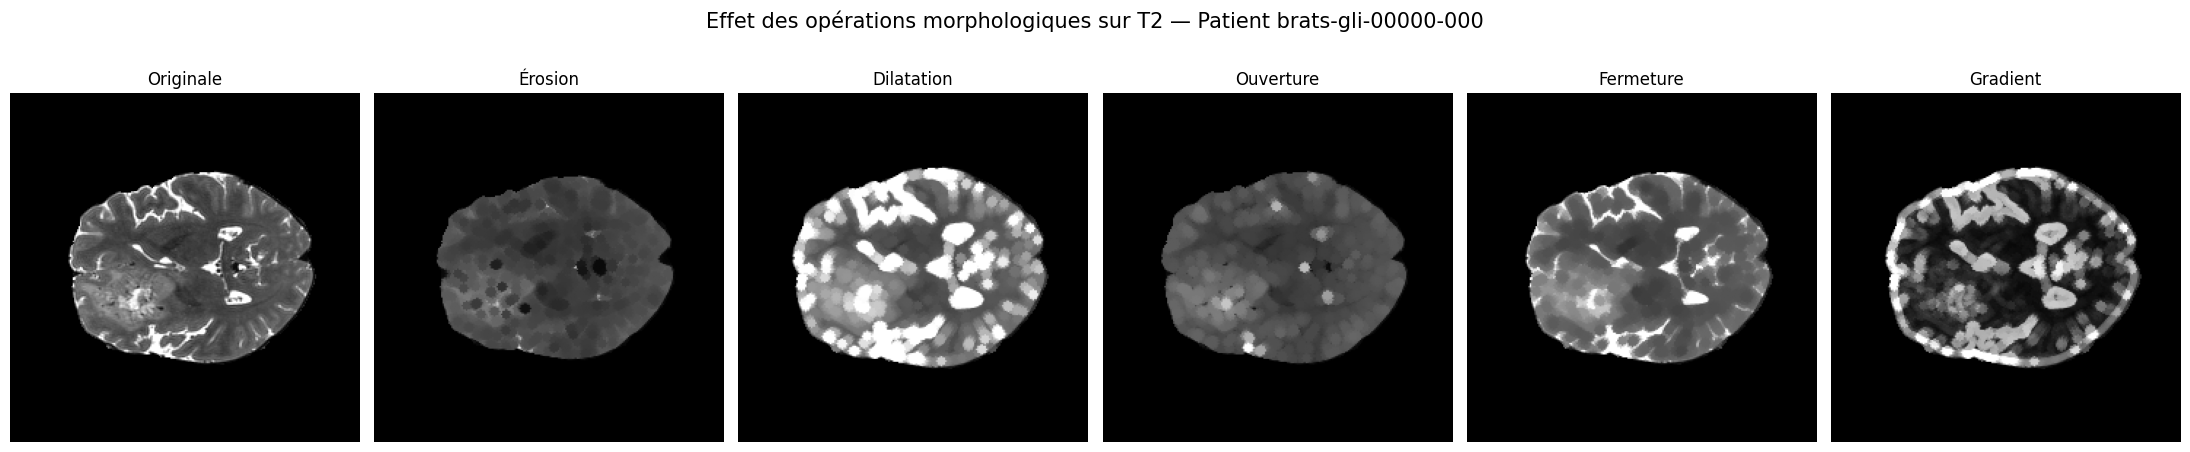

In [ ]:

t2_image = load_mri_slice(case_files, "t2", slice_index)
t2_results = get_morphological_results(t2_image, RADIUS)

fig, axes = plt.subplots(1, 6, figsize=(22, 5))

for ax, (name, image) in zip(axes, t2_results.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

fig.suptitle(
    f"Effet des opérations morphologiques sur T2 — Patient {case_id}",
    fontsize=15
)
plt.tight_layout()
plt.show()


Étude morphologique de T2-FLAIR
Objectif : étudier les mêmes transformations sur FLAIR. Cette séquence est particulièrement importante dans notre projet pour l'analyse des anomalies tumorales et de leur environnement.

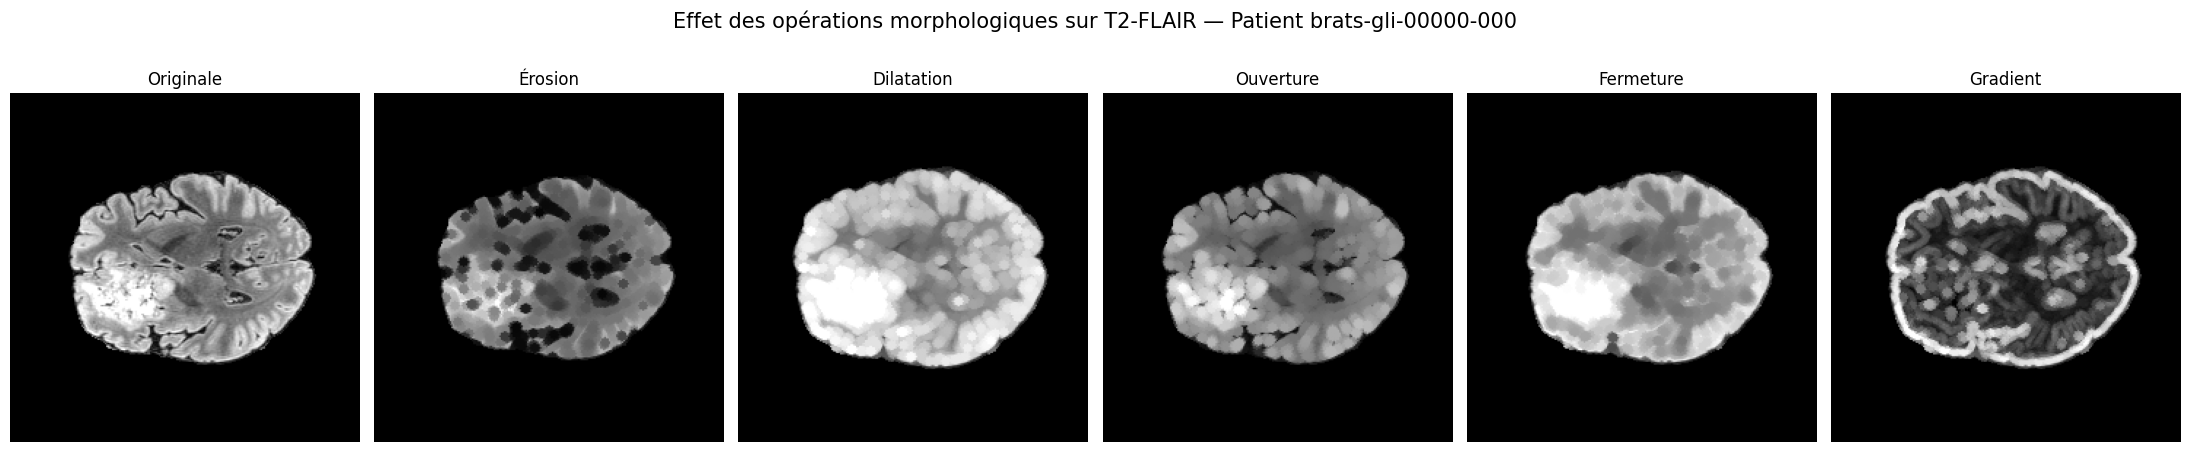

In [ ]:

flair_image = load_mri_slice(case_files, "flair", slice_index)
flair_results = get_morphological_results(flair_image, RADIUS)

fig, axes = plt.subplots(1, 6, figsize=(22, 5))

for ax, (name, image) in zip(axes, flair_results.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

fig.suptitle(
    f"Effet des opérations morphologiques sur T2-FLAIR — Patient {case_id}",
    fontsize=15
)
plt.tight_layout()
plt.show()


Comparaison des quatre modalités originales
Objectif : présenter les quatre modalités côte à côte, avec le contour du masque tumoral. Cela permet  de comprendre les différences entre les séquences avant d'interpréter les résultats des opérations morphologiques.

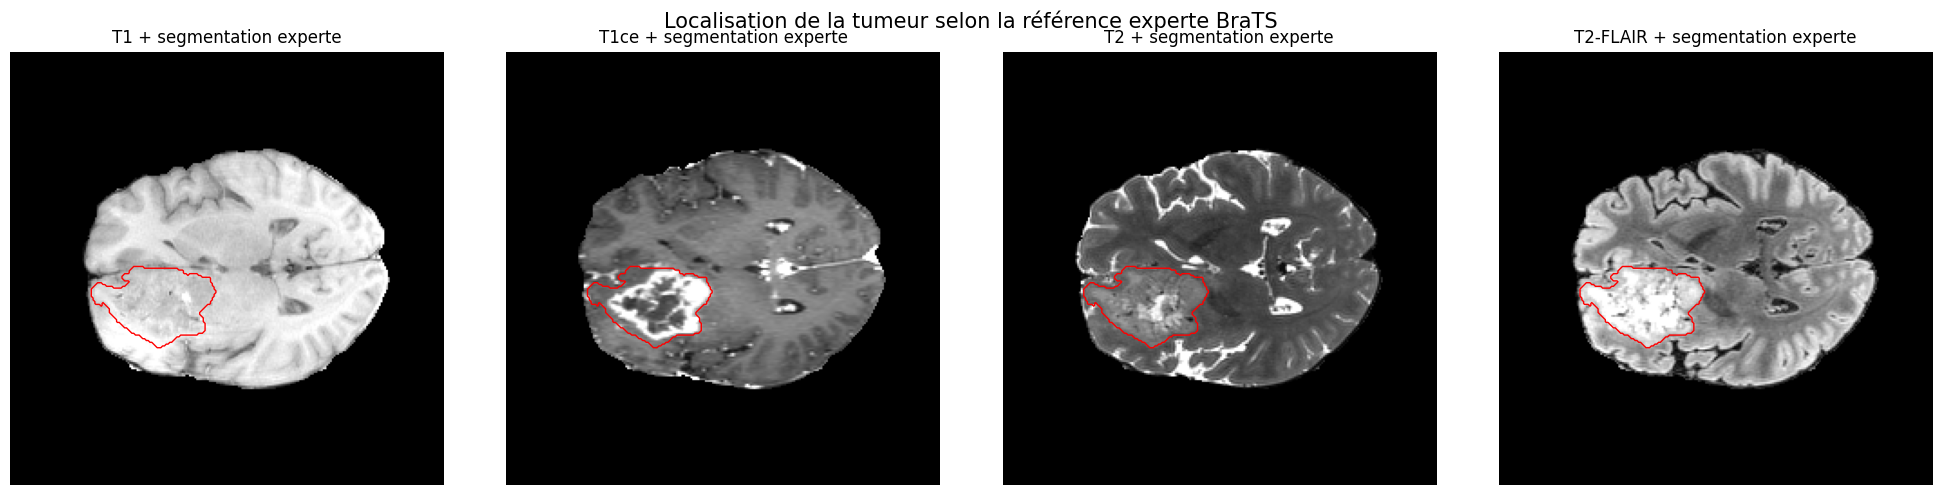

In [ ]:

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, (name, image) in zip(axes, modalities.items()):
    ax.imshow(normalize_mri(image), cmap="gray", vmin=0, vmax=1)

    ax.contour(
        seg_slice > 0,
        levels=[0.5],
        colors="red",
        linewidths=1
    )

    ax.set_title(f"{name} + segmentation experte")
    ax.axis("off")

fig.suptitle(
    "Localisation de la tumeur selon la référence experte BraTS",
    fontsize=15
)
plt.tight_layout()
plt.show()


## 9. Montrer l'effet individuel des opérations morphologiques sur l'IRM

Cette cellule est centrale pour la soutenance. Toutes les opérations sont calculées en 3D sur le même masque initial, avec le même élément structurant physique `B` :

- **Érosion** : \(A \ominus B\), retire les voxels de bord et rétrécit les régions.
- **Dilatation** : \(A \oplus B\), ajoute des voxels autour des régions.
- **Ouverture** : érosion puis dilatation, élimine des petites structures et des étranglements.
- **Fermeture** : dilatation puis érosion, comble de petites discontinuités.
- **Gradient morphologique** : dilatation moins érosion, met en évidence le contour.
- **Remplissage** : comble les trous entièrement entourés dans chaque coupe 2D.

Les panneaux montrent les masques seuls et leur superposition sur la FLAIR. Les différences de volume quantifient l'effet de chaque opération.

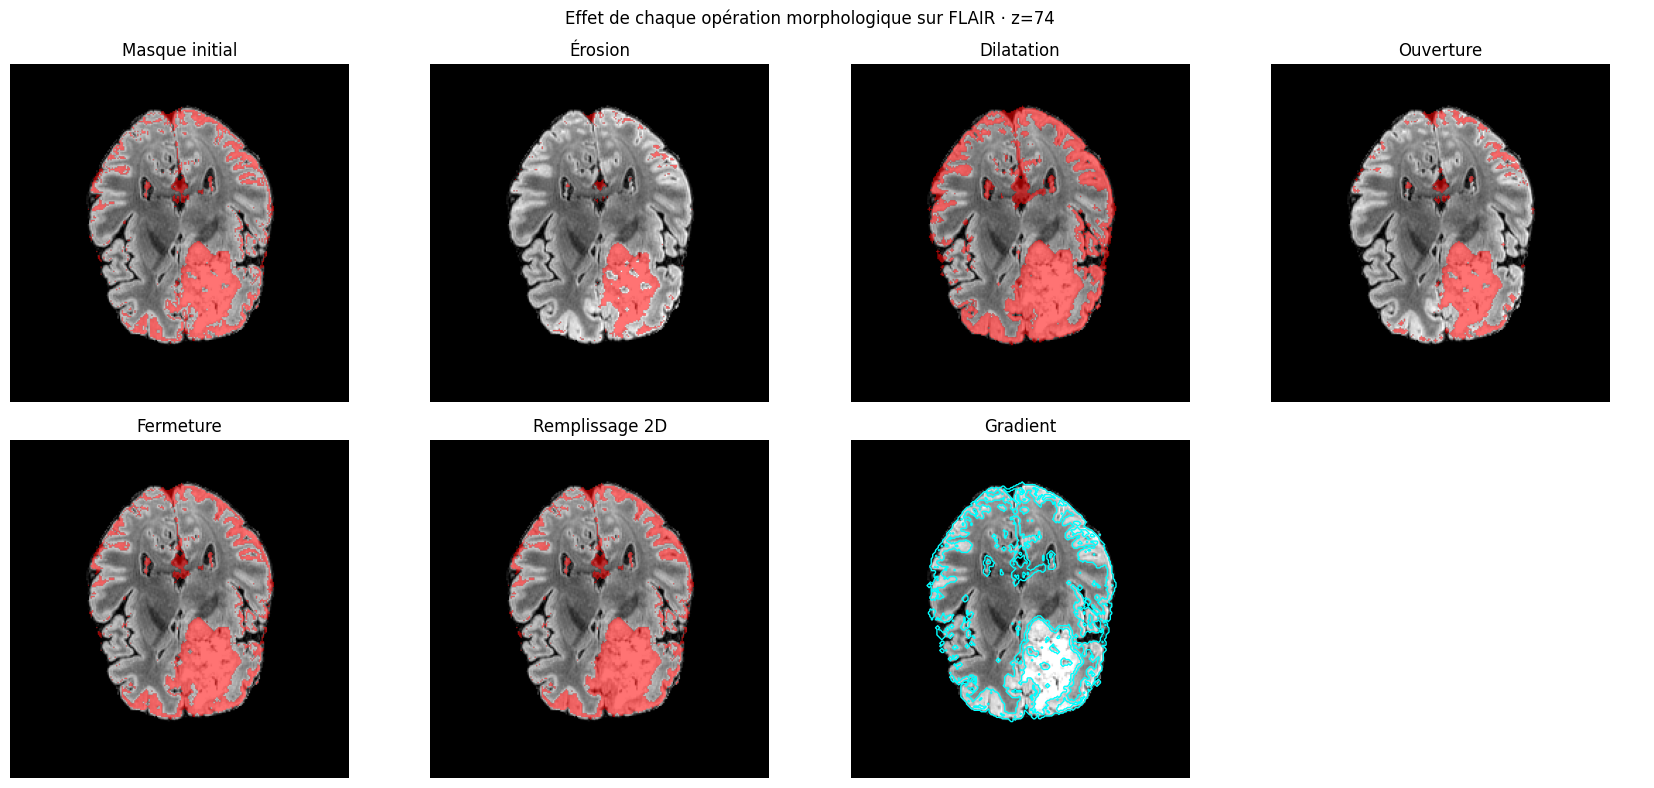

,operation,voxels_3D,volume_mm3,variation_vs_initial_%
0,Masque initial,204043,204043.0,0.000000
1,Érosion,57818,57818.0,-71.663816
2,Dilatation,431241,431241.0,111.348098
3,Ouverture,108860,108860.0,-46.648501
4,Fermeture,240379,240379.0,17.808011
5,Remplissage 2D,247900,247900.0,21.493999
6,Gradient,373423,373423.0,83.011914


In [ ]:
erosion = morphology.binary_erosion(initial_candidate, footprint=SE)
dilation = morphology.binary_dilation(initial_candidate, footprint=SE)
opening = morphology.binary_opening(initial_candidate, footprint=SE)
closing = morphology.binary_closing(initial_candidate, footprint=SE)
gradient = dilation & ~erosion
# Remplissage 2D coupe par coupe pour visualiser explicitement les cavités axiales
filled_2d = np.stack([
    ndimage.binary_fill_holes(closing[:, :, k]) for k in range(closing.shape[2])
], axis=2)

morph_stages = {
    "Masque initial": initial_candidate,
    "Érosion": erosion,
    "Dilatation": dilation,
    "Ouverture": opening,
    "Fermeture": closing,
    "Remplissage 2D": filled_2d,
    "Gradient": gradient
}

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, (name, mask) in zip(axes.ravel(), morph_stages.items()):
    ax.imshow(np.rot90(flair_norm[:, :, z]), cmap="gray")
    if name == "Gradient":
        ax.contour(np.rot90(mask[:, :, z]), levels=[0.5], colors="cyan", linewidths=1)
    else:
        ax.imshow(np.ma.masked_where(~np.rot90(mask[:, :, z]), np.rot90(mask[:, :, z])),
                  cmap="autumn", alpha=0.55)
    ax.set_title(name)
    ax.axis("off")
axes.ravel()[-1].axis("off")
plt.suptitle(f"Effet de chaque opération morphologique sur FLAIR · z={z}")
plt.tight_layout()
plt.show()

stage_table = pd.DataFrame([
    {"operation": name, "voxels_3D": int(mask.sum()),
     "volume_mm3": float(mask.sum() * np.prod(spacing)),
     "variation_vs_initial_%": 100*(mask.sum()-initial_candidate.sum())/max(initial_candidate.sum(),1)}
    for name, mask in morph_stages.items()
])
display(stage_table)

## 10. Construire la chaîne morphologique finale et visualiser chaque étape

La chaîne retenue pour la baseline est : **masque initial → ouverture → fermeture → remplissage des trous → plus grande composante connexe**. La plus grande composante est une hypothèse de travail adaptée à une lésion dominante ; elle peut supprimer des foyers secondaires. Nous conservons donc aussi les résultats avant cette étape pour rendre ce choix vérifiable.

La carte de composantes indique combien de régions connexes existent avant sélection.

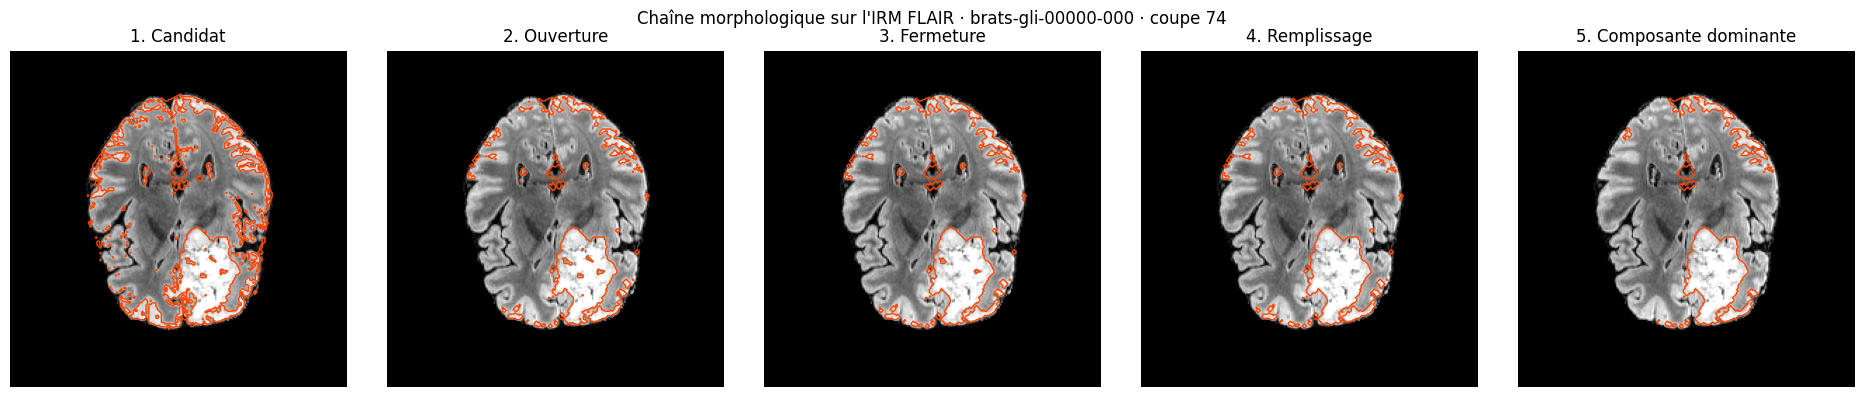

Composantes connexes avant sélection : 427
Voxels avant composante dominante : 115006
Voxels après composante dominante : 101742


In [ ]:
def largest_component(mask):
    labels, n = ndimage.label(mask)
    if n == 0:
        return np.zeros_like(mask, dtype=bool), labels, 0
    counts = np.bincount(labels.ravel())
    counts[0] = 0
    largest = labels == counts.argmax()
    return largest, labels, n

after_opening = morphology.binary_opening(initial_candidate, footprint=SE)
after_closing = morphology.binary_closing(after_opening, footprint=SE)
after_filling = np.stack([
    ndimage.binary_fill_holes(after_closing[:, :, k])
    for k in range(after_closing.shape[2])
], axis=2)
final_mask, component_labels, n_components = largest_component(after_filling)

pipeline_stages = {
    "1. Candidat": initial_candidate,
    "2. Ouverture": after_opening,
    "3. Fermeture": after_closing,
    "4. Remplissage": after_filling,
    "5. Composante dominante": final_mask
}

fig, axes = plt.subplots(1, 5, figsize=(19, 4))
for ax, (name, mask) in zip(axes, pipeline_stages.items()):
    ax.imshow(np.rot90(flair_norm[:, :, z]), cmap="gray")
    ax.contour(np.rot90(mask[:, :, z]), levels=[0.5], colors="orangered", linewidths=1)
    ax.set_title(name); ax.axis("off")
plt.suptitle(f"Chaîne morphologique sur l'IRM FLAIR · {CASE_ID} · coupe {z}")
plt.tight_layout(); plt.show()

print("Composantes connexes avant sélection :", n_components)
print("Voxels avant composante dominante :", int(after_filling.sum()))
print("Voxels après composante dominante :", int(final_mask.sum()))

## 11. Visualiser les contours et comparer à l'annotation experte

Le contour rouge correspond au masque morphologique final ; les contours cyan correspondent à l'annotation WT experte. Cette superposition permet de repérer les faux positifs, les régions manquées et les différences de localisation.

La coupe choisie est celle où l'annotation WT possède sa plus grande aire, ce qui évite de présenter uniquement une coupe centrale potentiellement peu informative.

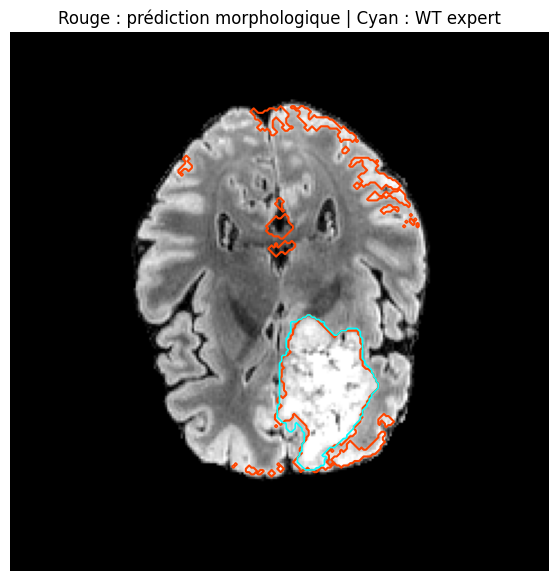

In [ ]:
expert_regions = brats_regions(loaded["seg"][1])
z_eval = int(np.argmax(expert_regions["WT"].sum(axis=(0, 1))))

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(np.rot90(flair_norm[:, :, z_eval]), cmap="gray")
ax.contour(np.rot90(final_mask[:, :, z_eval]), levels=[0.5],
           colors="orangered", linewidths=1.5)
ax.contour(np.rot90(expert_regions["WT"][:, :, z_eval]), levels=[0.5],
           colors="cyan", linewidths=1.2)
ax.set_title("Rouge : prédiction morphologique | Cyan : WT expert")
ax.axis("off")
plt.show()

## 12. Quantifier la validation : Dice, Jaccard et ablation morphologique

1.   Élément de liste
2.   Élément de liste



Le Dice et le Jaccard mesurent le recouvrement spatial avec une région de référence. Nous calculons les scores pour WT, TC et ET, mais il faut interpréter la comparaison selon la modalité : FLAIR est surtout informative pour l'hyperintensité/œdème et T1ce pour le rehaussement. Une union de candidats n'est pas une segmentation sémantique experte des trois sous-régions.

L'ablation compare les étapes successives au WT expert : elle permet de voir si l'ouverture, la fermeture, le remplissage et la composante dominante améliorent ou dégradent le recouvrement sur ce cas.

In [ ]:
def dice(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    den = a.sum() + b.sum()
    return np.nan if den == 0 else 2*np.logical_and(a, b).sum()/den

def jaccard(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    den = np.logical_or(a, b).sum()
    return np.nan if den == 0 else np.logical_and(a, b).sum()/den

rows = []
for name, pred in pipeline_stages.items():
    row = {"stage": name, "voxels": int(pred.sum()),
           "volume_mm3": float(pred.sum()*np.prod(spacing)),
           "Dice_WT": dice(pred, expert_regions["WT"]),
           "Jaccard_WT": jaccard(pred, expert_regions["WT"])}
    rows.append(row)
ablation_df = pd.DataFrame(rows)
display(ablation_df)

region_scores = pd.DataFrame([
    {"region": region, "Dice": dice(final_mask, ref),
     "Jaccard": jaccard(final_mask, ref),
     "expert_voxels": int(ref.sum())}
    for region, ref in expert_regions.items()
])
display(region_scores)

,stage,voxels,volume_mm3,Dice_WT,Jaccard_WT
0,1. Candidat,204043,204043.0,0.370257,0.227188
1,2. Ouverture,108860,108860.0,0.565919,0.394622
2,3. Fermeture,113328,113328.0,0.570757,0.399342
3,4. Remplissage,115006,115006.0,0.577119,0.405599
4,5. Composante dominante,101742,101742.0,0.625073,0.454623


,region,Dice,Jaccard,expert_voxels
0,WT,0.625073,0.454623,57305
1,TC,0.580052,0.408502,44469
2,ET,0.456434,0.295701,32731


In [ ]:

# Quantiles de seuillage par modalité
# FLAIR et T1ce reprennent les valeurs de la méthode initiale.
# T1 et T2 utilisent ici q=0.90 comme baselines expérimentales.
MODALITY_QUANTILES = {
    "t1": 0.90,
    "t1ce": 0.95,
    "t2": 0.90,
    "flair": 0.90
}

def build_morphological_stages(candidate, spacing_mm, radius_mm=RADIUS_MM):
    """Applique la même chaîne morphologique 3D à un masque candidat."""
    se = physical_ball(radius_mm, spacing_mm)

    opened = morphology.binary_opening(candidate, footprint=se)
    closed = morphology.binary_closing(opened, footprint=se)

    filled = np.stack([
        ndimage.binary_fill_holes(closed[:, :, k])
        for k in range(closed.shape[2])
    ], axis=2)

    final, labels, n_components = largest_component(filled)

    return {
        "Candidat initial": candidate,
        "Après ouverture": opened,
        "Après fermeture": closed,
        "Après remplissage": filled,
        "Après composante dominante": final
    }, n_components


# Construire une expérience indépendante pour chaque modalité
modality_experiments = {}

for modality, quantile in MODALITY_QUANTILES.items():
    raw_volume = loaded[modality][1]
    spacing_modality = loaded[modality][2]

    candidate, normalized, threshold = threshold_candidate(
        raw_volume, quantile
    )

    stages, n_components = build_morphological_stages(
        candidate, spacing_modality, RADIUS_MM
    )

    modality_experiments[modality] = {
        "normalized": normalized,
        "threshold": threshold,
        "quantile": quantile,
        "candidate": candidate,
        "stages": stages,
        "final": stages["Après composante dominante"],
        "components": n_components,
        "spacing": spacing_modality
    }

    print(
        f"{modality.upper():5s} | "
        f"quantile={quantile:.2f} | "
        f"seuil={threshold:.4f} | "
        f"composantes={n_components} | "
        f"voxels finaux={int(stages['Après composante dominante'].sum())}"
    )


T1    | quantile=0.90 | seuil=0.8350 | composantes=120 | voxels finaux=45602
T1CE  | quantile=0.95 | seuil=0.5213 | composantes=154 | voxels finaux=33975
T2    | quantile=0.90 | seuil=0.4506 | composantes=523 | voxels finaux=32506
FLAIR | quantile=0.90 | seuil=0.7814 | composantes=341 | voxels finaux=43073


In [ ]:

# Reproduire la méthode multimodale actuelle : FLAIR OR T1ce
flair_candidate, flair_norm, flair_threshold = threshold_candidate(
    loaded["flair"][1], FLAIR_QUANTILE
)

t1ce_candidate, t1ce_norm, t1ce_threshold = threshold_candidate(
    loaded["t1ce"][1], T1CE_QUANTILE
)

fusion_candidate = flair_candidate | t1ce_candidate

fusion_stages, fusion_components = build_morphological_stages(
    fusion_candidate,
    loaded["flair"][2],
    RADIUS_MM
)

fusion_final = fusion_stages["Après composante dominante"]

print("Fusion FLAIR + T1ce")
print("Seuil FLAIR :", flair_threshold)
print("Seuil T1ce :", t1ce_threshold)
print("Composantes avant sélection :", fusion_components)
print("Voxels finaux :", int(fusion_final.sum()))


Fusion FLAIR + T1ce
Seuil FLAIR : 0.781361997127533
Seuil T1ce : 0.5213221907615662
Composantes avant sélection : 427
Voxels finaux : 101742


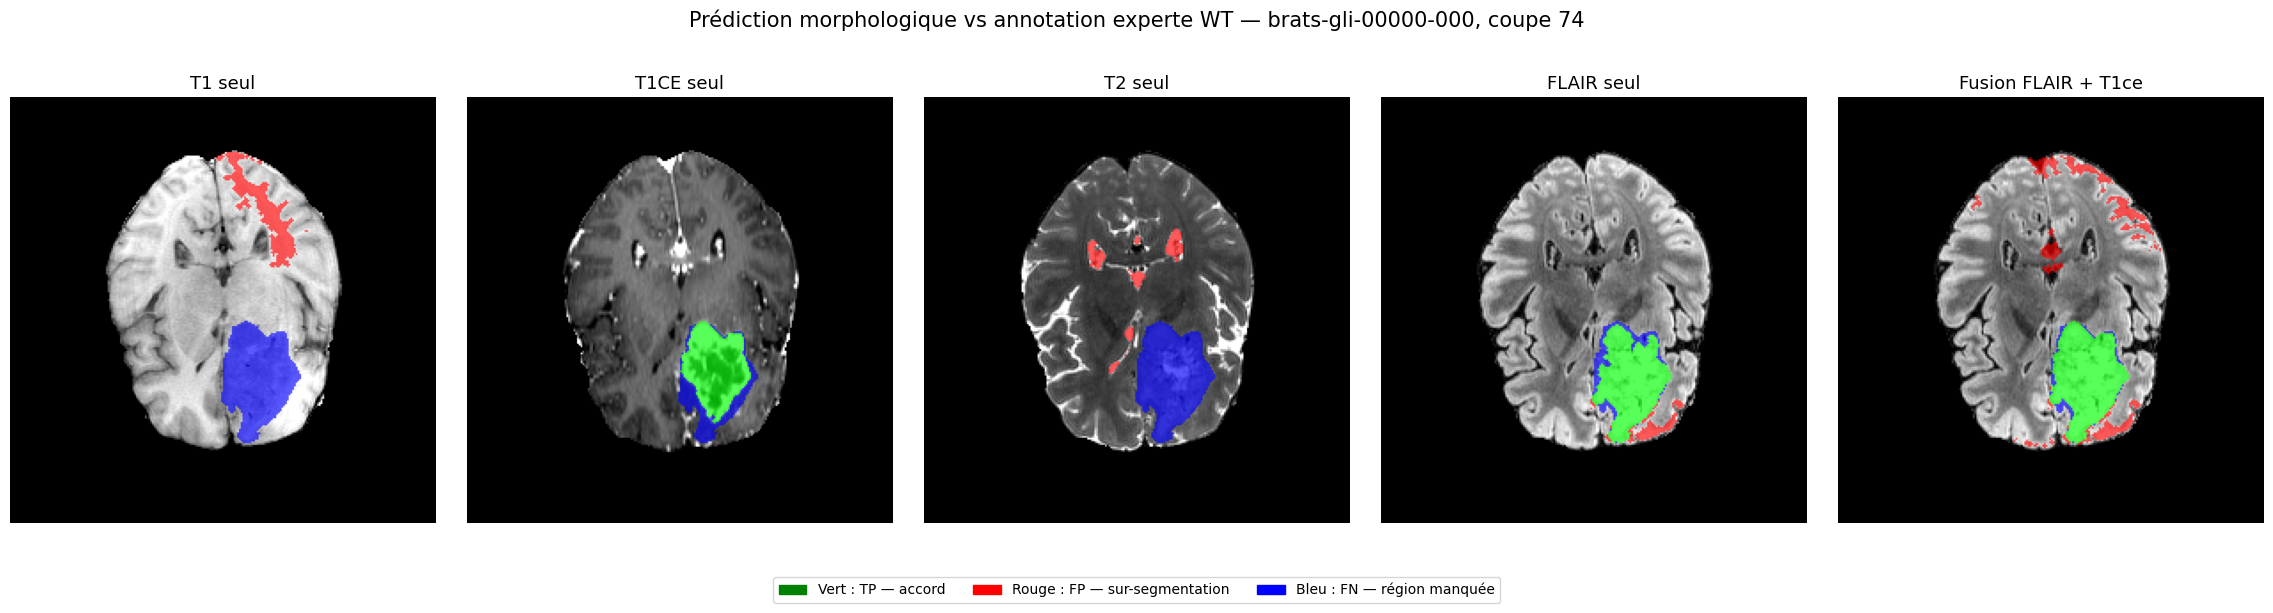

In [ ]:

import matplotlib.patches as mpatches

def make_comparison_overlay(mri_slice, predicted_slice, expert_slice, alpha=0.65):
    """Superposition RGB : TP vert, FP rouge, FN bleu."""
    base = normalize_mri(mri_slice)

    # Image IRM de fond en RGB
    rgb = np.stack([base, base, base], axis=-1)

    pred = np.asarray(predicted_slice, dtype=bool)
    expert = np.asarray(expert_slice, dtype=bool)

    tp = pred & expert
    fp = pred & ~expert
    fn = ~pred & expert

    # Mélange des couleurs avec l'image IRM
    rgb[tp] = (1-alpha) * rgb[tp] + alpha * np.array([0, 1, 0])
    rgb[fp] = (1-alpha) * rgb[fp] + alpha * np.array([1, 0, 0])
    rgb[fn] = (1-alpha) * rgb[fn] + alpha * np.array([0, 0, 1])

    return rgb


# Affichage des quatre modalités + la fusion actuelle
fig, axes = plt.subplots(1, 5, figsize=(23, 6))

for ax, modality in zip(axes[:4], ["t1", "t1ce", "t2", "flair"]):
    exp = modality_experiments[modality]

    mri_slice = exp["normalized"][:, :, z_eval]
    pred_slice = exp["final"][:, :, z_eval]
    expert_slice = expert_WT[:, :, z_eval]

    overlay = make_comparison_overlay(
        mri_slice, pred_slice, expert_slice
    )

    ax.imshow(np.rot90(overlay))
    ax.set_title(f"{modality.upper()} seul", fontsize=13)
    ax.axis("off")

# Cinquième panneau : segmentation multimodale actuelle
fusion_overlay = make_comparison_overlay(
    flair_norm[:, :, z_eval],
    fusion_final[:, :, z_eval],
    expert_WT[:, :, z_eval]
)

axes[4].imshow(np.rot90(fusion_overlay))
axes[4].set_title("Fusion FLAIR + T1ce", fontsize=13)
axes[4].axis("off")

legend_items = [
    mpatches.Patch(color="green", label="Vert : TP — accord"),
    mpatches.Patch(color="red", label="Rouge : FP — sur-segmentation"),
    mpatches.Patch(color="blue", label="Bleu : FN — région manquée")
]

fig.legend(handles=legend_items, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle(
    f"Prédiction morphologique vs annotation experte WT — {CASE_ID}, coupe {z_eval}",
    fontsize=15
)
plt.tight_layout(rect=[0, 0.10, 1, 0.92])
plt.show()


In [ ]:

def calculate_dice(pred, ref):
    pred = np.asarray(pred, dtype=bool)
    ref = np.asarray(ref, dtype=bool)

    denominator = pred.sum() + ref.sum()
    if denominator == 0:
        return np.nan

    return 2 * np.logical_and(pred, ref).sum() / denominator


def calculate_jaccard(pred, ref):
    pred = np.asarray(pred, dtype=bool)
    ref = np.asarray(ref, dtype=bool)

    union = np.logical_or(pred, ref).sum()
    if union == 0:
        return np.nan

    return np.logical_and(pred, ref).sum() / union


# Comparaison des prédictions finales
all_predictions = {
    "T1 seul": modality_experiments["t1"]["final"],
    "T1ce seul": modality_experiments["t1ce"]["final"],
    "T2 seul": modality_experiments["t2"]["final"],
    "FLAIR seul": modality_experiments["flair"]["final"],
    "Fusion FLAIR + T1ce": fusion_final
}

comparison_rows = []

for name, pred in all_predictions.items():
    comparison_rows.append({
        "Méthode": name,
        "Dice WT": calculate_dice(pred, expert_WT),
        "Jaccard WT": calculate_jaccard(pred, expert_WT),
        "Volume prédit (mm³)": float(
            pred.sum() * np.prod(loaded["flair"][2])
        ),
        "Volume expert (mm³)": float(
            expert_WT.sum() * np.prod(loaded["seg"][2])
        ),
        "Voxels prédits": int(pred.sum())
    })

modality_scores_df = pd.DataFrame(comparison_rows)

display(
    modality_scores_df.style.format({
        "Dice WT": "{:.4f}",
        "Jaccard WT": "{:.4f}",
        "Volume prédit (mm³)": "{:,.1f}",
        "Volume expert (mm³)": "{:,.1f}"
    })
)


,Méthode,Dice WT,Jaccard WT,Volume prédit (mm³),Volume expert (mm³),Voxels prédits
0,T1 seul,0.0000,0.0000,"45,602.0","57,305.0",45602
1,T1ce seul,0.7390,0.5861,"33,975.0","57,305.0",33975
2,T2 seul,0.0003,0.0001,"32,506.0","57,305.0",32506
3,FLAIR seul,0.7695,0.6253,"43,073.0","57,305.0",43073
4,Fusion FLAIR + T1ce,0.6251,0.4546,"101,742.0","57,305.0",101742


,Modalité,Étape morphologique,Dice WT,Jaccard WT,Volume prédit (mm³),Nombre de voxels
0,T1,Candidat initial,0.0427,0.0218,"148,970.0",148970
1,T1,Après ouverture,0.0372,0.0190,"116,238.0",116238
2,T1,Après fermeture,0.0375,0.0191,"119,309.0",119309
3,T1,Après remplissage,0.0375,0.0191,"120,248.0",120248
4,T1,Après composante dominante,0.0000,0.0000,"45,602.0",45602
5,T1ce,Candidat initial,0.4147,0.2616,"74,044.0",74044
6,T1ce,Après ouverture,0.4888,0.3235,"46,312.0",46312
7,T1ce,Après fermeture,0.5026,0.3356,"47,591.0",47591
8,T1ce,Après remplissage,0.6007,0.4293,"54,986.0",54986
9,T1ce,Après composante dominante,0.7390,0.5861,"33,975.0",33975


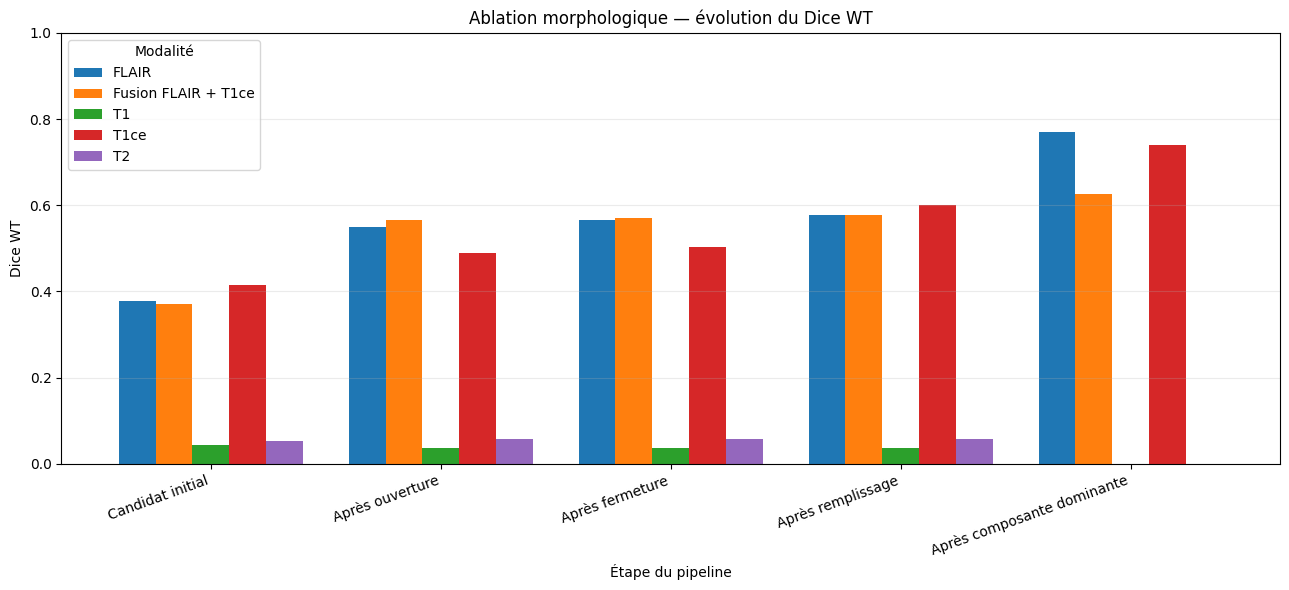

In [ ]:

# Regrouper toutes les étapes des quatre expériences individuelles
all_stage_sets = {
    "T1": modality_experiments["t1"]["stages"],
    "T1ce": modality_experiments["t1ce"]["stages"],
    "T2": modality_experiments["t2"]["stages"],
    "FLAIR": modality_experiments["flair"]["stages"],
    "Fusion FLAIR + T1ce": fusion_stages
}

ablation_rows = []

for modality_name, stages in all_stage_sets.items():
    for stage_name, pred in stages.items():
        ablation_rows.append({
            "Modalité": modality_name,
            "Étape morphologique": stage_name,
            "Dice WT": calculate_dice(pred, expert_WT),
            "Jaccard WT": calculate_jaccard(pred, expert_WT),
            "Volume prédit (mm³)": float(
                pred.sum() * np.prod(loaded["flair"][2])
            ),
            "Nombre de voxels": int(pred.sum())
        })

ablation_all_df = pd.DataFrame(ablation_rows)

display(
    ablation_all_df.style.format({
        "Dice WT": "{:.4f}",
        "Jaccard WT": "{:.4f}",
        "Volume prédit (mm³)": "{:,.1f}"
    })
)

# Visualiser l'évolution du Dice à chaque étape
dice_pivot = ablation_all_df.pivot(
    index="Étape morphologique",
    columns="Modalité",
    values="Dice WT"
)

order = [
    "Candidat initial",
    "Après ouverture",
    "Après fermeture",
    "Après remplissage",
    "Après composante dominante"
]

dice_pivot = dice_pivot.reindex(order)

ax = dice_pivot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Ablation morphologique — évolution du Dice WT")
ax.set_xlabel("Étape du pipeline")
ax.set_ylabel("Dice WT")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Modalité")
plt.tight_layout()
plt.show()


TP — True Positive (vrai positif)

Notre algorithme détecte une région tumorale et l'expert confirme qu'elle est tumorale. C'est un accord correct.



FP — False Positive (faux positif)

Notre algorithme détecte une région comme tumorale, mais l'expert ne l'a pas annotée. C'est une fausse détection.



FN — False Negative (faux négatif)

L'expert a annoté une région tumorale, mais notre algorithme ne l'a pas détectée. C'est une région tumorale manquée.



TN — True Negative (vrai négatif)

L'expert et notre algorithme considèrent tous les deux la région comme non tumorale. C'est un accord sur le fond.

Fusion FLAIR + T1ce

C’est combiner les deux masques (celui de FLAIR et celui de T1ce) en un seul, pour profiter de ce que chaque séquence voit de mieux.

FLAIR voit bien l’œdème (zone large).
T1ce voit bien la tumeur active (anneau brillant).

Aucune des deux ne voit toute la tumeur seule.

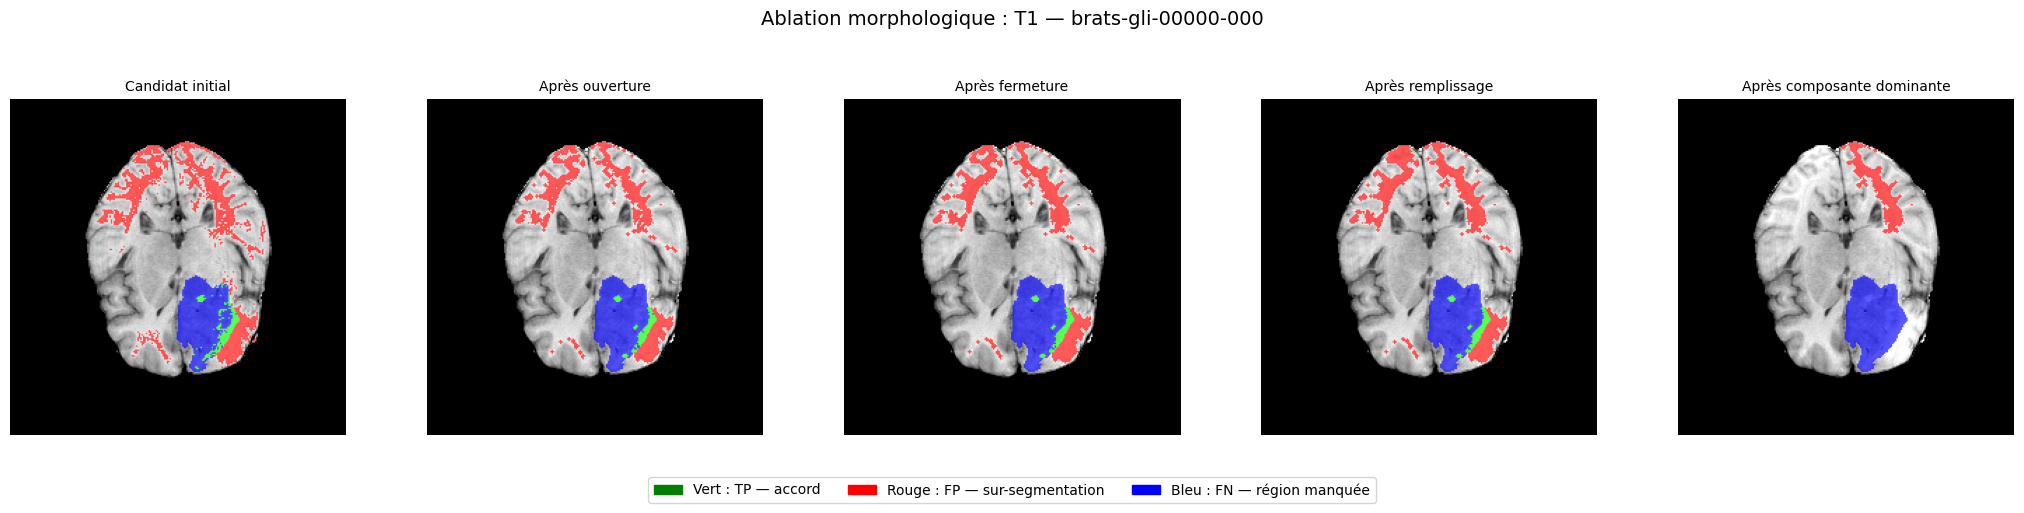

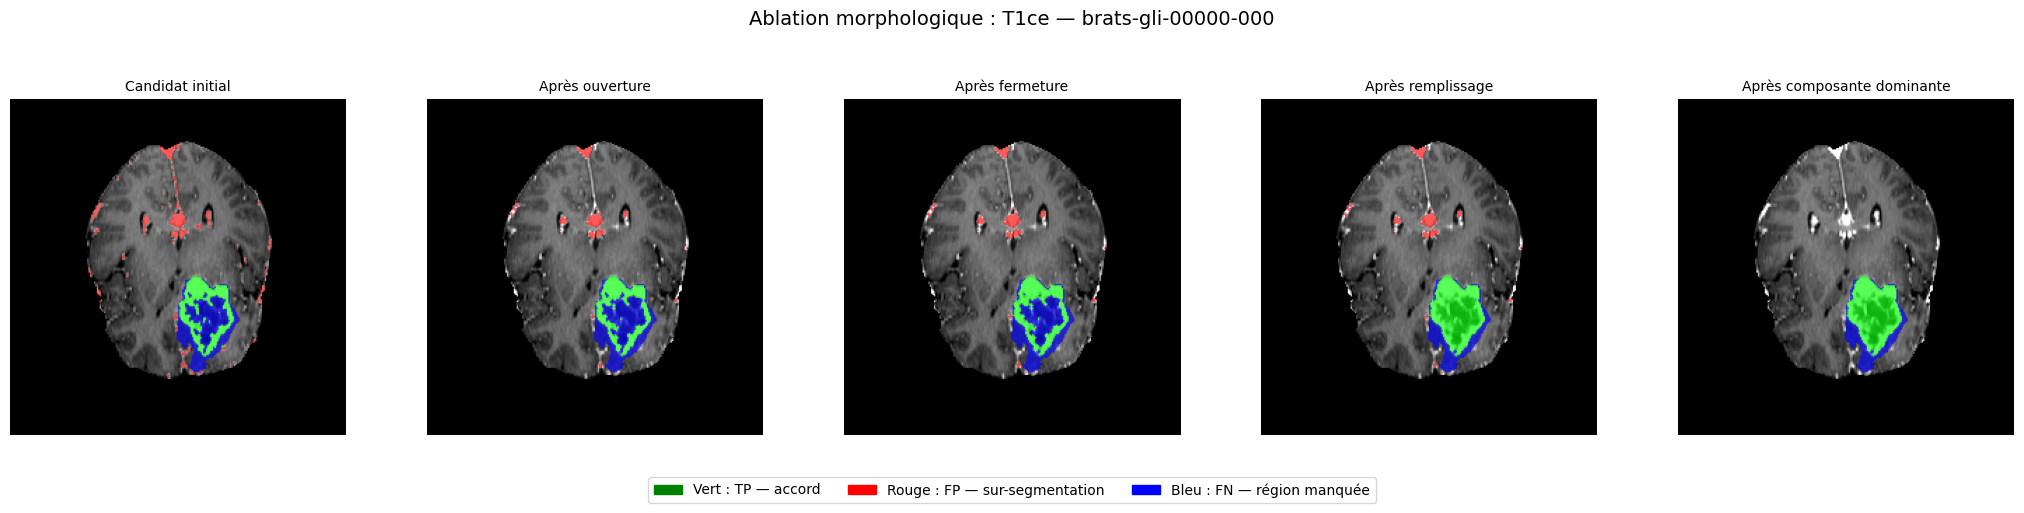

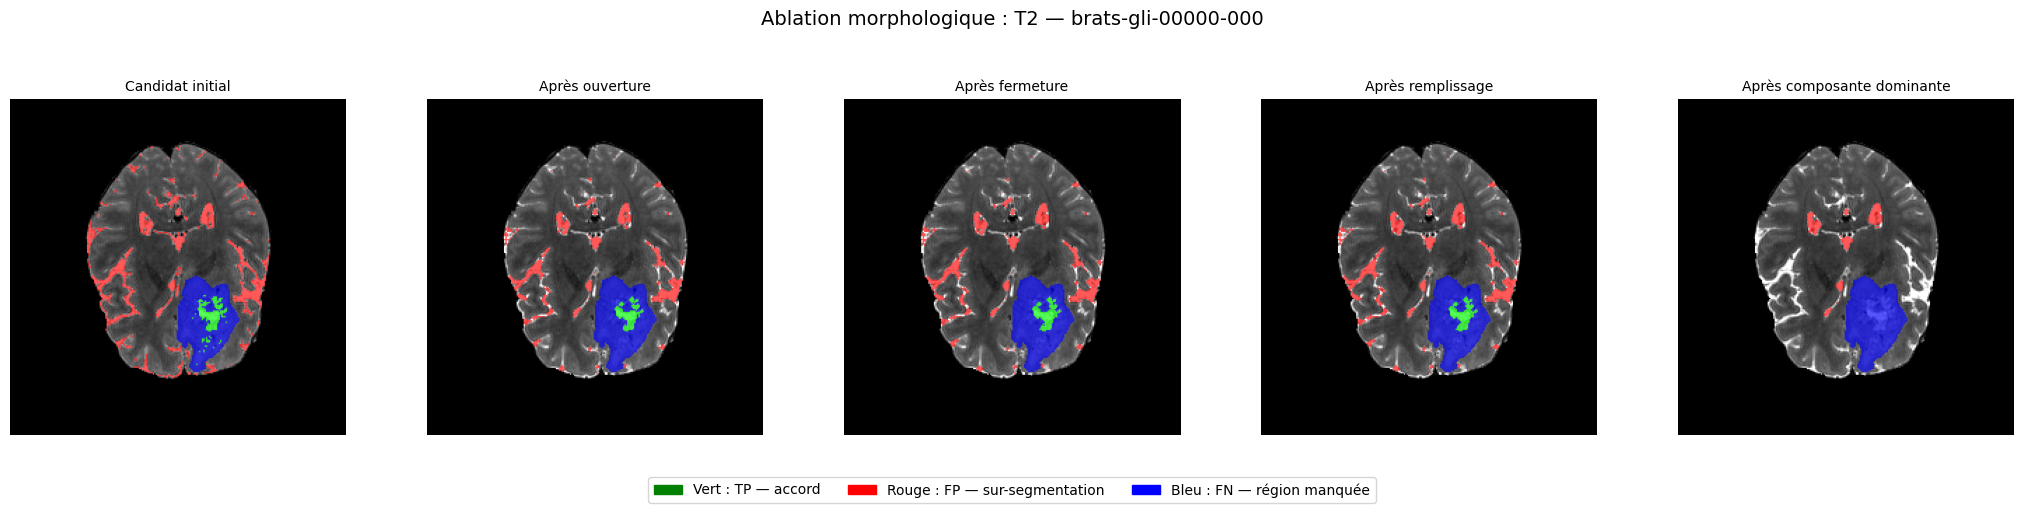

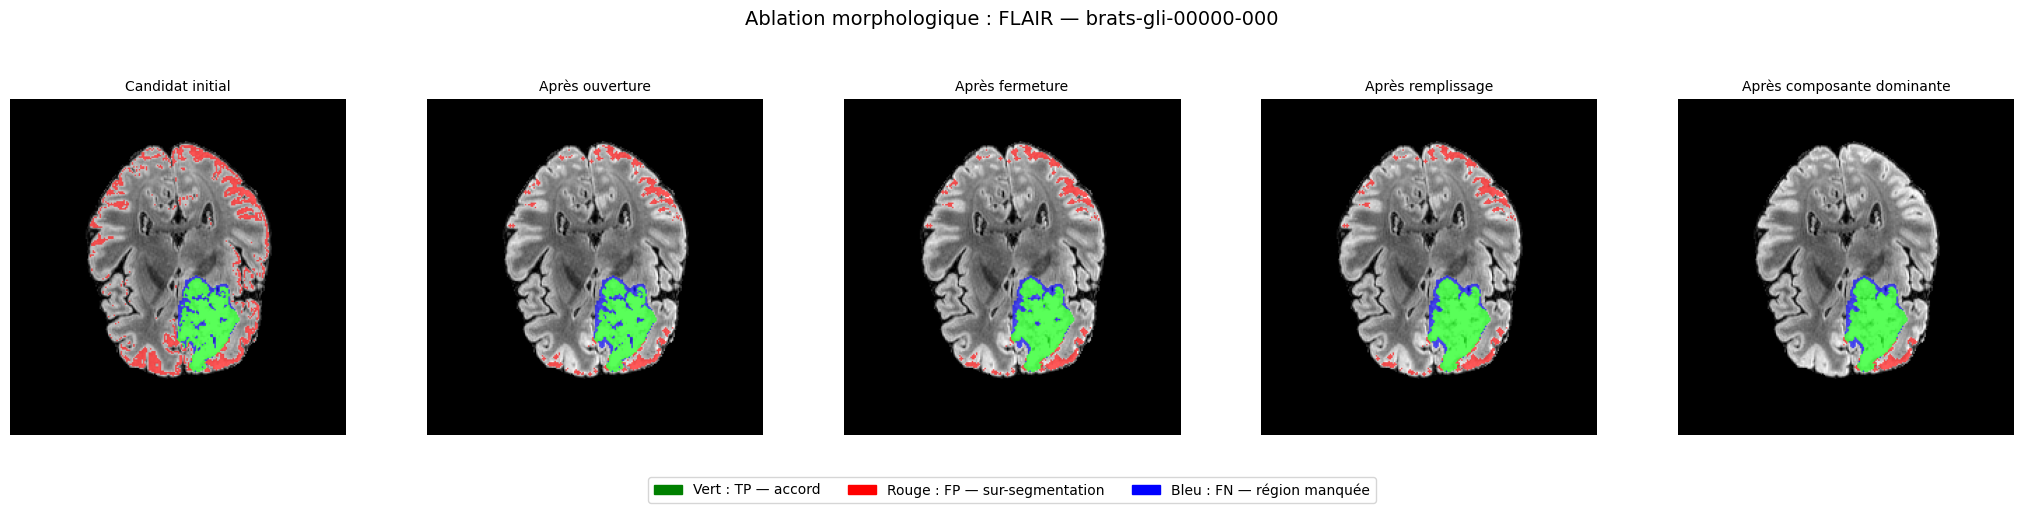

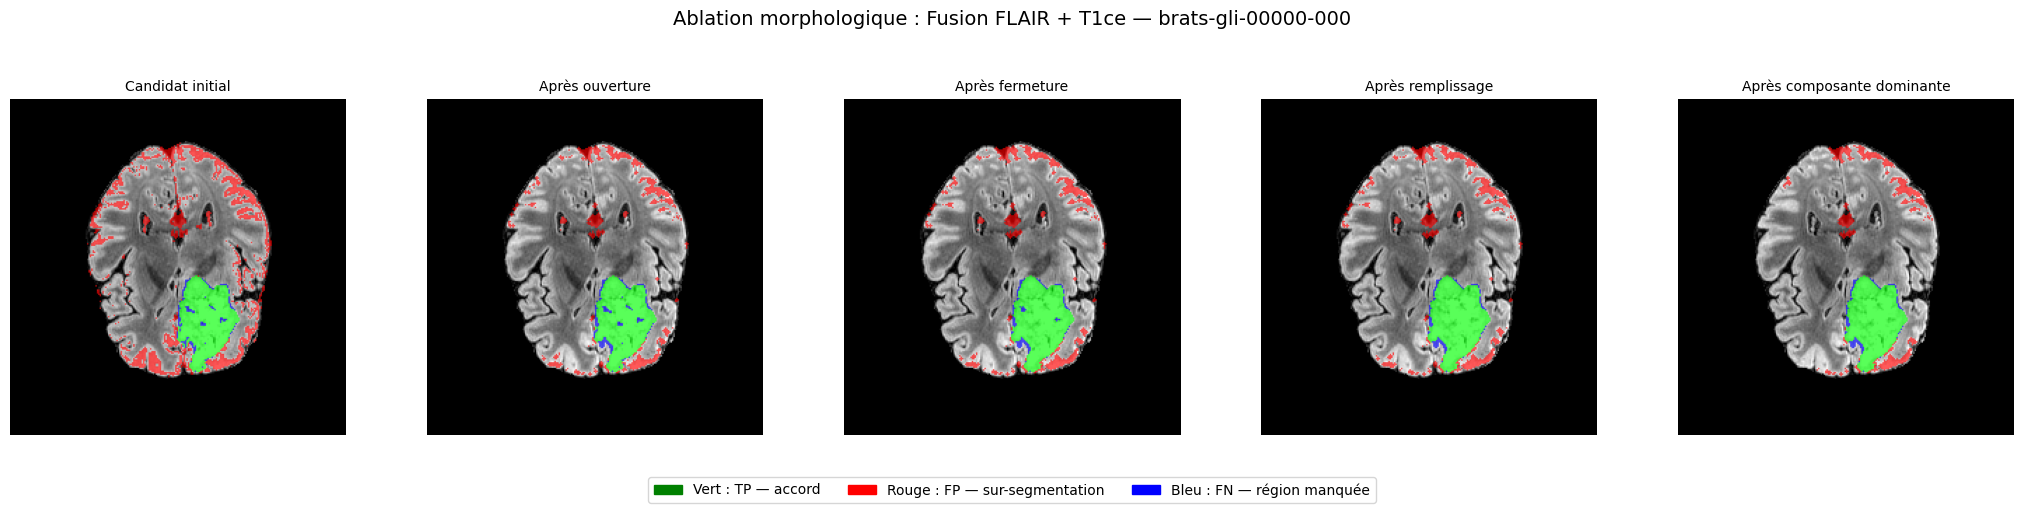

In [ ]:

# Afficher les cinq étapes de chaque méthode sur la même coupe
for method_name, stages in all_stage_sets.items():

    # Choisir l'image de fond correspondant à la méthode
    if method_name == "Fusion FLAIR + T1ce":
        background = flair_norm
    else:
        modality_key = method_name.lower()
        background = modality_experiments[modality_key]["normalized"]

    fig, axes = plt.subplots(1, 5, figsize=(21, 5))

    for ax, (stage_name, pred) in zip(axes, stages.items()):
        overlay = make_comparison_overlay(
            background[:, :, z_eval],
            pred[:, :, z_eval],
            expert_WT[:, :, z_eval]
        )

        ax.imshow(np.rot90(overlay))
        ax.set_title(stage_name, fontsize=10)
        ax.axis("off")

    fig.suptitle(
        f"Ablation morphologique : {method_name} — {CASE_ID}",
        fontsize=14
    )

    fig.legend(
        handles=legend_items,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, -0.02)
    )

    plt.tight_layout(rect=[0, 0.10, 1, 0.90])
    plt.show()


## 13. Étudier l'influence du seuil et de la taille de l'élément structurant

En morphologie mathématique, le résultat dépend directement de la forme et de la taille de `B`. Cette expérience fait varier le quantile de seuillage et le rayon physique, puis mesure le volume et le Dice WT.

**Précaution :** cette grille est une analyse de sensibilité sur le patient affiché. Choisir le meilleur résultat sur le même patient qui sert à présenter la méthode crée un biais d'optimisme ; une validation sérieuse doit séparer patients de réglage et patients de test.

In [ ]:
sensitivity_rows = []
for q in [0.85, 0.90, 0.95]:
    flair_c, _, _ = threshold_candidate(loaded["flair"][1], q)
    if "t1ce" in loaded:
        t1_c, _, _ = threshold_candidate(loaded["t1ce"][1], min(q+0.03, 0.99))
    else:
        t1_c = np.zeros_like(flair_c)
    candidate = flair_c | t1_c
    for radius_mm in [0.5, 1.0, 2.0]:
        se = physical_ball(radius_mm, spacing)
        op = morphology.binary_opening(candidate, footprint=se)
        cl = morphology.binary_closing(op, footprint=se)
        fill = np.stack([ndimage.binary_fill_holes(cl[:, :, k]) for k in range(cl.shape[2])], axis=2)
        pred, _, ncc = largest_component(fill)
        sensitivity_rows.append({
            "FLAIR_quantile": q, "T1ce_quantile": min(q+0.03, 0.99),
            "radius_mm": radius_mm, "components_before_selection": ncc,
            "voxels": int(pred.sum()), "volume_mm3": pred.sum()*np.prod(spacing),
            "Dice_WT": dice(pred, expert_regions["WT"])
        })

sensitivity_df = pd.DataFrame(sensitivity_rows).sort_values("Dice_WT", ascending=False)
display(sensitivity_df)
display(sensitivity_df.pivot(index="radius_mm", columns="FLAIR_quantile", values="Dice_WT"))

,FLAIR_quantile,T1ce_quantile,radius_mm,components_before_selection,voxels,volume_mm3,Dice_WT
5,0.90,0.93,2.0,51,51743,51743.0,0.920219
2,0.85,0.88,2.0,73,61659,61659.0,0.908527
7,0.95,0.98,1.0,182,35326,35326.0,0.741760
8,0.95,0.98,2.0,19,26794,26794.0,0.636821
4,0.90,0.93,1.0,501,117725,117725.0,0.592264
6,0.95,0.98,0.5,5060,80578,80578.0,0.560156
3,0.90,0.93,0.5,6633,217909,217909.0,0.381921
1,0.85,0.88,1.0,568,233463,233463.0,0.380007
0,0.85,0.88,0.5,7327,376592,376592.0,0.256821


FLAIR_quantile,0.85,0.90,0.95
radius_mm,,,
0.5,0.256821,0.381921,0.560156
1.0,0.380007,0.592264,0.741760
2.0,0.908527,0.920219,0.636821


## 14. Mesurer la morphologie 3D du masque

Au-delà du score de segmentation, MorphoRT extrait des descripteurs géométriques :
- volume : nombre de voxels × volume voxel ;
- surface : aire du maillage triangulé ;
- sphéricité : comparaison à une sphère de même volume (1 pour une sphère idéale) ;
- compacité \(V/A^{3/2}\) ;
- diamètre sphérique équivalent et dimensions de la boîte englobante.

Les mesures sont calculées en millimètres à partir du spacing NIfTI. La surface dépend de la discrétisation du maillage et doit être interprétée comme une estimation.

In [ ]:
def morphology_metrics(mask, spacing_mm):
    mask = np.asarray(mask, dtype=bool)
    spacing_mm = np.asarray(spacing_mm, dtype=float)
    if spacing_mm.shape != (3,) or np.any(spacing_mm <= 0):
        raise ValueError("Spacing 3D invalide.")
    n = int(mask.sum())
    voxel_volume = float(np.prod(spacing_mm))
    volume = n * voxel_volume
    out = {
        "voxel_count": n, "volume_mm3": volume, "volume_cm3": volume/1000,
        "surface_mm2": np.nan, "sphericity": np.nan,
        "compactness_V_over_A32": np.nan,
        "equivalent_spherical_diameter_mm": np.nan,
        "bbox_x_mm": np.nan, "bbox_y_mm": np.nan, "bbox_z_mm": np.nan
    }
    if n == 0:
        return out
    coords = np.argwhere(mask)
    extent = (coords.max(axis=0)-coords.min(axis=0)+1)*spacing_mm
    out.update({
        "bbox_x_mm": float(extent[0]), "bbox_y_mm": float(extent[1]),
        "bbox_z_mm": float(extent[2]),
        "equivalent_spherical_diameter_mm": float((6*volume/np.pi)**(1/3))
    })
    try:
        padded = np.pad(mask.astype(np.uint8), 1)
        verts, faces, _, _ = measure.marching_cubes(
            padded, level=0.5, spacing=tuple(spacing_mm)
        )
        area = float(measure.mesh_surface_area(verts, faces))
        out["surface_mm2"] = area
        if area > 0 and volume > 0:
            out["sphericity"] = float(np.pi**(1/3)*(6*volume)**(2/3)/area)
            out["compactness_V_over_A32"] = float(volume/(area**1.5))
    except (ValueError, RuntimeError) as exc:
        warnings.warn(f"Surface non calculable : {exc}")
    return out

metrics_comparison = pd.DataFrame([
    {"mask": name, **morphology_metrics(mask, spacing)}
    for name, mask in {
        "Candidat initial": initial_candidate,
        "Après ouverture": after_opening,
        "Après fermeture": after_closing,
        "Masque final": final_mask,
        "WT expert": expert_regions["WT"]
    }.items()
])
display(metrics_comparison)

,mask,voxel_count,volume_mm3,volume_cm3,surface_mm2,sphericity,compactness_V_over_A32,equivalent_spherical_diameter_mm,bbox_x_mm,bbox_y_mm,bbox_z_mm
0,Candidat initial,204043,204043.0,204.043,277178.875000,0.060470,0.001398,73.042286,134.0,170.0,141.0
1,Après ouverture,108860,108860.0,108.860,88002.062500,0.125286,0.004170,59.241117,132.0,168.0,132.0
2,Après fermeture,113328,113328.0,113.328,81987.539062,0.138132,0.004827,60.040763,132.0,168.0,132.0
3,Masque final,101742,101742.0,101.742,57716.054688,0.182609,0.007338,57.920711,123.0,168.0,116.0
4,WT expert,57305,57305.0,57.305,10678.119141,0.673159,0.051934,47.833405,46.0,76.0,47.0


## 15. Évaluer plusieurs patients BraTS

Nous répétons la même procédure sur les patients disposant de FLAIR et d'une annotation experte. Les résultats par patient sont conservés : moyenne seule peut masquer une forte variabilité.

La fonction de segmentation reprend les seuils et le rayon explicitement choisis ci-dessus. Les scores sont des résultats de baseline ; ils ne doivent pas être présentés comme une validation clinique ou comme une comparaison équitable à un réseau entraîné.

Patients évalués : 19


,case_id,components,candidate_voxels,dice_WT,jaccard_WT,dice_TC,jaccard_TC,dice_ET,jaccard_ET
0,brats-gli-00000-000,427,204043,0.625073,0.454623,0.580052,0.408502,0.456434,0.295701
1,brats-gli-00002-000,236,200887,0.739304,0.586425,0.341763,0.206100,0.227094,0.128092
2,brats-gli-00003-000,335,225732,0.944587,0.894993,0.612530,0.441472,0.405415,0.254245
3,brats-gli-00005-000,173,180061,0.810650,0.681590,0.502442,0.335508,0.281672,0.163922
4,brats-gli-00006-000,202,204308,0.944725,0.895240,0.531855,0.362263,0.311160,0.184245


,count,mean,std,median,min,max
dice_WT,19.0,0.577790,0.333141,0.712665,0.0,0.944725
dice_TC,19.0,0.279404,0.262599,0.341763,0.0,0.743974
dice_ET,19.0,0.182637,0.187908,0.118120,0.0,0.568689


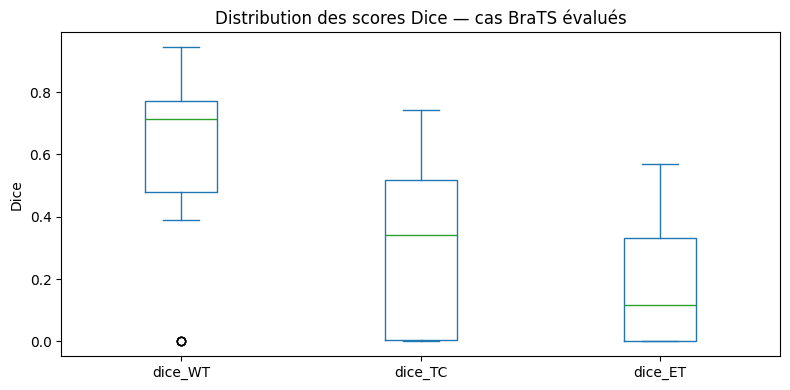

In [ ]:
def run_morphological_pipeline(case, flair_q=FLAIR_QUANTILE,
                               t1ce_q=T1CE_QUANTILE, radius_mm=RADIUS_MM):
    fmask, _, _ = threshold_candidate(case["flair"][1], flair_q)
    if "t1ce" in case:
        tmask, _, _ = threshold_candidate(case["t1ce"][1], t1ce_q)
    else:
        tmask = np.zeros_like(fmask)
    candidate = fmask | tmask
    se = physical_ball(radius_mm, case["flair"][2])
    op = morphology.binary_opening(candidate, footprint=se)
    cl = morphology.binary_closing(op, footprint=se)
    fill = np.stack([ndimage.binary_fill_holes(cl[:, :, k]) for k in range(cl.shape[2])], axis=2)
    pred, _, ncc = largest_component(fill)
    return pred, {"components": ncc, "candidate_voxels": int(candidate.sum())}

validation_rows, metric_rows = [], []
for idx, pid in enumerate(available_cases):
    try:
        case = loaded if pid == CASE_ID else load_case(pid)
        pred, info = run_morphological_pipeline(case)
        refs = brats_regions(case["seg"][1])
        row = {"case_id": pid, **info}
        for region, ref in refs.items():
            row[f"dice_{region}"] = dice(pred, ref)
            row[f"jaccard_{region}"] = jaccard(pred, ref)
        validation_rows.append(row)
        metric_rows.append({
            "case_id": pid, "source": "morphological_candidate",
            **morphology_metrics(pred, case["flair"][2])
        })
        for region, ref in refs.items():
            metric_rows.append({
                "case_id": pid, "source": f"expert_{region}",
                **morphology_metrics(ref, case["seg"][2])
            })
    except Exception as exc:
        print(f"{pid} ignoré : {type(exc).__name__}: {exc}")

validation_df = pd.DataFrame(validation_rows)
brats_metrics = pd.DataFrame(metric_rows)
print("Patients évalués :", len(validation_df))
display(validation_df.head())
if not validation_df.empty:
    dice_cols = [c for c in validation_df if c.startswith("dice_")]
    display(validation_df[dice_cols].agg(["count", "mean", "std", "median", "min", "max"]).T)
    validation_df[dice_cols].plot(kind="box", figsize=(8, 4))
    plt.title("Distribution des scores Dice — cas BraTS évalués")
    plt.ylabel("Dice"); plt.tight_layout(); plt.show()

## 16. Explorer les tables LUMIERE

Le document de projet distingue les rôles des jeux de données : BraTS sert à développer/valider la segmentation, tandis que LUMIERE est destiné à l'analyse longitudinale. Nous lisons les fichiers tabulaires présents sans supposer qu'une colonne radiomique ou clinique est un volume tumoral.

La signification des variables, leurs unités et les identifiants doivent être confirmés dans le dictionnaire de données avant tout ajustement.

In [ ]:
TABLE_EXT = {".csv", ".tsv", ".txt", ".xlsx", ".xls", ".parquet"}

def read_table(path):
    ext = Path(path).suffix.lower()
    if ext == ".csv":
        for enc in ["utf-8", "utf-8-sig", "latin1"]:
            try:
                return pd.read_csv(path, sep=None, engine="python", encoding=enc)
            except Exception:
                pass
        raise ValueError("CSV illisible")
    if ext in {".tsv", ".txt"}:
        return pd.read_csv(path, sep="\\t")
    if ext in {".xlsx", ".xls"}:
        return pd.read_excel(path)
    if ext == ".parquet":
        return pd.read_parquet(path)
    raise ValueError("Format non pris en charge")

lumiere_tables = {}
if LUMIERE_DIR.is_dir():
    for p in LUMIERE_DIR.rglob("*"):
        if p.is_file() and p.suffix.lower() in TABLE_EXT:
            try:
                key = str(p.relative_to(LUMIERE_DIR))
                lumiere_tables[key] = read_table(p)
                print("\\n", key, lumiere_tables[key].shape)
                display(lumiere_tables[key].head(3))
            except Exception as exc:
                print("Fichier ignoré :", p, "|", exc)
print("Tables lues :", len(lumiere_tables))

\n LUMIERE-datacompleteness.csv (638, 10)


,Patient,Timepoint,CT1,T1,T2,FLAIR,DeepBraTumIA,HD-GLIO-AUTO,DeepBraTumIA-CoLlAGe,HD-GLIO-AUTO-CoLlAGe
0,Patient-001,week-000-1,x,x,x,x,x,x,x,x
1,Patient-001,week-000-2,x,x,x,x,x,x,x,x
2,Patient-001,week-044,x,x,x,x,x,x,x,x


\n LUMIERE-Demographics_Pathology.csv (91, 8)


,Patient,Survival time (weeks),Sex,Age at surgery (years),IDH (WT: wild type),IDH method,MGMT qualitative,MGMT quantitative
0,Patient-001,89,female,57,WT,BES,methylated,na
1,Patient-002,48,female,71,na,na,not methylated,0.00%
2,Patient-003,40,male,39,WT,Immuno,not methylated,0.00%


\n LUMIERE-ExpertRating-v202211.csv (616, 6)


,Patient,Date,LessThan3Months,NonMeasurableLesions,"Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)","Rating rationale (CRET: complete resection of the enhancing tumor, PRET: partial resection of the enhancing tumor, T2-Progr.: T2-Progression, L: Lesion)"
0,Patient-001,week-000-1,NaN,NaN,Pre-Op,NaN
1,Patient-001,week-000-2,NaN,NaN,Post-Op,CRET
2,Patient-001,week-044,NaN,NaN,SD,NaN


... (3 outputs left out)

,Patient,Time point,Image,Mask,Label name,Label,Sequence,Reader,diagnostics_Versions_PyRadiomics,diagnostics_Versions_Numpy,...,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Necrosis,1,CT1,N-A,v3.0.1,1.21.5,...,0.003813,0.001314,0.67575,1435.078288,0.000947,0.685318,0.000412,51102.037784,0.705834,1.873749
1,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Contrast-enhancing,2,CT1,N-A,v3.0.1,1.21.5,...,0.097978,0.003477,0.24184,166.336912,0.000756,1.138789,0.000879,2183.887749,0.114565,0.639744
2,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Edema,3,CT1,N-A,v3.0.1,1.21.5,...,0.061886,0.002833,0.19303,138.156487,0.000546,1.491074,0.000403,2995.649695,0.064248,0.690667


\n LUMIERE-pyradiomics-hdglioauto-features.csv (4792, 152)


,Patient,Time point,Image,Mask,Label name,Label,Sequence,Reader,diagnostics_Versions_PyRadiomics,diagnostics_Versions_Numpy,...,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Non-enhancing,1,CT1,N-A,v3.0.1,1.21.5,...,0.012244,0.000906,0.280866,540.236355,0.000289,0.510957,0.000404,9942.573976,0.060366,1.641709
1,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Contrast-enhancing,2,CT1,N-A,v3.0.1,1.21.5,...,0.001376,0.000386,0.666140,3280.608056,0.000281,0.224369,0.000620,56023.732677,0.532071,3.181840
2,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Non-enhancing,1,T1,N-A,v3.0.1,1.21.5,...,0.016478,0.000821,0.175600,251.495284,0.000173,1.144406,0.000331,2251.616408,0.036342,0.511272


Tables lues : 6


In [ ]:
from pathlib import Path

print("Dossier LUMIERE :", LUMIERE_DIR)
print("Existe :", LUMIERE_DIR.exists())

if LUMIERE_DIR.exists():
    for p in list(LUMIERE_DIR.iterdir())[:30]:
        print(p.name, "—", "dossier" if p.is_dir() else "fichier")

Dossier LUMIERE : /content/drive/MyDrive/MorphoRT/brats/lumiere/lumiere
Existe : True
LUMIERE-datacompleteness.csv — fichier
LUMIERE-Demographics_Pathology.csv — fichier
LUMIERE-ExpertRating-v202211.csv — fichier
LUMIERE-MRinfo.csv — fichier
LUMIERE-pyradiomics-deepbratumia-features.csv — fichier
LUMIERE-pyradiomics-hdglioauto-features.csv — fichier


In [ ]:
import pandas as pd
from pathlib import Path

LUMIERE_DIR = Path(
    "/content/drive/MyDrive/MorphoRT/brats/lumiere/lumiere"
)

csv_files = list(LUMIERE_DIR.glob("*.csv"))

for file in csv_files:
    print("\n" + "=" * 80)
    print("FICHIER :", file.name)

    try:
        df = pd.read_csv(file)

        print("Dimensions :", df.shape)
        print("\nColonnes :")
        print(df.columns.tolist())

        print("\nPremières lignes :")
        display(df.head(3))

    except Exception as e:
        print("Erreur de lecture :", e)


FICHIER : LUMIERE-datacompleteness.csv
Dimensions : (638, 10)

Colonnes :
['Patient', 'Timepoint', 'CT1', 'T1', 'T2', 'FLAIR', 'DeepBraTumIA', 'HD-GLIO-AUTO', 'DeepBraTumIA-CoLlAGe', 'HD-GLIO-AUTO-CoLlAGe']

Premières lignes :


,Patient,Timepoint,CT1,T1,T2,FLAIR,DeepBraTumIA,HD-GLIO-AUTO,DeepBraTumIA-CoLlAGe,HD-GLIO-AUTO-CoLlAGe
0,Patient-001,week-000-1,x,x,x,x,x,x,x,x
1,Patient-001,week-000-2,x,x,x,x,x,x,x,x
2,Patient-001,week-044,x,x,x,x,x,x,x,x



FICHIER : LUMIERE-Demographics_Pathology.csv
Dimensions : (91, 8)

Colonnes :
['Patient', 'Survival time (weeks)', 'Sex', 'Age at surgery (years)', 'IDH (WT: wild type)', 'IDH method', 'MGMT qualitative', 'MGMT quantitative']

Premières lignes :


,Patient,Survival time (weeks),Sex,Age at surgery (years),IDH (WT: wild type),IDH method,MGMT qualitative,MGMT quantitative
0,Patient-001,89,female,57,WT,BES,methylated,na
1,Patient-002,48,female,71,na,na,not methylated,0.00%
2,Patient-003,40,male,39,WT,Immuno,not methylated,0.00%



FICHIER : LUMIERE-ExpertRating-v202211.csv
Dimensions : (616, 6)

Colonnes :
['Patient', 'Date', 'LessThan3Months', 'NonMeasurableLesions', 'Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)', 'Rating rationale (CRET: complete resection of the enhancing tumor, PRET: partial resection of the enhancing tumor, T2-Progr.: T2-Progression, L: Lesion)']

Premières lignes :


,Patient,Date,LessThan3Months,NonMeasurableLesions,"Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)","Rating rationale (CRET: complete resection of the enhancing tumor, PRET: partial resection of the enhancing tumor, T2-Progr.: T2-Progression, L: Lesion)"
0,Patient-001,week-000-1,NaN,NaN,Pre-Op,NaN
1,Patient-001,week-000-2,NaN,NaN,Post-Op,CRET
2,Patient-001,week-044,NaN,NaN,SD,NaN


... (2 outputs left out)


FICHIER : LUMIERE-pyradiomics-deepbratumia-features.csv
Dimensions : (7188, 152)

Colonnes :
['Patient', 'Time point', 'Image', 'Mask', 'Label name', 'Label', 'Sequence', 'Reader', 'diagnostics_Versions_PyRadiomics', 'diagnostics_Versions_Numpy', 'diagnostics_Versions_SimpleITK', 'diagnostics_Versions_PyWavelet', 'diagnostics_Versions_Python', 'diagnostics_Configuration_Settings', 'diagnostics_Configuration_EnabledImageTypes', 'diagnostics_Image-original_Hash', 'diagnostics_Image-original_Dimensionality', 'diagnostics_Image-original_Spacing', 'diagnostics_Image-original_Size', 'diagnostics_Image-original_Mean', 'diagnostics_Image-original_Minimum', 'diagnostics_Image-original_Maximum', 'diagnostics_Mask-original_Hash', 'diagnostics_Mask-original_Spacing', 'diagnostics_Mask-original_Size', 'diagnostics_Mask-original_BoundingBox', 'diagnostics_Mask-original_VoxelNum', 'diagnostics_Mask-original_VolumeNum', 'diagnostics_Mask-original_CenterOfMassIndex', 'diagnostics_Mask-original_CenterO

,Patient,Time point,Image,Mask,Label name,Label,Sequence,Reader,diagnostics_Versions_PyRadiomics,diagnostics_Versions_Numpy,...,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Necrosis,1,CT1,N-A,v3.0.1,1.21.5,...,0.003813,0.001314,0.67575,1435.078288,0.000947,0.685318,0.000412,51102.037784,0.705834,1.873749
1,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Contrast-enhancing,2,CT1,N-A,v3.0.1,1.21.5,...,0.097978,0.003477,0.24184,166.336912,0.000756,1.138789,0.000879,2183.887749,0.114565,0.639744
2,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Edema,3,CT1,N-A,v3.0.1,1.21.5,...,0.061886,0.002833,0.19303,138.156487,0.000546,1.491074,0.000403,2995.649695,0.064248,0.690667



FICHIER : LUMIERE-pyradiomics-hdglioauto-features.csv
Dimensions : (4792, 152)

Colonnes :
['Patient', 'Time point', 'Image', 'Mask', 'Label name', 'Label', 'Sequence', 'Reader', 'diagnostics_Versions_PyRadiomics', 'diagnostics_Versions_Numpy', 'diagnostics_Versions_SimpleITK', 'diagnostics_Versions_PyWavelet', 'diagnostics_Versions_Python', 'diagnostics_Configuration_Settings', 'diagnostics_Configuration_EnabledImageTypes', 'diagnostics_Image-original_Hash', 'diagnostics_Image-original_Dimensionality', 'diagnostics_Image-original_Spacing', 'diagnostics_Image-original_Size', 'diagnostics_Image-original_Mean', 'diagnostics_Image-original_Minimum', 'diagnostics_Image-original_Maximum', 'diagnostics_Mask-original_Hash', 'diagnostics_Mask-original_Spacing', 'diagnostics_Mask-original_Size', 'diagnostics_Mask-original_BoundingBox', 'diagnostics_Mask-original_VoxelNum', 'diagnostics_Mask-original_VolumeNum', 'diagnostics_Mask-original_CenterOfMassIndex', 'diagnostics_Mask-original_CenterOfM

,Patient,Time point,Image,Mask,Label name,Label,Sequence,Reader,diagnostics_Versions_PyRadiomics,diagnostics_Versions_Numpy,...,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Non-enhancing,1,CT1,N-A,v3.0.1,1.21.5,...,0.012244,0.000906,0.280866,540.236355,0.000289,0.510957,0.000404,9942.573976,0.060366,1.641709
1,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Contrast-enhancing,2,CT1,N-A,v3.0.1,1.21.5,...,0.001376,0.000386,0.666140,3280.608056,0.000281,0.224369,0.000620,56023.732677,0.532071,3.181840
2,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Non-enhancing,1,T1,N-A,v3.0.1,1.21.5,...,0.016478,0.000821,0.175600,251.495284,0.000173,1.144406,0.000331,2251.616408,0.036342,0.511272


## 17. Vérifier les colonnes et les valeurs manquantes de LUMIERE

Cette étape est une inspection, pas une interprétation automatique. Elle sert à identifier les noms de colonnes candidates pour l'identifiant patient, la date de visite et le volume, puis à vérifier leurs formats.

In [ ]:
for name, df in lumiere_tables.items():
    print("\\nTABLE :", name, "| dimensions :", df.shape)
    profile = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_n": df.isna().sum(),
        "missing_pct": (100*df.isna().mean()).round(2),
        "n_unique": df.nunique(dropna=True)
    })
    display(profile)
    display(df.head(5))

\nTABLE : LUMIERE-datacompleteness.csv | dimensions : (638, 10)


,dtype,missing_n,missing_pct,n_unique
Patient,object,0,0.00,91
Timepoint,object,0,0.00,166
CT1,object,6,0.94,1
T1,object,21,3.29,1
T2,object,12,1.88,1
FLAIR,object,26,4.08,1
DeepBraTumIA,object,39,6.11,1
HD-GLIO-AUTO,object,39,6.11,1
DeepBraTumIA-CoLlAGe,object,51,7.99,1
HD-GLIO-AUTO-CoLlAGe,object,62,9.72,1


,Patient,Timepoint,CT1,T1,T2,FLAIR,DeepBraTumIA,HD-GLIO-AUTO,DeepBraTumIA-CoLlAGe,HD-GLIO-AUTO-CoLlAGe
0,Patient-001,week-000-1,x,x,x,x,x,x,x,x
1,Patient-001,week-000-2,x,x,x,x,x,x,x,x
2,Patient-001,week-044,x,x,x,x,x,x,x,x
3,Patient-001,week-056,x,x,x,x,x,x,x,x
4,Patient-002,week-000,x,x,x,x,x,x,x,x


\nTABLE : LUMIERE-Demographics_Pathology.csv | dimensions : (91, 8)


,dtype,missing_n,missing_pct,n_unique
Patient,object,0,0.0,91
Survival time (weeks),object,0,0.0,65
Sex,object,0,0.0,2
Age at surgery (years),int64,0,0.0,37
IDH (WT: wild type),object,0,0.0,5
IDH method,object,0,0.0,4
MGMT qualitative,object,0,0.0,3
MGMT quantitative,object,0,0.0,19


,Patient,Survival time (weeks),Sex,Age at surgery (years),IDH (WT: wild type),IDH method,MGMT qualitative,MGMT quantitative
0,Patient-001,89,female,57,WT,BES,methylated,na
1,Patient-002,48,female,71,na,na,not methylated,0.00%
2,Patient-003,40,male,39,WT,Immuno,not methylated,0.00%
3,Patient-004,110,male,69,WT,Sanger Sequencing,not methylated,0.00%
4,Patient-005,53,male,66,WT,Immuno,not methylated,0.00%


... (8 outputs left out)

,Patient,Time point,Image,Mask,Label name,Label,Sequence,Reader,diagnostics_Versions_PyRadiomics,diagnostics_Versions_Numpy,...,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Necrosis,1,CT1,N-A,v3.0.1,1.21.5,...,0.003813,0.001314,0.675750,1435.078288,0.000947,0.685318,0.000412,51102.037784,0.705834,1.873749
1,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Contrast-enhancing,2,CT1,N-A,v3.0.1,1.21.5,...,0.097978,0.003477,0.241840,166.336912,0.000756,1.138789,0.000879,2183.887749,0.114565,0.639744
2,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Edema,3,CT1,N-A,v3.0.1,1.21.5,...,0.061886,0.002833,0.193030,138.156487,0.000546,1.491074,0.000403,2995.649695,0.064248,0.690667
3,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Necrosis,1,T1,N-A,v3.0.1,1.21.5,...,0.029329,0.001352,0.158093,145.047886,0.000410,0.719679,0.000672,1428.503143,0.032186,0.992977
4,Patient-001,week-000-1,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Patient-001/week-000-1/DeepBraTumIA-segmentati...,Contrast-enhancing,2,T1,N-A,v3.0.1,1.21.5,...,0.176176,0.005064,0.116959,35.106445,0.000681,1.992956,0.000976,480.360529,0.047990,0.345623


\nTABLE : LUMIERE-pyradiomics-hdglioauto-features.csv | dimensions : (4792, 152)


,dtype,missing_n,missing_pct,n_unique
Patient,object,0,0.00,91
Time point,object,0,0.00,160
Image,object,0,0.00,2396
Mask,object,0,0.00,599
Label name,object,0,0.00,2
...,...,...,...,...
original_ngtdm_Busyness,float64,716,14.94,4074
original_ngtdm_Coarseness,float64,716,14.94,4073
original_ngtdm_Complexity,float64,716,14.94,4075
original_ngtdm_Contrast,float64,716,14.94,4075


,Patient,Time point,Image,Mask,Label name,Label,Sequence,Reader,diagnostics_Versions_PyRadiomics,diagnostics_Versions_Numpy,...,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Non-enhancing,1,CT1,N-A,v3.0.1,1.21.5,...,0.012244,0.000906,0.280866,540.236355,0.000289,0.510957,0.000404,9942.573976,0.060366,1.641709
1,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Contrast-enhancing,2,CT1,N-A,v3.0.1,1.21.5,...,0.001376,0.000386,0.666140,3280.608056,0.000281,0.224369,0.000620,56023.732677,0.532071,3.181840
2,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Non-enhancing,1,T1,N-A,v3.0.1,1.21.5,...,0.016478,0.000821,0.175600,251.495284,0.000173,1.144406,0.000331,2251.616408,0.036342,0.511272
3,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Contrast-enhancing,2,T1,N-A,v3.0.1,1.21.5,...,0.012588,0.000686,0.186657,322.568287,0.000199,0.426495,0.000702,2453.956759,0.025368,1.542067
4,Patient-001,week-000-1,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Imaging/Patient-001/week-000-1/HD-GLIO-AUTO-se...,Non-enhancing,1,T2,N-A,v3.0.1,1.21.5,...,0.002017,0.000441,0.496685,2029.590484,0.000255,0.251492,0.000519,25043.575789,0.272552,2.553400


## 18. Construire une série longitudinale de volumes — configuration à confirmer

Un modèle de croissance exige plusieurs volumes mesurés chez **le même patient à des dates différentes**. Les variables ci-dessous restent à `None` volontairement : il faut les remplir après inspection des tables et du dictionnaire LUMIERE.

`VOLUME_UNIT` doit être `"mm3"` ou `"cm3"`. Aucune variable ne sera considérée comme volume tumoral sans justification documentaire.

## 19. Vérifier le nombre de visites par patient

Nous comptons les temps distincts et la durée de suivi. Trois temps distincts constituent un minimum technique pour tenter un ajustement à deux paramètres ; ce minimum ne garantit pas une estimation fiable.

In [ ]:

import pandas as pd
import re
from pathlib import Path

LUMIERE_DIR = Path(
    "/content/drive/MyDrive/MorphoRT/brats/lumiere/lumiere"
)

# Charger les métadonnées longitudinales
completeness = pd.read_csv(
    LUMIERE_DIR / "LUMIERE-datacompleteness.csv"
)

mr_info = pd.read_csv(
    LUMIERE_DIR / "LUMIERE-MRinfo.csv"
)

expert_ratings = pd.read_csv(
    LUMIERE_DIR / "LUMIERE-ExpertRating-v202211.csv"
)

# Identifier les patients ayant plusieurs visites
visits = (
    completeness[["Patient", "Timepoint"]]
    .drop_duplicates()
    .dropna()
)

visit_counts = visits.groupby("Patient")["Timepoint"].nunique()

longitudinal_patients = visit_counts[visit_counts >= 2].index.tolist()

print("Nombre de patients avec au moins 2 visites :",
      len(longitudinal_patients))

print("\nExemple de série longitudinale :")

PATIENT_ID = "Patient-001"

patient_visits = visits[
    visits["Patient"] == PATIENT_ID
].copy()

display(patient_visits)

if len(patient_visits) >= 2:
    print("Série longitudinale détectée pour", PATIENT_ID)
else:
    print("Pas assez de visites pour ce patient.")


Nombre de patients avec au moins 2 visites : 91

Exemple de série longitudinale :


,Patient,Timepoint
0,Patient-001,week-000-1
1,Patient-001,week-000-2
2,Patient-001,week-044
3,Patient-001,week-056


Série longitudinale détectée pour Patient-001


In [ ]:

import matplotlib.pyplot as plt

features = pd.read_csv(
    LUMIERE_DIR /
    "LUMIERE-pyradiomics-deepbratumia-features.csv"
)

# Sélectionner un patient
patient_features = features[
    features["Patient"] == PATIENT_ID
].copy()

# Vérifier les séquences et régions disponibles
print("Séquences :", patient_features["Sequence"].unique())
print("Régions :", patient_features["Label name"].unique())

# Examiner les volumes par visite, séquence et région
volume_table = (
    patient_features[
        ["Time point", "Sequence", "Label name",
         "original_shape_MeshVolume"]
    ]
    .dropna(subset=["original_shape_MeshVolume"])
    .sort_values(["Time point", "Sequence", "Label name"])
)

display(volume_table)


Séquences : ['CT1' 'T1' 'T2' 'FLAIR']
Régions : ['Necrosis' 'Contrast-enhancing' 'Edema']


,Time point,Sequence,Label name,original_shape_MeshVolume
1,week-000-1,CT1,Contrast-enhancing,12777.791667
2,week-000-1,CT1,Edema,43419.500000
0,week-000-1,CT1,Necrosis,16714.541667
10,week-000-1,FLAIR,Contrast-enhancing,12777.791667
11,week-000-1,FLAIR,Edema,43419.500000
9,week-000-1,FLAIR,Necrosis,16714.541667
4,week-000-1,T1,Contrast-enhancing,12777.791667
5,week-000-1,T1,Edema,43419.500000
3,week-000-1,T1,Necrosis,16714.541667
7,week-000-1,T2,Contrast-enhancing,12777.791667


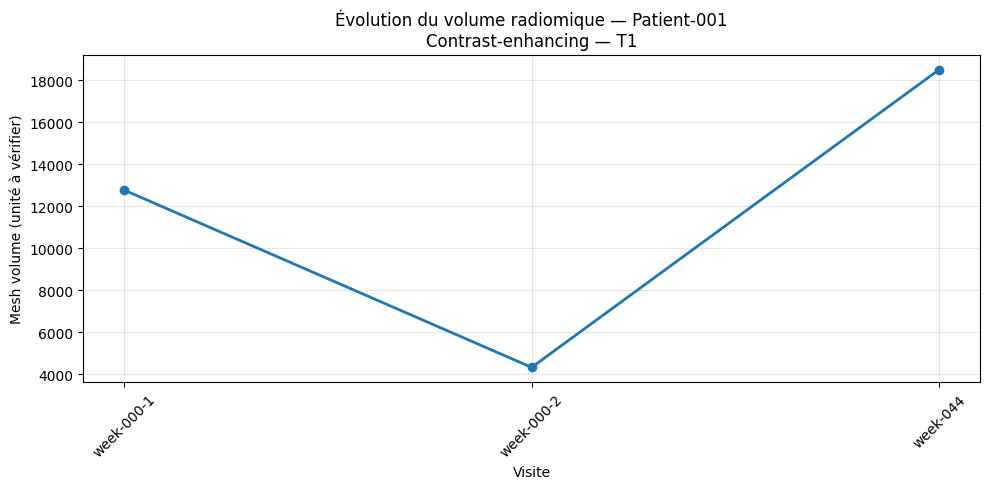

In [ ]:

SEQUENCE = "T1"
REGION = "Contrast-enhancing"

curve_data = volume_table[
    (volume_table["Sequence"] == SEQUENCE) &
    (volume_table["Label name"] == REGION)
].copy()

if len(curve_data) >= 2:
    plt.figure(figsize=(10, 5))

    plt.plot(
        curve_data["Time point"],
        curve_data["original_shape_MeshVolume"],
        marker="o",
        linewidth=2
    )

    plt.title(
        f"Évolution du volume radiomique — {PATIENT_ID}\n"
        f"{REGION} — {SEQUENCE}"
    )
    plt.xlabel("Visite")
    plt.ylabel("Mesh volume (unité à vérifier)")
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Pas assez de mesures pour tracer cette courbe.")


In [ ]:
LUMIERE_TABLE_NAME = None
PATIENT_ID_COL = None
TIME_COL = None
VOLUME_COL = None
VOLUME_UNIT = None  # "mm3" ou "cm3"
TIME_IS_DATE = True

def make_longitudinal(tables, table_name, patient_col, time_col,
                      volume_col, volume_unit, time_is_date=True):
    if table_name not in tables:
        raise KeyError("Table LUMIERE absente.")
    if volume_unit not in {"mm3", "cm3"}:
        raise ValueError("Unité de volume non justifiée : choisir mm3 ou cm3.")
    df = tables[table_name].copy()
    for col in [patient_col, time_col, volume_col]:
        if col not in df.columns:
            raise KeyError(f"Colonne absente : {col}")
    d = df[[patient_col, time_col, volume_col]].dropna().copy()
    d.columns = ["patient_id", "time_raw", "volume_raw"]
    d["volume_mm3"] = pd.to_numeric(d["volume_raw"], errors="coerce")
    if volume_unit == "cm3":
        d["volume_mm3"] *= 1000
    if time_is_date:
        d["date"] = pd.to_datetime(d["time_raw"], errors="coerce")
        d = d.dropna(subset=["date"])
        d["time_days"] = (
            d["date"] - d.groupby("patient_id")["date"].transform("min")
        ).dt.total_seconds()/86400
    else:
        d["time_days"] = pd.to_numeric(d["time_raw"], errors="coerce")
    d = d.dropna(subset=["time_days", "volume_mm3"])
    d = d[d["volume_mm3"] > 0]
    return d[["patient_id", "time_days", "volume_mm3"]].sort_values(
        ["patient_id", "time_days"]
    )

longitudinal_df = None
if all(v is not None for v in [
    LUMIERE_TABLE_NAME, PATIENT_ID_COL, TIME_COL, VOLUME_COL, VOLUME_UNIT
]):
    longitudinal_df = make_longitudinal(
        lumiere_tables, LUMIERE_TABLE_NAME, PATIENT_ID_COL,
        TIME_COL, VOLUME_COL, VOLUME_UNIT, TIME_IS_DATE
    )
    display(longitudinal_df.head(10))
else:
    print("Série non construite : renseigner les colonnes après vérification documentaire.")

Série non construite : renseigner les colonnes après vérification documentaire.


In [ ]:

# CELLULE 1 — Chargement des données LUMIERE

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

LUMIERE_DIR = Path(
    "/content/drive/MyDrive/MorphoRT/brats/lumiere/lumiere"
)

# Métadonnées et suivi des visites
completeness = pd.read_csv(
    LUMIERE_DIR / "LUMIERE-datacompleteness.csv"
)

mr_info = pd.read_csv(
    LUMIERE_DIR / "LUMIERE-MRinfo.csv"
)

expert_ratings = pd.read_csv(
    LUMIERE_DIR / "LUMIERE-ExpertRating-v202211.csv"
)

# Caractéristiques radiomiques calculées avec DeepBraTumIA
features = pd.read_csv(
    LUMIERE_DIR /
    "LUMIERE-pyradiomics-deepbratumia-features.csv"
)

print("Métadonnées :", completeness.shape)
print("Informations IRM :", mr_info.shape)
print("Évaluations expertes :", expert_ratings.shape)
print("Caractéristiques radiomiques :", features.shape)

print("\nColonnes importantes :")
print(features[
    ["Patient", "Time point", "Sequence",
     "Label name", "original_shape_MeshVolume"]
].head())


Métadonnées : (638, 10)
Informations IRM : (2487, 24)
Évaluations expertes : (616, 6)
Caractéristiques radiomiques : (7188, 152)

Colonnes importantes :
       Patient  Time point Sequence          Label name  \
0  Patient-001  week-000-1      CT1            Necrosis   
1  Patient-001  week-000-1      CT1  Contrast-enhancing   
2  Patient-001  week-000-1      CT1               Edema   
3  Patient-001  week-000-1       T1            Necrosis   
4  Patient-001  week-000-1       T1  Contrast-enhancing   

   original_shape_MeshVolume  
0               16714.541667  
1               12777.791667  
2               43419.500000  
3               16714.541667  
4               12777.791667  


In [ ]:

# CELLULE 2 — Patients avec suivi longitudinal

visits = (
    completeness[["Patient", "Timepoint"]]
    .dropna()
    .drop_duplicates()
)

visit_counts = (
    visits.groupby("Patient")["Timepoint"]
    .nunique()
    .sort_values(ascending=False)
)

longitudinal_patients = visit_counts[
    visit_counts >= 2
]

print("Nombre de patients avec au moins 2 visites :",
      len(longitudinal_patients))

display(
    longitudinal_patients.rename(
        "Nombre de visites"
    ).reset_index().head(15)
)


Nombre de patients avec au moins 2 visites : 91


,Patient,Nombre de visites
0,Patient-067,21
1,Patient-031,18
2,Patient-073,18
3,Patient-078,17
4,Patient-029,15
5,Patient-072,14
6,Patient-042,14
7,Patient-023,14
8,Patient-006,14
9,Patient-019,14


In [ ]:

# CELLULE 3 — Sélection du patient

PATIENT_ID = "Patient-001"

if PATIENT_ID not in longitudinal_patients.index:
    raise ValueError(
        f"{PATIENT_ID} ne possède pas au moins deux visites "
        "dans le tableau de complétude."
    )

patient_visits = (
    visits[visits["Patient"] == PATIENT_ID]
    .copy()
)

print("Patient sélectionné :", PATIENT_ID)
print("Nombre de visites :", len(patient_visits))

display(patient_visits)


Patient sélectionné : Patient-001
Nombre de visites : 4


,Patient,Timepoint
0,Patient-001,week-000-1
1,Patient-001,week-000-2
2,Patient-001,week-044
3,Patient-001,week-056


In [ ]:

# CELLULE 4 — Extraction du temps à partir du nom de visite

def parse_timepoint(value):
    """
    Extrait la semaine et le numéro de visite.
    Exemple :
    week-000-1 -> semaine 0, visite 1
    week-000-2 -> semaine 0, visite 2
    week-044   -> semaine 44, visite 0
    """
    match = re.search(
        r"week-(\d+)(?:-(\d+))?",
        str(value)
    )

    if match is None:
        return pd.Series({
            "Week": np.nan,
            "Visit_order": np.nan
        })

    week = int(match.group(1))
    visit_order = int(match.group(2) or 0)

    return pd.Series({
        "Week": week,
        "Visit_order": visit_order
    })


patient_visits[
    ["Week", "Visit_order"]
] = patient_visits["Timepoint"].apply(parse_timepoint)

patient_visits = patient_visits.sort_values(
    ["Week", "Visit_order"]
).reset_index(drop=True)

display(patient_visits)


,Patient,Timepoint,Week,Visit_order
0,Patient-001,week-000-1,0,1
1,Patient-001,week-000-2,0,2
2,Patient-001,week-044,44,0
3,Patient-001,week-056,56,0


In [ ]:

# CELLULE 5 — Disponibilité des séquences IRM

patient_mri = mr_info[
    mr_info["Patient"] == PATIENT_ID
].copy()

mri_availability = (
    patient_mri.groupby(["Timepoint", "Sequence"])
    .size()
    .unstack(fill_value=0)
)

print("Séquences disponibles pour", PATIENT_ID)
display(mri_availability)


Séquences disponibles pour Patient-001


Sequence,CT1,FLAIR,T1,T2
Timepoint,,,,
week-000-1,1,1,1,1
week-000-2,1,1,1,1
week-044,1,1,1,1
week-056,1,1,1,1


In [ ]:

# CELLULE 6 — Afficher les régions et séquences disponibles

patient_features = features[
    features["Patient"] == PATIENT_ID
].copy()

print("Séquences disponibles :")
print(sorted(patient_features["Sequence"].dropna().unique()))

print("\nRégions tumorales disponibles :")
print(sorted(patient_features["Label name"].dropna().unique()))

print("\nNombre de mesures par région :")
display(
    patient_features["Label name"]
    .value_counts()
    .rename_axis("Région")
    .reset_index(name="Nombre de lignes")
)


Séquences disponibles :
['CT1', 'FLAIR', 'T1', 'T2']

Régions tumorales disponibles :
['Contrast-enhancing', 'Edema', 'Necrosis']

Nombre de mesures par région :


,Région,Nombre de lignes
0,Necrosis,16
1,Contrast-enhancing,16
2,Edema,16


In [ ]:

# CELLULE 7 — Sélection de la région et de la séquence

SEQUENCE = "T1"
REGION = "Contrast-enhancing"

required_columns = [
    "Patient",
    "Time point",
    "Sequence",
    "Label name",
    "original_shape_MeshVolume"
]

missing_columns = [
    col for col in required_columns
    if col not in features.columns
]

if missing_columns:
    raise ValueError(
        f"Colonnes manquantes dans le CSV : {missing_columns}"
    )

selected = patient_features[
    (patient_features["Sequence"] == SEQUENCE) &
    (patient_features["Label name"] == REGION)
].copy()

selected["original_shape_MeshVolume"] = pd.to_numeric(
    selected["original_shape_MeshVolume"],
    errors="coerce"
)

selected = selected.dropna(
    subset=["original_shape_MeshVolume", "Time point"]
)

if selected.empty:
    raise ValueError(
        "Aucune mesure trouvée pour cette combinaison "
        "patient / séquence / région. Vérifie les valeurs affichées."
    )

selected[
    ["Week", "Visit_order"]
] = selected["Time point"].apply(parse_timepoint)

selected = selected.dropna(subset=["Week"])

selected = selected.sort_values(
    ["Week", "Visit_order"]
)

print("Patient :", PATIENT_ID)
print("Séquence :", SEQUENCE)
print("Région :", REGION)
print("Nombre de mesures :", len(selected))

display(
    selected[
        ["Time point", "Week", "Visit_order",
         "original_shape_MeshVolume"]
    ]
)


Patient : Patient-001
Séquence : T1
Région : Contrast-enhancing
Nombre de mesures : 3


,Time point,Week,Visit_order,original_shape_MeshVolume
4,week-000-1,0,1,12777.791667
16,week-000-2,0,2,4322.166667
28,week-044,44,0,18522.666667


In [ ]:

# CELLULE 8 — Contrôle des mesures par visite

measurements_per_visit = (
    selected.groupby("Time point")
    .size()
    .rename("Nombre de mesures")
    .reset_index()
)

display(measurements_per_visit)

# Une valeur représentative par visite :
# médiane en cas de mesures répétées
volume_series = (
    selected.groupby(
        ["Time point", "Week", "Visit_order"],
        as_index=False
    )
    .agg(
        Volume=("original_shape_MeshVolume", "median"),
        Number_of_measurements=(
            "original_shape_MeshVolume", "count"
        )
    )
    .sort_values(["Week", "Visit_order"])
    .reset_index(drop=True)
)

print("Série temporelle obtenue :")
display(volume_series)


,Time point,Nombre de mesures
0,week-000-1,1
1,week-000-2,1
2,week-044,1


Série temporelle obtenue :


,Time point,Week,Visit_order,Volume,Number_of_measurements
0,week-000-1,0,1,12777.791667,1
1,week-000-2,0,2,4322.166667,1
2,week-044,44,0,18522.666667,1


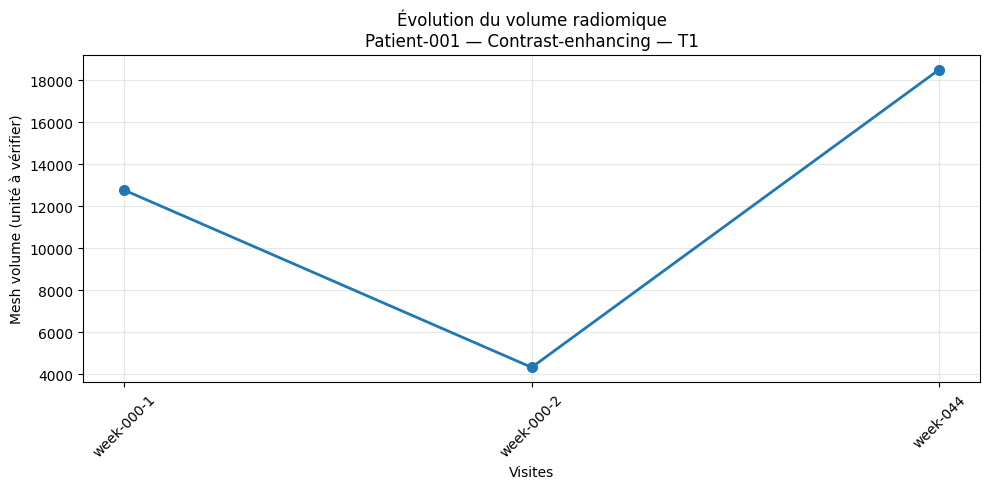

In [ ]:

# CELLULE 9 — Courbe d'évolution du volume radiomique

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(volume_series)),
    volume_series["Volume"],
    marker="o",
    linewidth=2,
    markersize=7
)

plt.xticks(
    range(len(volume_series)),
    volume_series["Time point"],
    rotation=45
)

plt.title(
    f"Évolution du volume radiomique\n"
    f"{PATIENT_ID} — {REGION} — {SEQUENCE}"
)

plt.xlabel("Visites")
plt.ylabel("Mesh volume (unité à vérifier)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# CELLULE 10 — Ajouter les évaluations expertes

patient_ratings = expert_ratings[
    expert_ratings["Patient"] == PATIENT_ID
].copy()

rating_columns = [
    "Patient",
    "Date",
    "Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)"
]

patient_ratings = patient_ratings[
    [col for col in rating_columns if col in patient_ratings.columns]
]

print("Évaluations expertes de", PATIENT_ID)
display(patient_ratings)


Évaluations expertes de Patient-001


,Patient,Date,"Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)"
0,Patient-001,week-000-1,Pre-Op
1,Patient-001,week-000-2,Post-Op
2,Patient-001,week-044,SD
3,Patient-001,week-056,PD


In [ ]:

# CELLULE 11 — Contrôle qualité de la série

print("Nombre de visites :", len(volume_series))
print("Valeurs manquantes :", volume_series["Volume"].isna().sum())
print("Volumes nuls ou négatifs :",
      (volume_series["Volume"] <= 0).sum())

print("\nStatistiques descriptives :")
display(volume_series["Volume"].describe())

if len(volume_series) < 2:
    print("Attention : moins de deux mesures disponibles.")
elif (volume_series["Volume"] <= 0).any():
    print("Attention : des volumes non positifs doivent être vérifiés.")
else:
    print("La série possède au moins deux mesures positives.")


Nombre de visites : 3
Valeurs manquantes : 0
Volumes nuls ou négatifs : 0

Statistiques descriptives :


,Volume
count,3.000000
mean,11874.208333
std,7143.241365
min,4322.166667
25%,8549.979167
50%,12777.791667
75%,15650.229167
max,18522.666667


La série possède au moins deux mesures positives.


In [ ]:

# CELLULE 12 — Définir la visite de référence postopératoire

BASELINE_TIMEPOINT = "week-000-2"

if BASELINE_TIMEPOINT not in volume_series["Time point"].values:
    raise ValueError(
        f"La visite {BASELINE_TIMEPOINT} n'est pas disponible "
        "pour cette séquence et cette région.\n"
        "Visites disponibles : "
        + ", ".join(volume_series["Time point"].astype(str))
    )

baseline_row = volume_series[
    volume_series["Time point"] == BASELINE_TIMEPOINT
].iloc[0]

baseline_week = baseline_row["Week"]
baseline_order = baseline_row["Visit_order"]

# Garder la visite de référence et les visites ultérieures
postoperative_series = volume_series[
    (
        (volume_series["Week"] > baseline_week) |
        (
            (volume_series["Week"] == baseline_week) &
            (volume_series["Visit_order"] >= baseline_order)
        )
    )
].copy()

# Temps écoulé depuis la visite de référence
postoperative_series["t_weeks"] = (
    postoperative_series["Week"] - baseline_week
)

# Si plusieurs visites sont faites la même semaine,
# on utilise leur médiane pour avoir un seul point par semaine.
gompertz_data = (
    postoperative_series
    .groupby("t_weeks", as_index=False)
    .agg(
        Volume=("Volume", "median"),
        Number_of_visits=("Time point", "count"),
        Timepoints=("Time point", lambda x: ", ".join(x))
    )
    .sort_values("t_weeks")
    .reset_index(drop=True)
)

print("Visite de référence :", BASELINE_TIMEPOINT)
print("Semaine de référence :", baseline_week)

display(gompertz_data)

if gompertz_data["t_weeks"].nunique() < 2:
    print(
        "Attention : il faut au moins deux semaines distinctes "
        "pour ajuster un modèle de croissance."
    )
else:
    print("Série temporelle prête pour l'étape Gompertz.")


Visite de référence : week-000-2
Semaine de référence : 0


,t_weeks,Volume,Number_of_visits,Timepoints
0,0,4322.166667,1,week-000-2
1,44,18522.666667,1,week-044


Série temporelle prête pour l'étape Gompertz.


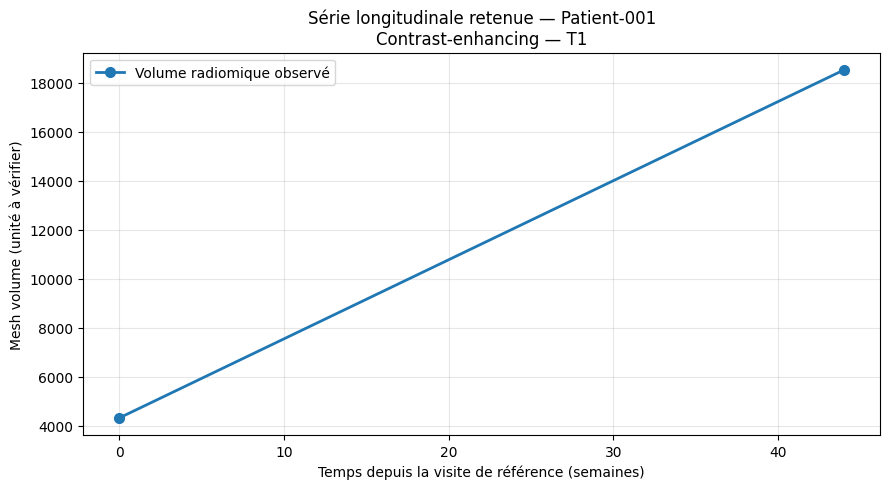

In [ ]:

# CELLULE 13 — Visualisation de la série postopératoire

plt.figure(figsize=(9, 5))

plt.plot(
    gompertz_data["t_weeks"],
    gompertz_data["Volume"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="Volume radiomique observé"
)

plt.xlabel("Temps depuis la visite de référence (semaines)")
plt.ylabel("Mesh volume (unité à vérifier)")
plt.title(
    f"Série longitudinale retenue — {PATIENT_ID}\n"
    f"{REGION} — {SEQUENCE}"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# CELLULE 3 — Recherche de la visite postopératoire

patient_ratings = expert_ratings[
    expert_ratings["Patient"] == PATIENT_ID
].copy()

rating_col = (
    "Rating (according to RANO, PD: Progressive disease, "
    "SD: Stable disease, PR: Partial response, "
    "CR: Complete response, Pre-Op: Pre-Operative, "
    "Post-Op: Post-Operative)"
)

print("Évaluations expertes :")
display(
    patient_ratings[["Patient", "Date", rating_col]]
    .sort_values("Date")
)

print("\nVisites avec volumes disponibles :")
display(volume_series[["Time point", "Week", "Volume"]])


Évaluations expertes :


,Patient,Date,"Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)"
0,Patient-001,week-000-1,Pre-Op
1,Patient-001,week-000-2,Post-Op
2,Patient-001,week-044,SD
3,Patient-001,week-056,PD



Visites avec volumes disponibles :


,Time point,Week,Volume
0,week-000-1,0,12777.791667
1,week-000-2,0,4322.166667
2,week-044,44,18522.666667


In [ ]:

# CELLULE 4 — Construction de la série postopératoire

# À REMPLACER par la visite Post-Op de Patient-067
BASELINE_TIMEPOINT = "REMPLACER_PAR_VISITE_POST_OP"

if BASELINE_TIMEPOINT not in volume_series["Time point"].values:
    raise ValueError(
        "La visite de référence n'existe pas dans les volumes. "
        "Vérifie le nom exact et la disponibilité de la séquence/région."
    )

baseline = volume_series[
    volume_series["Time point"] == BASELINE_TIMEPOINT
].iloc[0]

baseline_week = baseline["Week"]

# Conserver les mesures à partir de la visite postopératoire
postoperative_series = volume_series[
    (volume_series["Week"] > baseline_week) |
    (volume_series["Time point"] == BASELINE_TIMEPOINT)
].copy()

# Temps écoulé en semaines depuis la référence
postoperative_series["t_weeks"] = (
    postoperative_series["Week"] - baseline_week
)

# Une seule mesure par semaine pour la modélisation
gompertz_data = (
    postoperative_series
    .groupby("t_weeks", as_index=False)
    .agg(
        Volume=("Volume", "median"),
        Number_of_visits=("Time point", "count"),
        Timepoints=("Time point", lambda x: ", ".join(x))
    )
    .sort_values("t_weeks")
    .reset_index(drop=True)
)

display(gompertz_data)


ValueError: La visite de référence n'existe pas dans les volumes. Vérifie le nom exact et la disponibilité de la séquence/région.

In [ ]:

print("Visites disponibles dans volume_series :")
display(
    volume_series[["Time point", "Week", "Volume"]]
    .drop_duplicates()
    .sort_values(["Week", "Time point"])
    .reset_index(drop=True)
)

print("\nValeur actuelle de BASELINE_TIMEPOINT :")
print(repr(BASELINE_TIMEPOINT))


Visites disponibles dans volume_series :


,Time point,Week,Volume
0,week-000-1,0,12777.791667
1,week-000-2,0,4322.166667
2,week-044,44,18522.666667



Valeur actuelle de BASELINE_TIMEPOINT :
'REMPLACER_PAR_VISITE_POST_OP'


In [ ]:

ratings_patient = expert_ratings[
    expert_ratings["Patient"] == PATIENT_ID
].copy()

print("Évaluations disponibles pour", PATIENT_ID)

display(
    ratings_patient[
        ["Patient", "Date", "Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)"]
    ].sort_values("Date")
)


Évaluations disponibles pour Patient-001


,Patient,Date,"Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)"
0,Patient-001,week-000-1,Pre-Op
1,Patient-001,week-000-2,Post-Op
2,Patient-001,week-044,SD
3,Patient-001,week-056,PD


In [ ]:

PATIENT_ID = "Patient-067"

print("Patient sélectionné :", PATIENT_ID)

print("\nPatients présents dans les données radiomiques :")
print(features["Patient"].nunique())

print("\nCombinaisons disponibles pour ce patient :")
display(
    features[features["Patient"] == PATIENT_ID]
    [["Sequence", "Label name", "Time point"]]
    .drop_duplicates()
    .sort_values(["Sequence", "Label name", "Time point"])
    .head(30)
)


Patient sélectionné : Patient-067

Patients présents dans les données radiomiques :
91

Combinaisons disponibles pour ce patient :


,Sequence,Label name,Time point
5305,CT1,Contrast-enhancing,week-000-1
5317,CT1,Contrast-enhancing,week-000-2
5329,CT1,Contrast-enhancing,week-013
5341,CT1,Contrast-enhancing,week-019-2
5353,CT1,Contrast-enhancing,week-033
5365,CT1,Contrast-enhancing,week-042
5377,CT1,Contrast-enhancing,week-053
5389,CT1,Contrast-enhancing,week-059
5401,CT1,Contrast-enhancing,week-068
5413,CT1,Contrast-enhancing,week-073


In [ ]:

PATIENT_ID = "Patient-067"
SEQUENCE = "T1"
REGION = "Contrast-enhancing"

patient_data = features[
    (features["Patient"] == PATIENT_ID) &
    (features["Sequence"] == SEQUENCE) &
    (features["Label name"] == REGION)
].copy()

print("Patient :", PATIENT_ID)
print("Nombre de lignes :", len(patient_data))
print("Visites disponibles :")

display(
    patient_data[["Time point", "Sequence", "Label name"]]
    .drop_duplicates()
    .sort_values("Time point")
)


Patient : Patient-067
Nombre de lignes : 20
Visites disponibles :


,Time point,Sequence,Label name
5308,week-000-1,T1,Contrast-enhancing
5320,week-000-2,T1,Contrast-enhancing
5332,week-013,T1,Contrast-enhancing
5344,week-019-2,T1,Contrast-enhancing
5356,week-033,T1,Contrast-enhancing
5368,week-042,T1,Contrast-enhancing
5380,week-053,T1,Contrast-enhancing
5392,week-059,T1,Contrast-enhancing
5404,week-068,T1,Contrast-enhancing
5416,week-073,T1,Contrast-enhancing


In [ ]:

ratings_patient = expert_ratings[
    expert_ratings["Patient"] == PATIENT_ID
].copy()

rating_col = next(
    col for col in expert_ratings.columns
    if "Rating (according to RANO" in col
)

display(
    ratings_patient[["Patient", "Date", rating_col]]
    .sort_values("Date")
)


,Patient,Date,"Rating (according to RANO, PD: Progressive disease, SD: Stable disease, PR: Partial response, CR: Complete response, Pre-Op: Pre-Operative, Post-Op: Post-Operative)"
451,Patient-067,week-000-1,Pre-Op
452,Patient-067,week-000-2,Post-Op
453,Patient-067,week-013,PD
454,Patient-067,week-019-1,PD
455,Patient-067,week-019-2,Post-Op
456,Patient-067,week-033,PD
457,Patient-067,week-042,PD
458,Patient-067,week-053,PD
459,Patient-067,week-059,Post-Op
460,Patient-067,week-068,SD


In [ ]:

import pandas as pd
import numpy as np
import re

# Visite de référence après opération
BASELINE_TIMEPOINT = "week-059"

# Vérifier la colonne de volume
VOLUME_COL = "original_shape_MeshVolume"

if VOLUME_COL not in patient_data.columns:
    raise ValueError(
        f"Colonne {VOLUME_COL} introuvable. "
        "Vérifie les colonnes disponibles dans patient_data."
    )

# Extraire le numéro de semaine et l'ordre de visite
def parse_timepoint_local(value):
    match = re.search(r"week-(\d+)(?:-(\d+))?", str(value))
    if match is None:
        return pd.Series({"Week": np.nan, "Visit_order": np.nan})

    return pd.Series({
        "Week": int(match.group(1)),
        "Visit_order": int(match.group(2) or 0)
    })

# Préparer les mesures
postop_data = patient_data.copy()

postop_data[VOLUME_COL] = pd.to_numeric(
    postop_data[VOLUME_COL], errors="coerce"
)

postop_data = postop_data.dropna(
    subset=["Time point", VOLUME_COL]
)

parsed = postop_data["Time point"].apply(parse_timepoint_local)
postop_data[["Week", "Visit_order"]] = parsed

# Garder la période allant de week-059 à week-156 inclus
postop_data = postop_data[
    (postop_data["Week"] >= 59) &
    (postop_data["Week"] < 157)
].copy()

# Vérifier que la visite de référence existe
if BASELINE_TIMEPOINT not in postop_data["Time point"].values:
    raise ValueError(
        "La visite week-059 n'est pas disponible dans les mesures radiomiques."
    )

# Une mesure médiane par visite
volume_series = (
    postop_data
    .groupby(["Time point", "Week", "Visit_order"], as_index=False)
    [VOLUME_COL]
    .median()
    .rename(columns={VOLUME_COL: "Volume"})
    .sort_values(["Week", "Visit_order"])
    .reset_index(drop=True)
)

print("Série postopératoire construite :")
display(volume_series)

print("Nombre de visites :", len(volume_series))
print("Visite de référence :", BASELINE_TIMEPOINT)


Série postopératoire construite :


,Time point,Week,Visit_order,Volume
0,week-059,59,0,44540.375000
1,week-068,68,0,40602.833333
2,week-073,73,0,32030.916667
3,week-077,77,0,23064.833333
4,week-079,79,0,15748.666667
5,week-092,92,0,10345.875000
6,week-109,109,0,8733.541667
7,week-124,124,0,3757.666667
8,week-136,136,0,934.500000
9,week-152,152,0,2582.333333


Nombre de visites : 11
Visite de référence : week-059


In [ ]:

baseline_week = int(
    volume_series.loc[
        volume_series["Time point"] == BASELINE_TIMEPOINT,
        "Week"
    ].iloc[0]
)

gompertz_data = volume_series.copy()

gompertz_data["t_weeks"] = (
    gompertz_data["Week"] - baseline_week
)

gompertz_data = gompertz_data.sort_values("t_weeks")

t_data = gompertz_data["t_weeks"].to_numpy(dtype=float)
V_data = gompertz_data["Volume"].to_numpy(dtype=float)

print("Données préparées pour les modèles :")
display(gompertz_data)

print("\nNombre de mesures :", len(t_data))
print("Semaines :", t_data)
print("Volumes :", V_data)


Données préparées pour les modèles :


,Time point,Week,Visit_order,Volume,t_weeks
0,week-059,59,0,44540.375000,0
1,week-068,68,0,40602.833333,9
2,week-073,73,0,32030.916667,14
3,week-077,77,0,23064.833333,18
4,week-079,79,0,15748.666667,20
5,week-092,92,0,10345.875000,33
6,week-109,109,0,8733.541667,50
7,week-124,124,0,3757.666667,65
8,week-136,136,0,934.500000,77
9,week-152,152,0,2582.333333,93



Nombre de mesures : 11
Semaines : [ 0.  9. 14. 18. 20. 33. 50. 65. 77. 93. 97.]
Volumes : [44540.375      40602.83333333 32030.91666667 23064.83333333
 15748.66666667 10345.875       8733.54166667  3757.66666667
   934.5         2582.33333333  3101.5       ]


MODÈLE DE GOMPERTZ DÉCROISSANT
Paramètres : [1.00000000e+07 5.35346049e+00 6.53766566e-03]
RMSE : 3509.3672771578067
R² : 0.9463843798504834

MODÈLE LOGISTIQUE DÉCROISSANT
Paramètres : [4.61715243e+03 4.58535279e+04 2.33930827e-01 1.67570945e+01]
RMSE : 2453.929204757475
R² : 0.9737845239945219


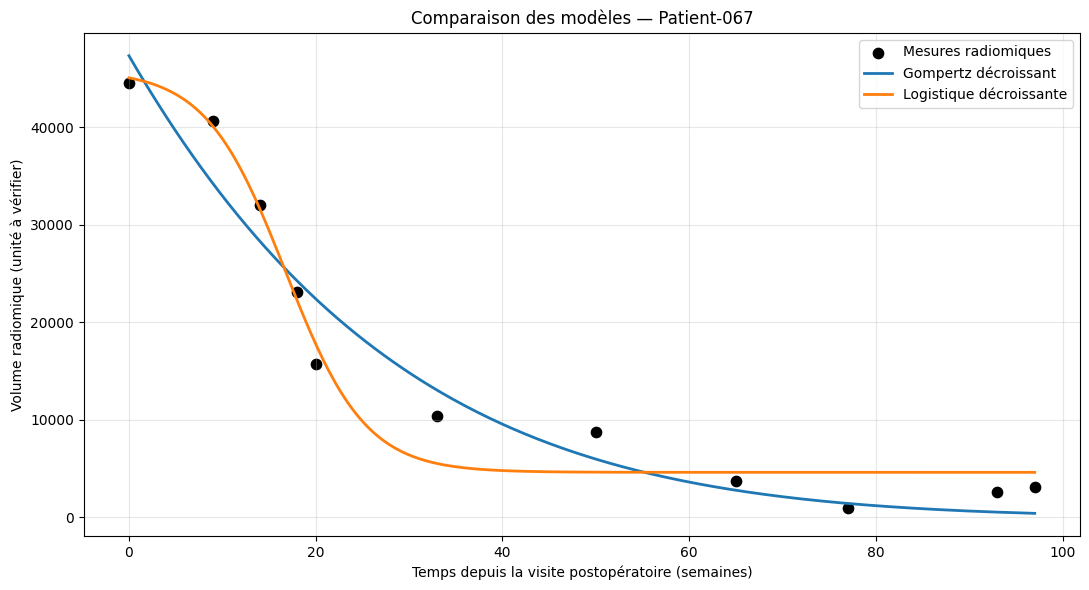

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score, mean_squared_error

# Modèle de Gompertz décroissant
def gompertz_decay(t, A, B, k):
    return A * np.exp(-B * np.exp(k * t))

# Modèle logistique décroissant
def logistic_decay(t, L, U, k, t0):
    return L + (U - L) / (1 + np.exp(k * (t - t0)))

# Ajustement Gompertz
popt_gompertz, _ = curve_fit(
    gompertz_decay,
    t_data,
    V_data,
    p0=[max(V_data), 0.1, 0.02],
    bounds=([1, 1e-6, 1e-6], [1e7, 10, 1])
)

# Ajustement logistique
popt_logistic, _ = curve_fit(
    logistic_decay,
    t_data,
    V_data,
    p0=[0, max(V_data), 0.05, np.median(t_data)],
    bounds=(
        [0, max(V_data), 1e-6, -100],
        [max(V_data), 1e7, 1, 300]
    ),
    maxfev=50000
)

# Prédictions aux temps observés
V_gompertz = gompertz_decay(t_data, *popt_gompertz)
V_logistic = logistic_decay(t_data, *popt_logistic)

# Indicateurs de qualité
def evaluate_model(observed, predicted):
    rmse = np.sqrt(mean_squared_error(observed, predicted))
    r2 = r2_score(observed, predicted)
    return rmse, r2

rmse_g, r2_g = evaluate_model(V_data, V_gompertz)
rmse_l, r2_l = evaluate_model(V_data, V_logistic)

print("MODÈLE DE GOMPERTZ DÉCROISSANT")
print("Paramètres :", popt_gompertz)
print("RMSE :", rmse_g)
print("R² :", r2_g)

print("\nMODÈLE LOGISTIQUE DÉCROISSANT")
print("Paramètres :", popt_logistic)
print("RMSE :", rmse_l)
print("R² :", r2_l)

# Visualisation
t_smooth = np.linspace(min(t_data), max(t_data), 300)

plt.figure(figsize=(11, 6))

plt.scatter(
    t_data, V_data,
    color="black", s=55,
    label="Mesures radiomiques"
)

plt.plot(
    t_smooth,
    gompertz_decay(t_smooth, *popt_gompertz),
    linewidth=2,
    label="Gompertz décroissant"
)

plt.plot(
    t_smooth,
    logistic_decay(t_smooth, *popt_logistic),
    linewidth=2,
    label="Logistique décroissante"
)

plt.xlabel("Temps depuis la visite postopératoire (semaines)")
plt.ylabel("Volume radiomique (unité à vérifier)")
plt.title("Comparaison des modèles — Patient-067")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


,Time point,t_weeks,Volume,Gompertz,Logistique,Résidu_Gompertz,Résidu_Logistique
0,week-059,0,44540.38,47317.48,45051.27,-2777.11,-510.90
1,week-068,9,40602.83,34207.21,40077.13,6395.63,525.71
2,week-073,14,32030.92,28325.67,31663.10,3705.25,367.82
3,week-077,18,23064.83,24247.90,22258.87,-1183.07,805.96
4,week-079,20,15748.67,22400.27,17769.37,-6651.61,-2020.70
5,week-092,33,10345.88,13037.83,5519.71,-2691.96,4826.17
6,week-109,50,8733.54,5971.63,4634.44,2761.91,4099.10
7,week-124,65,3757.67,2779.20,4617.67,978.47,-860.00
8,week-136,77,934.50,1424.63,4617.18,-490.13,-3682.68
9,week-152,93,2582.33,536.51,4617.15,2045.83,-2034.82


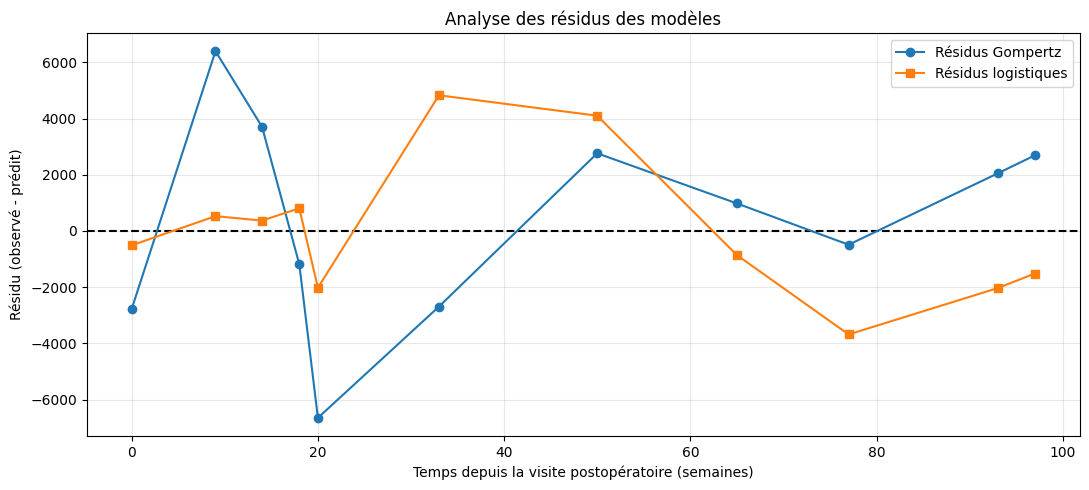

In [ ]:

# Prédictions et résidus
diagnostic = gompertz_data[
    ["Time point", "t_weeks", "Volume"]
].copy()

diagnostic["Gompertz"] = gompertz_decay(
    t_data, *popt_gompertz
)

diagnostic["Logistique"] = logistic_decay(
    t_data, *popt_logistic
)

diagnostic["Résidu_Gompertz"] = (
    diagnostic["Volume"] - diagnostic["Gompertz"]
)

diagnostic["Résidu_Logistique"] = (
    diagnostic["Volume"] - diagnostic["Logistique"]
)

display(diagnostic.round(2))

# Comparaison graphique des résidus
plt.figure(figsize=(11, 5))

plt.axhline(0, color="black", linestyle="--")

plt.plot(
    t_data,
    diagnostic["Résidu_Gompertz"],
    marker="o",
    label="Résidus Gompertz"
)

plt.plot(
    t_data,
    diagnostic["Résidu_Logistique"],
    marker="s",
    label="Résidus logistiques"
)

plt.xlabel("Temps depuis la visite postopératoire (semaines)")
plt.ylabel("Résidu (observé - prédit)")
plt.title("Analyse des résidus des modèles")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 20. Ajuster les modèles de croissance Gompertz et logistique

Les équations reprises dans le projet sont :
- Gompertz : \(dV/dt = rV\ln(K/V)\)
- Logistique : \(dV/dt = rV(1-V/K)\)

`r` est le taux de croissance et `K` la capacité limite. Les temps sont en jours et les volumes en mm³. L'ajustement n'est exécuté que si les observations réelles contiennent au moins trois temps distincts.

In [ ]:
def gompertz(t, r, K, V0):
    t = np.asarray(t, float)
    return K*np.exp(np.log(V0/K)*np.exp(-r*t))

def logistic(t, r, K, V0):
    t = np.asarray(t, float)
    return K/(1 + ((K-V0)/V0)*np.exp(-r*t))

def fit_growth(group):
    d = group.sort_values("time_days")
    t = d.time_days.to_numpy(float)
    v = d.volume_mm3.to_numpy(float)
    if len(np.unique(t)) < 3 or np.any(v <= 0):
        raise ValueError("Trois temps distincts et volumes positifs requis.")
    t = t - t.min()
    v0 = float(v[0])
    upper = max(float(v.max())*100, v0*10)
    fits = {}
    for name, fn in [("Gompertz", gompertz), ("Logistique", logistic)]:
        try:
            pars, _ = curve_fit(
                lambda tt, r, K: fn(tt, r, K, v0), t, v,
                p0=[0.01, max(v.max()*1.5, v0*1.1)],
                bounds=([1e-8, v0], [10, upper]), maxfev=50000
            )
            pred = fn(t, pars[0], pars[1], v0)
            fits[name] = {
                "r_per_day": float(pars[0]), "K_mm3": float(pars[1]),
                "rmse_mm3": float(np.sqrt(np.mean((v-pred)**2)))
            }
        except Exception as exc:
            fits[name] = {"error": str(exc)}
    return t, v, fits

growth_results = {}
if longitudinal_df is not None:
    for pid, group in longitudinal_df.groupby("patient_id"):
        if group.time_days.nunique() >= 3:
            try:
                growth_results[pid] = fit_growth(group)
            except Exception as exc:
                print(pid, "non ajusté :", exc)
print("Patients avec ajustement tenté :", len(growth_results))

Patients avec ajustement tenté : 0


## 21. Visualiser les courbes de croissance ajustées

Les points représentent les volumes observés ; les courbes représentent les ajustements. La RMSE est calculée sur les mêmes observations que celles utilisées pour ajuster les paramètres : elle ne constitue donc pas une validation prédictive indépendante.

In [ ]:
if growth_results:
    for pid, (t, v, fits) in list(growth_results.items())[:8]:
        grid = np.linspace(0, max(t), 150)
        plt.figure(figsize=(7, 4))
        plt.scatter(t, v, label="Volumes observés", zorder=3)
        for name, result in fits.items():
            if "error" not in result:
                fn = gompertz if name == "Gompertz" else logistic
                plt.plot(
                    grid, fn(grid, result["r_per_day"], result["K_mm3"], v[0]),
                    label=f"{name} · RMSE={result['rmse_mm3']:.2f}"
                )
        plt.title(f"Patient {pid}")
        plt.xlabel("Jours depuis le premier examen")
        plt.ylabel("Volume (mm³)")
        plt.legend(); plt.tight_layout(); plt.show()
else:
    print("Aucune courbe : renseigner une série longitudinale documentée.")

Aucune courbe : renseigner une série longitudinale documentée.


## 22. Définir le modèle linéaire-quadratique (LQ)

Le projet utilise :
- survie par fraction : \(S=\exp[-(\alpha d+\beta d^2)]\)
- dose biologiquement efficace : \(BED=nd(1+d/(\alpha/\beta))\)

Les paramètres dépendent du tissu, du protocole et de l'effet étudié. Ils restent donc vides. **Ne pas renseigner de valeurs arbitraires pour obtenir une courbe** : chaque paramètre et la limite de tissu sain doivent être justifiés par une référence scientifique adaptée.

In [ ]:
LQ = {
    "alpha_per_Gy": None,
    "beta_per_Gy2": None,
    "alpha_beta_normal_Gy": None,
    "n_fractions": None,
    "normal_tissue_BED_limit_Gy": None,
    "dose_min_Gy": None,
    "dose_max_Gy": None,
    "source_reference": None
}

def validate_lq(cfg):
    missing = [k for k, v in cfg.items() if v is None]
    if missing:
        raise ValueError("Paramètres LQ manquants : " + ", ".join(missing))
    for key in [
        "alpha_per_Gy", "beta_per_Gy2", "alpha_beta_normal_Gy",
        "normal_tissue_BED_limit_Gy", "dose_min_Gy", "dose_max_Gy"
    ]:
        if float(cfg[key]) <= 0:
            raise ValueError(f"{key} doit être > 0.")
    if int(cfg["n_fractions"]) < 1:
        raise ValueError("n_fractions doit être >= 1.")
    if cfg["dose_max_Gy"] < cfg["dose_min_Gy"]:
        raise ValueError("Bornes de dose incohérentes.")
    if not str(cfg["source_reference"]).strip():
        raise ValueError("Référence scientifique requise.")

def log_survival(d, alpha, beta):
    d = np.asarray(d, float)
    if np.any(d < 0):
        raise ValueError("Dose négative.")
    return -(alpha*d + beta*d*d)

def bed(doses, alpha_beta):
    doses = np.asarray(doses, float)
    return float(np.sum(doses*(1+doses/alpha_beta)))

try:
    validate_lq(LQ)
except ValueError as exc:
    print("Simulation bloquée volontairement :", exc)

Simulation bloquée volontairement : Paramètres LQ manquants : alpha_per_Gy, beta_per_Gy2, alpha_beta_normal_Gy, n_fractions, normal_tissue_BED_limit_Gy, dose_min_Gy, dose_max_Gy, source_reference


## 23. Simuler la croissance entre les fractions

Entre deux fractions, le volume suit l'ODE sélectionnée ; à chaque fraction, le facteur de survie LQ multiplie le volume. Cette simplification sert à comparer des scénarios mathématiques, et ne représente pas toute la réponse tumorale ni les contraintes cliniques.

In [ ]:
def grow_between(volume, dt, model, r, K):
    if volume <= 0:
        return 0.0
    if dt <= 0:
        return float(volume)
    if model == "Gompertz":
        rhs = lambda t, y: [r*y[0]*np.log(K/y[0])]
    elif model == "Logistique":
        rhs = lambda t, y: [r*y[0]*(1-y[0]/K)]
    else:
        raise ValueError("Modèle inconnu.")
    sol = solve_ivp(rhs, (0, dt), [volume], t_eval=[dt], rtol=1e-7, atol=1e-9)
    if not sol.success:
        raise RuntimeError(sol.message)
    return float(max(sol.y[0, -1], 0))

def simulate_schedule(v0, doses, times, model, r, K, alpha, beta):
    doses, times = np.asarray(doses, float), np.asarray(times, float)
    if len(doses) != len(times) or len(doses) == 0:
        raise ValueError("Doses et temps incohérents.")
    if np.any(np.diff(times) < 0) or times[0] < 0:
        raise ValueError("Temps non croissants.")
    v, last = float(v0), 0.0
    rows = [{"time_days": 0.0, "volume_mm3": v, "dose_Gy": 0.0}]
    for dose, time in zip(doses, times):
        v = grow_between(v, float(time-last), model, r, K)
        v *= float(np.exp(log_survival(dose, alpha, beta)))
        last = float(time)
        rows.append({"time_days": last, "volume_mm3": v, "dose_Gy": float(dose)})
    return pd.DataFrame(rows)

## 24. Optimiser un plan fixe — simulation uniquement

Le plan fixe choisit une dose identique à chaque fraction. L'objectif est de minimiser le volume final simulé sous une contrainte BED et des bornes de dose configurées. L'optimisation ne doit jamais être interprétée comme une prescription ou une recommandation thérapeutique.

In [ ]:
def optimize_fixed(v0, times, model, r, K, cfg):
    validate_lq(cfg)
    n = len(times)
    lo, hi = float(cfg["dose_min_Gy"]), float(cfg["dose_max_Gy"])
    abn = float(cfg["alpha_beta_normal_Gy"])

    def objective(x):
        doses = np.repeat(x[0], n)
        return simulate_schedule(
            v0, doses, times, model, r, K,
            cfg["alpha_per_Gy"], cfg["beta_per_Gy2"]
        ).iloc[-1].volume_mm3

    def constraint(x):
        return cfg["normal_tissue_BED_limit_Gy"] - bed(np.repeat(x[0], n), abn)

    result = minimize(
        objective, x0=[(lo+hi)/2], bounds=[(lo, hi)],
        constraints=[{"type": "ineq", "fun": constraint}], method="SLSQP"
    )
    if not result.success:
        raise RuntimeError("Optimisation fixe non convergée : " + result.message)
    doses = np.repeat(float(result.x[0]), n)
    return {
        "doses_Gy": doses, "BED_normal_Gy": bed(doses, abn),
        "simulation": simulate_schedule(
            v0, doses, times, model, r, K,
            cfg["alpha_per_Gy"], cfg["beta_per_Gy2"]
        )
    }

print("Fonction de plan fixe définie. Exécution possible uniquement après paramétrage LQ justifié.")

Fonction de plan fixe définie. Exécution possible uniquement après paramétrage LQ justifié.


## 25. Préparer une comparaison adaptative (facultative)

Une stratégie adaptative exige les volumes réellement observés aux dates de réévaluation, le calendrier exact des fractions et les paramètres LQ validés. Le notebook ne remplace pas une observation manquante par une valeur simulée.

In [ ]:
def estimate_growth(times, volumes, model):
    t, v = np.asarray(times, float), np.asarray(volumes, float)
    if len(t) < 3 or len(np.unique(t)) < 3 or np.any(v <= 0) or np.any(np.diff(t) <= 0):
        raise ValueError("Trois mesures réelles positives à temps croissants sont requises.")
    t = t-t[0]
    v0 = float(v[0])
    fn = gompertz if model == "Gompertz" else logistic
    pars, _ = curve_fit(
        lambda tt, r, K: fn(tt, r, K, v0), t, v,
        p0=[0.01, max(v.max()*1.5, v0*1.1)],
        bounds=([1e-8, v0], [10, max(v.max()*100, v0*10)]),
        maxfev=50000
    )
    return float(pars[0]), float(pars[1])

def optimize_remaining(v_current, remaining_times, delivered_doses,
                       model, r, K, cfg):
    validate_lq(cfg)
    abn = cfg["alpha_beta_normal_Gy"]
    remaining_bed = cfg["normal_tissue_BED_limit_Gy"] - bed(delivered_doses, abn)
    if remaining_bed < 0:
        raise ValueError("Limite BED déjà dépassée.")
    n = len(remaining_times)
    if n == 0:
        return np.array([])
    lo, hi = cfg["dose_min_Gy"], cfg["dose_max_Gy"]

    def objective(x):
        return simulate_schedule(
            v_current, x, remaining_times, model, r, K,
            cfg["alpha_per_Gy"], cfg["beta_per_Gy2"]
        ).iloc[-1].volume_mm3

    def constraint(x):
        return remaining_bed - bed(x, abn)

    res = minimize(
        objective, np.full(n, (lo+hi)/2), bounds=[(lo, hi)]*n,
        constraints=[{"type": "ineq", "fun": constraint}], method="SLSQP"
    )
    if not res.success:
        raise RuntimeError("Optimisation adaptative non convergée : " + res.message)
    return np.asarray(res.x, float)

print("Fonctions adaptatives définies ; elles nécessitent des observations réelles.")

Fonctions adaptatives définies ; elles nécessitent des observations réelles.


## 26. Configurer et exécuter la comparaison fixe/adaptative

Laissez les champs à `None` tant que les données et les paramètres ne sont pas confirmés. Les indices de réévaluation sont zéro-based (par exemple `2` désigne la troisième fraction). Les volumes de réévaluation doivent être des mesures réelles, en mm³.

In [ ]:
ADAPTIVE_PATIENT_ID = None
GROWTH_MODEL = "Gompertz"  # "Gompertz" ou "Logistique"
FRACTION_TIMES_DAYS = None
REASSESSMENT_AFTER_FRACTION = None
REASSESSMENT_VOLUMES_MM3 = None

def compare_fixed_adaptive(longitudinal, patient_id, cfg, times, model,
                           reassess_indices, reassess_volumes):
    validate_lq(cfg)
    if longitudinal is None:
        raise ValueError("Série longitudinale non disponible.")
    if patient_id not in set(longitudinal.patient_id):
        raise ValueError("Patient absent de la série longitudinale.")
    if model not in {"Gompertz", "Logistique"}:
        raise ValueError("Modèle inconnu.")
    if times is None:
        raise ValueError("Calendrier des fractions requis.")
    times = np.asarray(times, float)
    if len(times) != int(cfg["n_fractions"]):
        raise ValueError("Nombre de temps différent du nombre de fractions.")
    group = longitudinal[longitudinal.patient_id == patient_id].sort_values("time_days")
    if group.time_days.nunique() < 3:
        raise ValueError("Au moins trois examens datés réels sont requis.")
    if reassess_indices is None or reassess_volumes is None or len(reassess_indices) == 0:
        raise ValueError("Réévaluations et volumes réels requis.")
    if len(reassess_indices) != len(reassess_volumes):
        raise ValueError("Indices et volumes de réévaluation incohérents.")

    r, K = estimate_growth(group.time_days.to_numpy(), group.volume_mm3.to_numpy(), model)
    v0 = float(group.iloc[-1].volume_mm3)
    fixed = optimize_fixed(v0, times, model, r, K, cfg)
    adaptive = fixed["doses_Gy"].copy()

    for idx, observed in zip(reassess_indices, reassess_volumes):
        idx = int(idx)
        if idx < 0 or idx >= len(adaptive) or not np.isfinite(observed) or observed <= 0:
            raise ValueError("Réévaluation invalide.")
        delivered = adaptive[:idx+1].tolist()
        remaining = np.arange(idx+1, len(adaptive))
        if len(remaining):
            adaptive[remaining] = optimize_remaining(
                float(observed), times[remaining]-times[idx], delivered,
                model, r, K, cfg
            )
    adaptive_sim = simulate_schedule(
        v0, adaptive, times, model, r, K,
        cfg["alpha_per_Gy"], cfg["beta_per_Gy2"]
    )
    return fixed, adaptive, adaptive_sim

comparison = None
try:
    comparison = compare_fixed_adaptive(
        longitudinal_df, ADAPTIVE_PATIENT_ID, LQ, FRACTION_TIMES_DAYS,
        GROWTH_MODEL, REASSESSMENT_AFTER_FRACTION, REASSESSMENT_VOLUMES_MM3
    )
except Exception as exc:
    print("Comparaison non exécutée (configuration/données manquantes) :", exc)

## 27. Visualiser la comparaison des plans

Si tous les paramètres sont documentés, nous affichons les doses fraction par fraction et les volumes simulés. Sinon, le notebook conserve un message explicite : aucune comparaison n'est calculée à partir de données inventées.

In [ ]:
if comparison is not None:
    fixed, adaptive_doses, adaptive_sim = comparison
    display(pd.DataFrame({
        "fraction": np.arange(1, len(adaptive_doses)+1),
        "fixed_dose_Gy": fixed["doses_Gy"],
        "adaptive_dose_Gy": adaptive_doses
    }))
    plt.figure(figsize=(7, 4))
    plt.plot(fixed["simulation"].time_days, fixed["simulation"].volume_mm3,
             marker="o", label="Plan fixe")
    plt.plot(adaptive_sim.time_days, adaptive_sim.volume_mm3,
             marker="s", label="Plan adaptatif")
    plt.xlabel("Temps (jours)"); plt.ylabel("Volume simulé (mm³)")
    plt.title("Scénarios simulés — non cliniques")
    plt.legend(); plt.tight_layout(); plt.show()
else:
    print("Pas de courbes : paramètres LQ, calendrier ou observations manquants.")

## 28. Exporter les résultats dans le dossier du projet

Les tableaux sont enregistrés dans `MorphoRT/morphort_results` sur Google Drive. Les fichiers ne sont créés que si les résultats existent. Les exports distinguent les scores de segmentation, les mesures de forme et les mesures longitudinales.

In [ ]:
OUT = BASE_DIR / "morphort_results"
OUT.mkdir(exist_ok=True, parents=True)

def export_df(df, filename):
    if df is not None and not df.empty:
        path = OUT / filename
        df.to_csv(path, index=False)
        print("Exporté :", path)
    else:
        print("Non exporté (aucune donnée) :", filename)

export_df(validation_df, "brats_segmentation_validation.csv")
export_df(brats_metrics, "brats_morphology_metrics.csv")
export_df(ablation_df, "morphology_ablation_selected_case.csv")
export_df(sensitivity_df, "morphology_parameter_sensitivity.csv")
export_df(longitudinal_df, "lumiere_longitudinal_volumes.csv")

## 29. Bilan reproductible et limites à présenter au jury

Le bilan rapporte les effectifs réellement lus et les résultats réellement calculés. Pour la soutenance, insistez sur l'effet de chaque opération morphologique, l'impact du rayon de l'élément structurant et la comparaison à l'annotation experte.

**Limites à annoncer clairement :**
1. Le seuillage d'intensité est une baseline simple, sensible à la modalité et au quantile.
2. L'ouverture peut supprimer de petites régions tumorales ; la fermeture peut fusionner des régions proches.
3. La plus grande composante peut éliminer des foyers multifocaux.
4. Le remplissage 2D et le gradient ne décrivent pas exactement une surface tumorale 3D.
5. Un Dice élevé sur les patients de réglage ne remplace pas un test indépendant.
6. Une seule IRM ne permet pas d'ajuster un modèle temporel de croissance.
7. Les paramètres LQ et les contraintes radiobiologiques nécessitent des références précises ; les simulations ne sont pas des prescriptions.

In [ ]:
summary = {
    "BraTS_NIfTI_files": int(len(brats_inventory)) if not brats_inventory.empty else 0,
    "BraTS_cases_detected": int(len(brats_cases)),
    "BraTS_cases_with_FLAIR_and_GT": int(len(available_cases)),
    "BraTS_cases_evaluated": int(len(validation_df)),
    "LUMIERE_tables_read": int(len(lumiere_tables)),
    "LUMIERE_longitudinal_rows": 0 if longitudinal_df is None else int(len(longitudinal_df)),
    "growth_patient_fits": int(len(growth_results)),
    "selected_case": CASE_ID,
    "selected_case_final_mask_voxels": int(final_mask.sum()),
    "selected_case_final_mask_volume_mm3": float(final_mask.sum()*np.prod(spacing))
}
display(pd.Series(summary, name="Valeur").to_frame())
if not validation_df.empty:
    print("\\nMoyennes Dice sur les patients effectivement évalués :")
    display(validation_df[[c for c in validation_df if c.startswith("dice_")]].mean().to_frame("Dice moyen"))
print("\\nRésultats enregistrés dans :", OUT)

## 30. Références méthodologiques et traçabilité

**Document de référence du projet :** *MorphoRT — State of the Art: Mathematical Methodology and Medical Applications* (document fourni avec le notebook).

Le notebook suit l'enchaînement présenté dans ce document : segmentation morphologique des IRM (FLAIR/T1ce), mesures de volume et de forme, ajustement Gompertz/logistique sur données longitudinales, puis modèle LQ et comparaison de scénarios fixes/adaptatifs.

Les définitions des opérations morphologiques sont celles de la morphologie mathématique ensembliste. Pour la version finale du mémoire, ajouter les références précises justifiant les choix de seuils, les paramètres de croissance et les paramètres radiobiologiques. Les résultats produits ici sont expérimentaux et non cliniques.

In [ ]:

# ============================================================
# MORPHORT WEB — INSTALLATION
# ============================================================

!pip install -q gradio nibabel scipy scikit-image pandas matplotlib

print("Installation terminée.")


Installation terminée.


In [ ]:

# ============================================================
# MORPHORT WEB — FONCTIONS SCIENTIFIQUES
# ============================================================

import os
import tempfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr
import nibabel as nib

from scipy import ndimage as ndi
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. DONNEES DE DEMONSTRATION : PATIENT-067
# ------------------------------------------------------------

DEMO_DATA = pd.DataFrame({
    "Time point": [
        "week-059", "week-068", "week-073", "week-077",
        "week-079", "week-092", "week-109", "week-124",
        "week-136", "week-152", "week-156"
    ],
    "t_weeks": [0, 9, 14, 18, 20, 33, 50, 65, 77, 93, 97],
    "Volume": [
        44540.375, 40602.833333, 32030.916667,
        23064.833333, 15748.666667, 10345.875,
        8733.541667, 3757.666667, 934.5,
        2582.333333, 3101.5
    ]
})

# ------------------------------------------------------------
# 2. MODELES MATHEMATIQUES DECROISSANTS
# ------------------------------------------------------------

def gompertz_decay(t, A, B, k):
    return A * np.exp(-B * np.exp(k * t))


def logistic_decay(t, L, U, k, t0):
    return L + (U - L) / (1 + np.exp(k * (t - t0)))


def fit_growth_models(data):

    t = data["t_weeks"].to_numpy(dtype=float)
    v = data["Volume"].to_numpy(dtype=float)

    if len(t) < 4 or np.any(v <= 0):
        raise ValueError(
            "Il faut au moins quatre mesures et des volumes positifs."
        )

    results = {}

    # Gompertz
    try:
        pg, _ = curve_fit(
            gompertz_decay,
            t, v,
            p0=[max(v), 1, 0.02],
            bounds=([1, 1e-6, 1e-6], [1e7, 10, 1]),
            maxfev=50000
        )
        pred_g = gompertz_decay(t, *pg)

        results["Gompertz"] = {
            "params": pg,
            "prediction": pred_g,
            "RMSE": np.sqrt(mean_squared_error(v, pred_g)),
            "R2": r2_score(v, pred_g),
            "warning": bool(np.isclose(pg[0], 1e7, rtol=1e-4))
        }
    except Exception as e:
        results["Gompertz"] = {"error": str(e)}

    # Logistique
    try:
        pl, _ = curve_fit(
            logistic_decay,
            t, v,
            p0=[0, max(v), 0.05, np.median(t)],
            bounds=(
                [0, max(v), 1e-6, -100],
                [max(v), 1e7, 1, 300]
            ),
            maxfev=50000
        )
        pred_l = logistic_decay(t, *pl)

        results["Logistique"] = {
            "params": pl,
            "prediction": pred_l,
            "RMSE": np.sqrt(mean_squared_error(v, pred_l)),
            "R2": r2_score(v, pred_l),
            "warning": False
        }
    except Exception as e:
        results["Logistique"] = {"error": str(e)}

    return results


# ------------------------------------------------------------
# 3. ANALYSE LONGITUDINALE ET GRAPHIQUES
# ------------------------------------------------------------

def longitudinal_analysis(csv_file=None):

    if csv_file is None:
        data = DEMO_DATA.copy()
        source = "Données de démonstration Patient-067"
    else:
        data = pd.read_csv(csv_file)
        if not {"t_weeks", "Volume"}.issubset(data.columns):
            raise ValueError(
                "Le CSV doit contenir les colonnes t_weeks et Volume."
            )
        data = data[["t_weeks", "Volume"]].copy()
        data["t_weeks"] = pd.to_numeric(
            data["t_weeks"], errors="coerce"
        )
        data["Volume"] = pd.to_numeric(
            data["Volume"], errors="coerce"
        )
        data = data.dropna().sort_values("t_weeks")
        source = "Fichier CSV importé"

    results = fit_growth_models(data)

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.scatter(
        data["t_weeks"], data["Volume"],
        color="black", s=55, label="Mesures observées"
    )

    t_smooth = np.linspace(
        data["t_weeks"].min(),
        data["t_weeks"].max(), 300
    )

    if "error" not in results["Gompertz"]:
        p = results["Gompertz"]["params"]
        ax.plot(
            t_smooth, gompertz_decay(t_smooth, *p),
            label="Gompertz décroissant", linewidth=2
        )

    if "error" not in results["Logistique"]:
        p = results["Logistique"]["params"]
        ax.plot(
            t_smooth, logistic_decay(t_smooth, *p),
            label="Logistique décroissante", linewidth=2
        )

    ax.set_title("MorphoRT — Évolution longitudinale")
    ax.set_xlabel("Temps depuis la référence (semaines)")
    ax.set_ylabel("Volume radiomique (unité à vérifier)")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    metrics = []
    for name, result in results.items():
        if "error" not in result:
            metrics.append({
                "Modèle": name,
                "RMSE": round(result["RMSE"], 2),
                "R²": round(result["R2"], 4),
                "Avertissement": (
                    "Paramètre à la borne" if result["warning"] else ""
                )
            })

    metrics_df = pd.DataFrame(metrics)

    report = (
        f"**Source :** {source}\n\n"
        f"**Nombre de mesures :** {len(data)}\n\n"
        "Les résultats sont exploratoires. Le meilleur R² ou RMSE "
        "ne suffit pas à établir la validité biologique d'un modèle."
    )

    return fig, metrics_df, data, report


# ------------------------------------------------------------
# 4. LECTURE ET SEGMENTATION MORPHOLOGIQUE 3D
# ------------------------------------------------------------

def largest_component(mask):

    labels, n = ndi.label(mask)

    if n == 0:
        return mask

    counts = np.bincount(labels.ravel())
    counts[0] = 0

    return labels == np.argmax(counts)


def segment_mri(
    mri_file,
    operation,
    quantile,
    radius,
    expert_file=None
):

    if mri_file is None:
        raise ValueError("Importe d'abord un fichier IRM NIfTI.")

    image = nib.load(mri_file)
    volume = image.get_fdata(dtype=np.float32)

    if volume.ndim == 4:
        volume = volume[..., 0]

    if volume.ndim != 3:
        raise ValueError("Le fichier doit contenir un volume 3D.")

    finite = np.isfinite(volume)
    positive = volume[finite & (volume > 0)]

    if len(positive) == 0:
        raise ValueError("Le volume ne contient pas de signal positif exploitable.")

    threshold = np.quantile(positive, float(quantile))
    mask = finite & (volume >= threshold)

    structure = ndi.generate_binary_structure(3, 1)
    radius = int(radius)

    if operation == "Ouverture + fermeture":
        mask = ndi.binary_opening(
            mask, structure=structure, iterations=radius
        )
        mask = ndi.binary_closing(
            mask, structure=structure, iterations=radius
        )

    elif operation == "Erosion":
        mask = ndi.binary_erosion(
            mask, structure=structure, iterations=radius
        )

    elif operation == "Dilatation":
        mask = ndi.binary_dilation(
            mask, structure=structure, iterations=radius
        )

    elif operation == "Gradient morphologique":
        dilated = ndi.binary_dilation(
            mask, structure=structure, iterations=radius
        )
        eroded = ndi.binary_erosion(
            mask, structure=structure, iterations=radius
        )
        mask = dilated & ~eroded

    if operation != "Gradient morphologique":
        mask = largest_component(mask)

    voxel_count = int(mask.sum())

    zooms = image.header.get_zooms()[:3]
    voxel_volume = float(np.prod(zooms))
    physical_volume = voxel_count * voxel_volume

    units = image.header.get_xyzt_units()[0]
    unit_label = "mm³ (à confirmer)" if units == "mm" else (
        f"unité spatiale : {units or 'inconnue'}"
    )

    # Coupe axiale centrale
    z = volume.shape[2] // 2
    original_slice = volume[:, :, z]
    mask_slice = mask[:, :, z]

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(original_slice.T, cmap="gray", origin="lower")
    ax.imshow(
        np.ma.masked_where(~mask_slice.T, mask_slice.T),
        cmap="autumn", alpha=0.45, origin="lower"
    )
    ax.set_title("IRM et masque morphologique — coupe axiale")
    ax.axis("off")
    fig.tight_layout()

    dice_text = "Masque expert non fourni."

    if expert_file is not None:
        expert_image = nib.load(expert_file)
        expert = expert_image.get_fdata()

        if expert.ndim == 4:
            expert = expert[..., 0]

        if expert.shape != mask.shape:
            raise ValueError(
                "Le masque expert et l'IRM n'ont pas la même dimension. "
                "Ils doivent être recalés sur la même grille."
            )

        expert = expert > 0

        intersection = np.logical_and(mask, expert).sum()
        denominator = mask.sum() + expert.sum()

        dice = (
            2 * intersection / denominator
            if denominator > 0 else 1.0
        )

        dice_text = f"Dice avec le masque expert : {dice:.4f}"

    report = (
        f"**Seuil appliqué :** {threshold:.4f}\n\n"
        f"**Nombre de voxels du masque :** {voxel_count:,}\n\n"
        f"**Volume calculé :** {physical_volume:,.2f} "
        f"{unit_label}\n\n"
        f"**Opération :** {operation}\n\n"
        f"**{dice_text}**\n\n"
        "Attention : le seuil et les opérations morphologiques "
        "produisent un masque exploratoire, pas un diagnostic tumoral."
    )

    return fig, report


# ------------------------------------------------------------
# 5. SIMULATION PEDAGOGIQUE DE RADIOTHERAPIE
# ------------------------------------------------------------

def radiotherapy_simulation(
    total_dose,
    fractions,
    alpha,
    alpha_beta,
    growth_rate
):

    fractions = int(fractions)

    if fractions < 1 or alpha <= 0 or alpha_beta <= 0:
        raise ValueError("Vérifie les paramètres de simulation.")

    beta = alpha / alpha_beta
    base_dose = total_dose / fractions

    # Répartition fixe
    fixed_doses = np.full(fractions, base_dose)

    # Répartition adaptative illustrative :
    # pondération plus importante au début de la simulation.
    weights = np.exp(-growth_rate * np.arange(fractions))
    adaptive_doses = total_dose * weights / weights.sum()

    fixed_volume = 100.0
    adaptive_volume = 100.0

    fixed_values = [fixed_volume]
    adaptive_values = [adaptive_volume]

    rows = []

    for i in range(fractions):

        df = fixed_doses[i]
        da = adaptive_doses[i]

        sf = np.exp(-(alpha * df + beta * df**2))
        sa = np.exp(-(alpha * da + beta * da**2))

        fixed_volume *= sf
        adaptive_volume *= sa

        fixed_values.append(fixed_volume)
        adaptive_values.append(adaptive_volume)

        rows.append({
            "Fraction": i + 1,
            "Dose fixe (Gy)": round(df, 3),
            "Dose adaptative (Gy)": round(da, 3),
            "Volume relatif fixe (%)": round(fixed_volume, 4),
            "Volume relatif adaptatif (%)": round(adaptive_volume, 4)
        })

    df_results = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        range(fractions + 1), fixed_values,
        marker="o", label="Schéma fixe"
    )
    ax.plot(
        range(fractions + 1), adaptive_values,
        marker="s", label="Schéma adaptatif simulé"
    )

    ax.set_xlabel("Nombre de fractions")
    ax.set_ylabel("Survie cellulaire relative (%)")
    ax.set_title("Simulation mathématique — modèle linéaire-quadratique")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    report = (
        "**Simulation théorique uniquement.** Les doses sont réparties "
        "mathématiquement selon deux schémas. Ce calcul ne tient pas "
        "compte de la géométrie réelle de la tumeur, des organes à risque, "
        "des contraintes cliniques ni de la planification dosimétrique. "
        "Il ne constitue pas une recommandation de traitement."
    )

    return fig, df_results, report


In [ ]:

# ============================================================
# MORPHORT WEB — INTERFACE GRADIO
# ============================================================

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="MorphoRT — Brain Tumor Research Platform"
) as demo:

    gr.Markdown(
        """
        # 🧠 MorphoRT
        ### Morphology-Aware Tumor Growth Modeling and Adaptive Radiotherapy

        Plateforme de recherche et de démonstration :
        segmentation morphologique, analyse longitudinale,
        modélisation mathématique et simulation radiothérapeutique.
        """
    )

    gr.Markdown(
        """
        <div style="padding:12px; border-radius:10px;
        background:#fff3cd; color:#664d03;">
        <b>Version de recherche :</b> les résultats sont exploratoires.
        Cette application ne constitue pas un dispositif médical
        et ne doit pas être utilisée pour prendre des décisions thérapeutiques.
        </div>
        """
    )

    with gr.Tabs():

        # ====================================================
        # ONGLET 1 : DASHBOARD / DEMONSTRATION
        # ====================================================

        with gr.Tab("🏠 Tableau de bord"):

            gr.Markdown("## Présentation du projet MorphoRT")

            gr.Markdown(
                """
                Cette plateforme regroupe quatre étapes :

                1. **IRM et morphologie mathématique** : exploration
                   des volumes IRM et visualisation des opérations.
                2. **Analyse longitudinale** : étude des variations
                   de volume radiomique.
                3. **Modélisation** : comparaison de Gompertz
                   et du modèle logistique.
                4. **Radiothérapie** : simulation mathématique
                   de schémas de fractions.
                """
            )

            gr.Markdown("### Démonstration — Patient-067")

            demo_button = gr.Button(
                "Afficher les résultats de démonstration",
                variant="primary"
            )

            demo_plot = gr.Plot(label="Évolution longitudinale")
            demo_metrics = gr.Dataframe(
                label="Comparaison des modèles",
                interactive=False
            )
            demo_table = gr.Dataframe(
                label="Mesures radiomiques",
                interactive=False
            )
            demo_report = gr.Markdown()

            demo_button.click(
                fn=longitudinal_analysis,
                inputs=[],
                outputs=[
                    demo_plot,
                    demo_metrics,
                    demo_table,
                    demo_report
                ]
            )

        # ====================================================
        # ONGLET 2 : IRM ET SEGMENTATION
        # ====================================================

        with gr.Tab("🧲 IRM & Segmentation"):

            gr.Markdown("## Exploration morphologique des IRM")

            gr.Markdown(
                """
                Importe un volume IRM au format `.nii` ou `.nii.gz`.
                Le masque est obtenu par seuillage du signal et
                opérations morphologiques 3D.
                """
            )

            mri_input = gr.File(
                label="Importer le volume IRM NIfTI",
                file_types=[".nii", ".nii.gz"],
                type="filepath"
            )

            expert_input = gr.File(
                label="Masque expert facultatif (.nii ou .nii.gz)",
                file_types=[".nii", ".nii.gz"],
                type="filepath"
            )

            operation_input = gr.Dropdown(
                choices=[
                    "Ouverture + fermeture",
                    "Erosion",
                    "Dilatation",
                    "Gradient morphologique"
                ],
                value="Ouverture + fermeture",
                label="Opération morphologique"
            )

            quantile_input = gr.Slider(
                minimum=0.50,
                maximum=0.99,
                value=0.85,
                step=0.01,
                label="Quantile du seuil d'intensité"
            )

            radius_input = gr.Slider(
                minimum=1,
                maximum=3,
                value=1,
                step=1,
                label="Nombre d'itérations morphologiques"
            )

            segment_button = gr.Button(
                "Lancer l'analyse morphologique",
                variant="primary"
            )

            segmentation_plot = gr.Plot(
                label="Visualisation IRM et masque"
            )

            segmentation_report = gr.Markdown()

            segment_button.click(
                fn=segment_mri,
                inputs=[
                    mri_input,
                    operation_input,
                    quantile_input,
                    radius_input,
                    expert_input
                ],
                outputs=[
                    segmentation_plot,
                    segmentation_report
                ]
            )

        # ====================================================
        # ONGLET 3 : ANALYSE LONGITUDINALE
        # ====================================================

        with gr.Tab("📈 Modélisation longitudinale"):

            gr.Markdown("## Modélisation mathématique de l'évolution")

            gr.Markdown(
                """
                Par défaut, l'application utilise les mesures
                radiomiques de démonstration de Patient-067.

                Tu peux également importer un CSV contenant deux colonnes :
                `t_weeks` et `Volume`.
                """
            )

            csv_input = gr.File(
                label="Importer un CSV longitudinal (facultatif)",
                file_types=[".csv"],
                type="filepath"
            )

            longitudinal_button = gr.Button(
                "Analyser les données",
                variant="primary"
            )

            longitudinal_plot = gr.Plot(
                label="Comparaison Gompertz / Logistique"
            )

            longitudinal_metrics = gr.Dataframe(
                label="Indicateurs de performance",
                interactive=False
            )

            longitudinal_table = gr.Dataframe(
                label="Données utilisées",
                interactive=False
            )

            longitudinal_report = gr.Markdown()

            longitudinal_button.click(
                fn=longitudinal_analysis,
                inputs=[csv_input],
                outputs=[
                    longitudinal_plot,
                    longitudinal_metrics,
                    longitudinal_table,
                    longitudinal_report
                ]
            )

        # ====================================================
        # ONGLET 4 : RADIOTHERAPIE
        # ====================================================

        with gr.Tab("☢️ Radiothérapie"):

            gr.Markdown("## Simulation mathématique de radiothérapie")

            gr.Markdown(
                """
                Comparaison pédagogique d'un schéma à dose fixe
                et d'une répartition adaptative illustrative,
                à partir du modèle linéaire-quadratique.
                """
            )

            total_dose_input = gr.Slider(
                minimum=10,
                maximum=80,
                value=60,
                step=1,
                label="Dose physique totale simulée (Gy)"
            )

            fractions_input = gr.Slider(
                minimum=5,
                maximum=40,
                value=30,
                step=1,
                label="Nombre de fractions"
            )

            alpha_input = gr.Slider(
                minimum=0.01,
                maximum=0.50,
                value=0.15,
                step=0.01,
                label="Paramètre alpha (Gy⁻¹)"
            )

            alpha_beta_input = gr.Slider(
                minimum=1,
                maximum=20,
                value=10,
                step=0.5,
                label="Rapport alpha/beta (Gy)"
            )

            growth_rate_input = gr.Slider(
                minimum=0.001,
                maximum=0.15,
                value=0.03,
                step=0.001,
                label="Paramètre de pondération adaptative"
            )

            radio_button = gr.Button(
                "Lancer la simulation",
                variant="primary"
            )

            radio_plot = gr.Plot(
                label="Comparaison des schémas simulés"
            )

            radio_table = gr.Dataframe(
                label="Doses et volumes relatifs par fraction",
                interactive=False
            )

            radio_report = gr.Markdown()

            radio_button.click(
                fn=radiotherapy_simulation,
                inputs=[
                    total_dose_input,
                    fractions_input,
                    alpha_input,
                    alpha_beta_input,
                    growth_rate_input
                ],
                outputs=[
                    radio_plot,
                    radio_table,
                    radio_report
                ]
            )

    gr.Markdown(
        """
        ---
        **MorphoRT — Projet de recherche académique**

        Segmentation morphologique • Radiomique •
        Modèles de croissance • Simulation radiothérapeutique
        """
    )

print("Interface MorphoRT construite.")


Interface MorphoRT construite.


In [ ]:

# ============================================================
# MORPHORT WEB — LANCEMENT
# ============================================================

demo.queue()

demo.launch(
    share=True,
    debug=True,
    show_error=True
)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://77cbfd0f64ec7b96ba.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
